# Fraud-Risk Intelligence Pipeline: calibrated probability, Approve / Review / Block decision, explanation

**Goal.** Build and validate a production-oriented fraud decision engine on `transaction_fraud_risk_advanced_dataset.csv`
(3,000 card / online transactions, 24 features, binary label `fraud`).

**Design principles (from the brief)**
* The **final test set (20 %) is touched once**, for the final evaluation, stress tests and bootstrap CIs. It is never used for feature selection, tuning, calibration fitting, threshold optimisation or resampling.
* Everything that learns from data (group statistics, imputation, scaling, encoding, SMOTE / under-sampling) is **inside the pipeline**, so it is fitted on training folds only.
* Fixed seed `SEED = 42` everywhere. No observations are removed to improve metrics.
* Every cost assumption is explicit and sensitivity-tested.
* Reusable code lives in `fraud_lib.py` (feature engineer, pipelines, cost engine, PSI) so that the `.joblib` files can be loaded.

**Sections:** A data forensics, B EDA, C feature engineering, D models, G imbalance, F calibration, E cost-sensitive thresholds, I operations simulation, H explainability, J robustness, K governance and exports.

In [1]:
import warnings, json, os, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import logit
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_recall_curve, precision_score, recall_score, f1_score)
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import joblib, shap

from fraud_lib import *

SEED = 42
np.random.seed(SEED)
DATA = "transaction_fraud_risk_advanced_dataset.csv"
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
R = {}            # every number quoted in the PDF reports is stored here -> results.json
C_FRAUD, C_OK, C_GREY = "#c0392b", "#2c6e91", "#8a8f98"
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 50)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print({k: v for k, v in [("numpy", np.__version__), ("pandas", pd.__version__)]})

{'numpy': '2.5.3', 'pandas': '3.0.5'}


## A. Data forensics and quality engineering
### A1. Schema, missingness, duplicates, cardinality

In [2]:
raw = pd.read_csv(DATA)
print("shape:", raw.shape)
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str), "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(2), "n_unique": raw.nunique(),
})
display(schema)
dup_id = int(raw[ID_COL].duplicated().sum())
dup_rows = int(raw.drop(columns=[ID_COL]).duplicated().sum())
n_pos = int(raw[TARGET].sum())
print(f"duplicate transaction ids: {dup_id} | duplicate rows (ignoring id): {dup_rows}")
print(f"fraud: {n_pos} / {len(raw)} = {raw[TARGET].mean():.2%}  (imbalance ratio 1 : {(len(raw)-n_pos)/n_pos:.1f})")
R["n_rows"] = len(raw); R["n_fraud"] = n_pos; R["fraud_rate"] = float(raw[TARGET].mean())
R["imbalance_ratio"] = float((len(raw) - n_pos) / n_pos); R["dup_id"] = dup_id; R["dup_rows"] = dup_rows
R["missing_cols"] = {c: int(v) for c, v in raw.isna().sum().items() if v > 0}

shape: (3000, 25)


,dtype,n_missing,pct_missing,n_unique
transaction_id,str,0,0.00,3000
hour,int64,0,0.00,24
day_of_week,int64,0,0.00,7
transaction_amount,float64,53,1.77,2779
distance_from_usual_location_km,float64,75,2.50,2402
transactions_last_1h,int64,0,0.00,11
transactions_last_24h,int64,0,0.00,25
account_age_days,int64,0,0.00,1464
failed_logins_24h,int64,0,0.00,4
prior_chargebacks,int64,0,0.00,4


duplicate transaction ids: 0 | duplicate rows (ignoring id): 0
fraud: 364 / 3000 = 12.13%  (imbalance ratio 1 : 7.2)


### A2. Impossible / suspicious values and extreme observations

In [3]:
r = raw
checks = {
    "amount <= 0": (r.transaction_amount <= 0).sum(),
    "hour outside 0-23": ((r.hour < 0) | (r.hour > 23)).sum(),
    "day_of_week outside 0-6": ((r.day_of_week < 0) | (r.day_of_week > 6)).sum(),
    "txns_last_1h > txns_last_24h (logically impossible)": (r.transactions_last_1h > r.transactions_last_24h).sum(),
    "risk score outside [0,1]": (((r.merchant_risk_score < 0) | (r.merchant_risk_score > 1)) | ((r.ip_risk_score < 0) | (r.ip_risk_score > 1))).sum(),
    "negative counts / ages / minutes": (r[["transactions_last_1h", "transactions_last_24h", "account_age_days", "device_age_days",
                                              "email_age_days", "failed_logins_24h", "prior_chargebacks", "login_to_transaction_minutes",
                                              "distance_from_usual_location_km"]] < 0).any(axis=1).sum(),
    "device_age_days > account_age_days (suspicious)": (r.device_age_days > r.account_age_days).sum(),
    "new_device = 1 but device_age_days > 30 (inconsistent)": ((r.new_device == 1) & (r.device_age_days > 30)).sum(),
    "email_age_days < account_age_days": (r.email_age_days < r.account_age_days).sum(),
    "transactions_last_24h > 30 (extreme)": (r.transactions_last_24h > 30).sum(),
    "login_to_transaction_minutes = 120 (looks capped)": (r.login_to_transaction_minutes >= 120).sum(),
}
impossible = pd.Series(checks, name="n_rows").astype(int).to_frame()
impossible["pct"] = (impossible.n_rows / len(raw) * 100).round(2)
display(impossible)
R["impossible"] = {k: int(v) for k, v in checks.items()}

num_cols = [c for c in NUM_RAW if c not in ("hour", "day_of_week", "new_device", "billing_address_mismatch")]
ext = []
for c in num_cols:
    s = raw[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    ext.append(dict(feature=c, median=s.median(), p99=s.quantile(.99), max=s.max(),
                    max_over_median=s.max() / s.median() if s.median() else np.nan,
                    n_beyond_3IQR=int(((s > q3 + 3 * iqr) | (s < q1 - 3 * iqr)).sum()), skew=s.skew()))
extremes = pd.DataFrame(ext).round(3); display(extremes)
R["extremes"] = extremes.set_index("feature")[["max", "n_beyond_3IQR", "skew"]].to_dict("index")

,n_rows,pct
amount <= 0,0,0.00
hour outside 0-23,0,0.00
day_of_week outside 0-6,0,0.00
txns_last_1h > txns_last_24h (logically impossible),0,0.00
"risk score outside [0,1]",0,0.00
negative counts / ages / minutes,0,0.00
device_age_days > account_age_days (suspicious),1240,41.33
new_device = 1 but device_age_days > 30 (inconsistent),490,16.33
email_age_days < account_age_days,639,21.30
transactions_last_24h > 30 (extreme),6,0.20


,feature,median,p99,max,max_over_median,n_beyond_3IQR,skew
0,transaction_amount,88.390,679.186,5538.152,62.656,63,15.451
1,distance_from_usual_location_km,29.970,125.674,1173.269,39.148,18,14.624
2,transactions_last_1h,2.000,6.000,10.000,5.000,1,0.726
3,transactions_last_24h,7.000,15.000,113.000,16.143,6,13.177
4,account_age_days,887.000,1778.010,1799.000,2.028,0,0.014
5,failed_logins_24h,0.000,2.000,3.000,NaN,0,1.664
6,prior_chargebacks,0.000,1.000,3.000,NaN,352,2.795
7,device_age_days,741.500,1480.010,1499.000,2.022,0,0.019
8,merchant_risk_score,0.285,0.712,0.818,2.870,0,0.521
9,ip_risk_score,0.206,0.615,0.738,3.583,0,0.749


### A3. Is missingness itself informative?
For every column with missing values: fraud rate when missing vs observed, with Fisher exact test. We also check whether missingness depends on other columns (MAR vs MCAR).

In [4]:
rows = []
for c in raw.columns[raw.isna().any()]:
    m = raw[c].isna()
    tab = [[int(raw.loc[m, TARGET].sum()), int((1 - raw.loc[m, TARGET]).sum())],
           [int(raw.loc[~m, TARGET].sum()), int((1 - raw.loc[~m, TARGET]).sum())]]
    odds, p = stats.fisher_exact(tab)
    rows.append(dict(feature=c, n_missing=int(m.sum()), fraud_rate_missing=raw.loc[m, TARGET].mean(),
                     fraud_rate_observed=raw.loc[~m, TARGET].mean(), odds_ratio=odds, fisher_p=p))
miss_df = pd.DataFrame(rows).round(4); display(miss_df)
R["missing_signal"] = miss_df.set_index("feature").to_dict("index")
# does missingness depend on channel? (chi-square)
for c in ["authentication_level", "transaction_amount"]:
    ct = pd.crosstab(raw["channel"], raw[c].isna()); chi = stats.chi2_contingency(ct)
    print(f"missing({c}) vs channel: chi2 p = {chi[1]:.3f}")
any_miss = raw.drop(columns=[TARGET]).isna().any(axis=1)
print("rows with >=1 missing value:", int(any_miss.sum()), f"fraud rate {raw.loc[any_miss, TARGET].mean():.3f} vs {raw.loc[~any_miss, TARGET].mean():.3f}")

,feature,n_missing,fraud_rate_missing,fraud_rate_observed,odds_ratio,fisher_p
0,transaction_amount,53,0.0943,0.1218,0.7509,0.6740
1,distance_from_usual_location_km,75,0.0533,0.1231,0.4014,0.0727
2,merchant_risk_score,60,0.0333,0.1231,0.2456,0.0281
3,ip_risk_score,45,0.1111,0.1215,0.9039,1.0000
4,login_to_transaction_minutes,60,0.1167,0.1214,0.9556,1.0000
5,authentication_level,289,0.1903,0.1140,1.8271,0.0004


missing(authentication_level) vs channel: chi2 p = 0.886
missing(transaction_amount) vs channel: chi2 p = 0.327
rows with >=1 missing value: 542 fraud rate 0.138 vs 0.118


### A4. Leakage review and data-quality report

| Variable | Risk in a real authorisation flow | Decision |
|---|---|---|
| `transaction_id` | Sequential id can encode time / batch / label-collection order | **Excluded** (checked: fraud rate is flat across id quintiles, 12.0 - 14.2 %) |
| `prior_chargebacks` | Chargebacks arrive 30-120 days late; must be a *point-in-time* snapshot, otherwise it back-leaks the label | **Permitted** only as a point-in-time count |
| `merchant_risk_score`, `ip_risk_score` | If recomputed after the fact using confirmed fraud they leak the label | **Permitted** only if scored at authorisation time |
| `distance_from_usual_location_km` | Baseline "usual location" must exclude the current transaction and the future | Permitted with point-in-time baseline |
| `transactions_last_1h / 24h`, `failed_logins_24h` | Windows must end *before* the current transaction (no look-ahead) | Permitted, requires streaming feature store |
| `login_to_transaction_minutes`, `device_age_days`, `email_age_days`, `account_age_days` | Observable at authorisation time | Permitted |
| `authentication_level` (9.6 % missing) | Missing might mean "not attempted", which is itself observable | Permitted; missingness kept as a signal |
| Target `fraud` | Label is only known after investigation / chargeback | Target only; never a feature |

No column is an obvious post-event outcome, but the dataset has **no timestamp**, so true out-of-time validation is impossible; this is recorded as a limitation.

In [5]:
treatments = pd.DataFrame([
    ("Missing numeric (amount 1.8 %, distance 2.5 %, merchant risk 2.0 %, ip risk 1.5 %, login minutes 2.0 %)", "Median imputation + missing-indicator, fitted inside the CV pipeline", "Missingness kept as a feature; no rows dropped"),
    ("Missing authentication_level (9.6 %)", "Explicit 'Missing' category + auth_missing flag", "Missingness is predictive (see A3)"),
    ("Duplicates", "None found", "-"),
    ("Impossible values (t1h > t24h, negatives, risk outside [0,1])", "None found", "-"),
    ("device_age > account_age (41 %); new_device=1 with old device_age (inconsistent)", "Kept as is; flagged to data owner", "Cannot be repaired without source knowledge; trees can ignore, LR sees it through indicators"),
    ("Extreme amounts (max 5,538 vs median 88), t24h max 113", "Kept (real fraud signal can sit in the tail); log transforms + tree models; stress-tested in J", "Brief forbids removing hard cases"),
    ("transaction_id", "Dropped from model inputs", "Leakage / no predictive meaning"),
], columns=["Issue", "Treatment", "Justification"])
display(treatments)
dq = pd.concat({"schema": schema.reset_index().rename(columns={"index": "feature"}),
                "impossible_values": impossible.reset_index().rename(columns={"index": "check"}),
                "extremes": extremes, "missingness_signal": miss_df, "treatments": treatments}, names=["section"]).reset_index(level=0)
dq.to_csv("data_quality_report.csv", index=False)

,Issue,Treatment,Justification
0,"Missing numeric (amount 1.8 %, distance 2.5 %,...","Median imputation + missing-indicator, fitted ...",Missingness kept as a feature; no rows dropped
1,Missing authentication_level (9.6 %),Explicit 'Missing' category + auth_missing flag,Missingness is predictive (see A3)
2,Duplicates,None found,-
3,"Impossible values (t1h > t24h, negatives, risk...",None found,-
4,device_age > account_age (41 %); new_device=1 ...,Kept as is; flagged to data owner,Cannot be repaired without source knowledge; t...
5,"Extreme amounts (max 5,538 vs median 88), t24h...",Kept (real fraud signal can sit in the tail); ...,Brief forbids removing hard cases
6,transaction_id,Dropped from model inputs,Leakage / no predictive meaning


### A5. Train / test split
80 % development (all EDA, CV, tuning, calibration and threshold work) and **20 % locked test**. Stratified on the label.

In [6]:
X_all = raw.drop(columns=[TARGET, ID_COL]); y_all = raw[TARGET]
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
id_dev, id_test = raw.loc[X_dev.index, ID_COL], raw.loc[X_test.index, ID_COL]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
AMT_MED = float(X_dev.transaction_amount.median())               # used only to value missing amounts in cost calcs
amt_dev = X_dev.transaction_amount.fillna(AMT_MED).values; amt_test = X_test.transaction_amount.fillna(AMT_MED).values
print(f"dev: {len(X_dev)} rows, {y_dev.sum()} fraud ({y_dev.mean():.2%}) | test: {len(X_test)} rows, {y_test.sum()} fraud ({y_test.mean():.2%})")
R.update(n_dev=len(X_dev), n_test=len(X_test), fraud_dev=int(y_dev.sum()), fraud_test=int(y_test.sum()), seed=SEED)

dev: 2400 rows, 291 fraud (12.12%) | test: 600 rows, 73 fraud (12.17%)


## B. Advanced exploratory analysis (development set only)

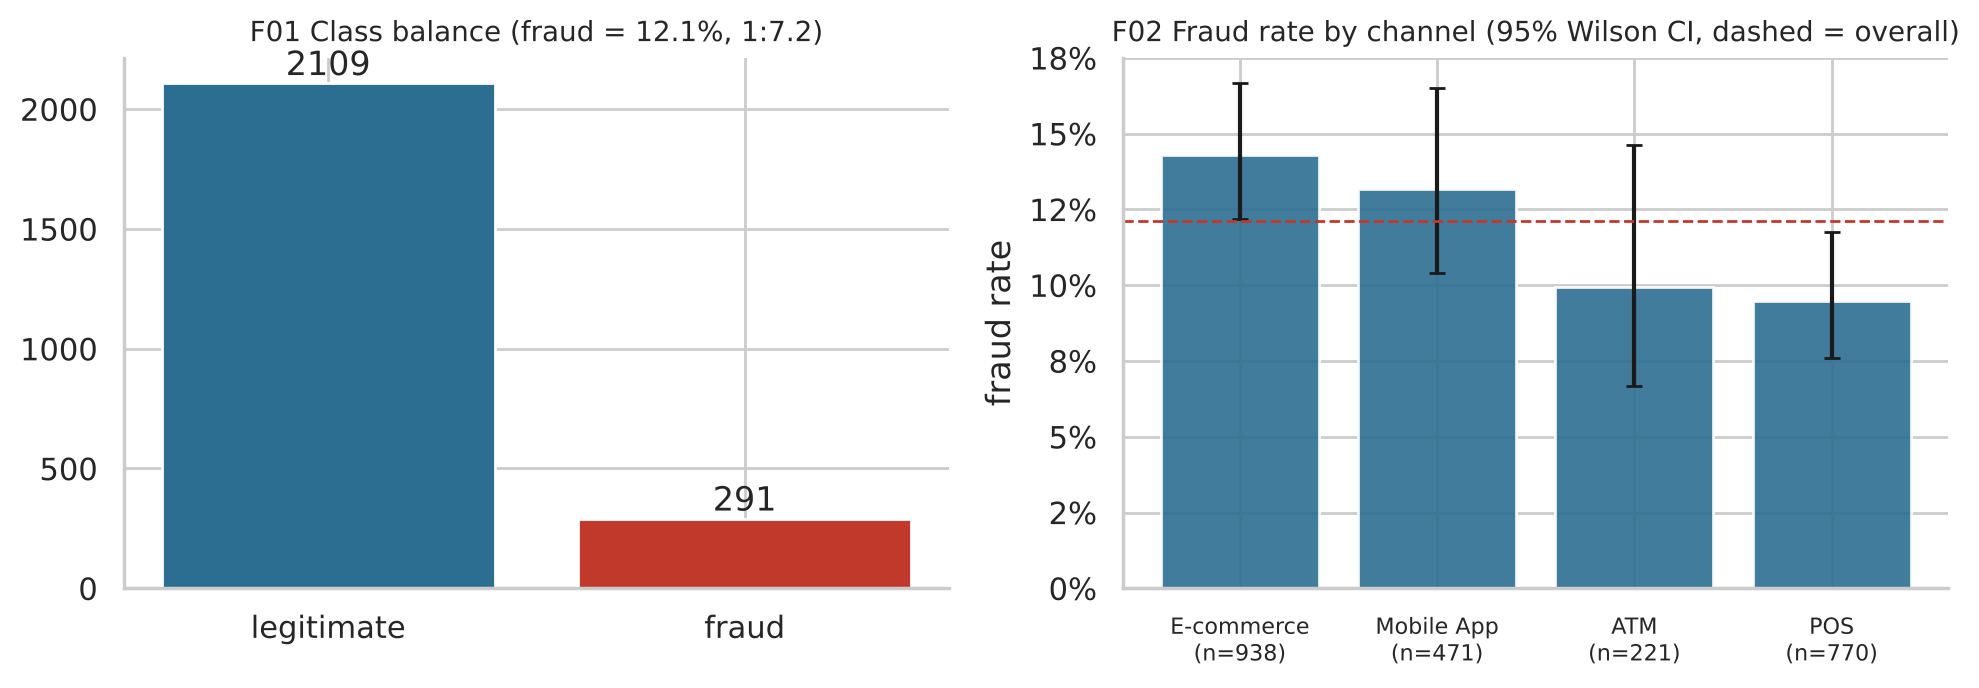

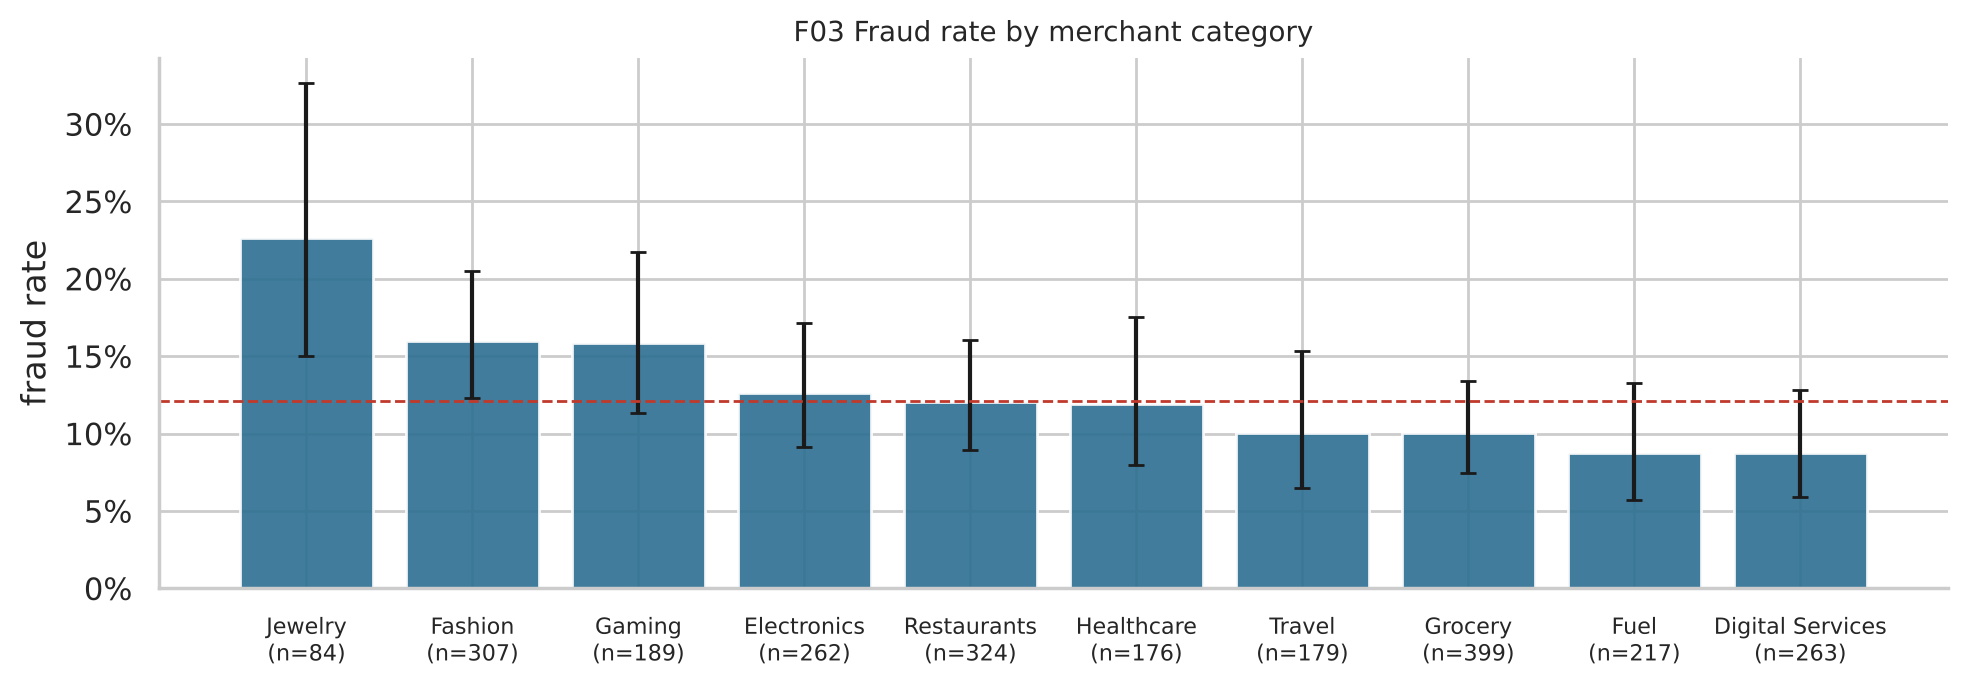

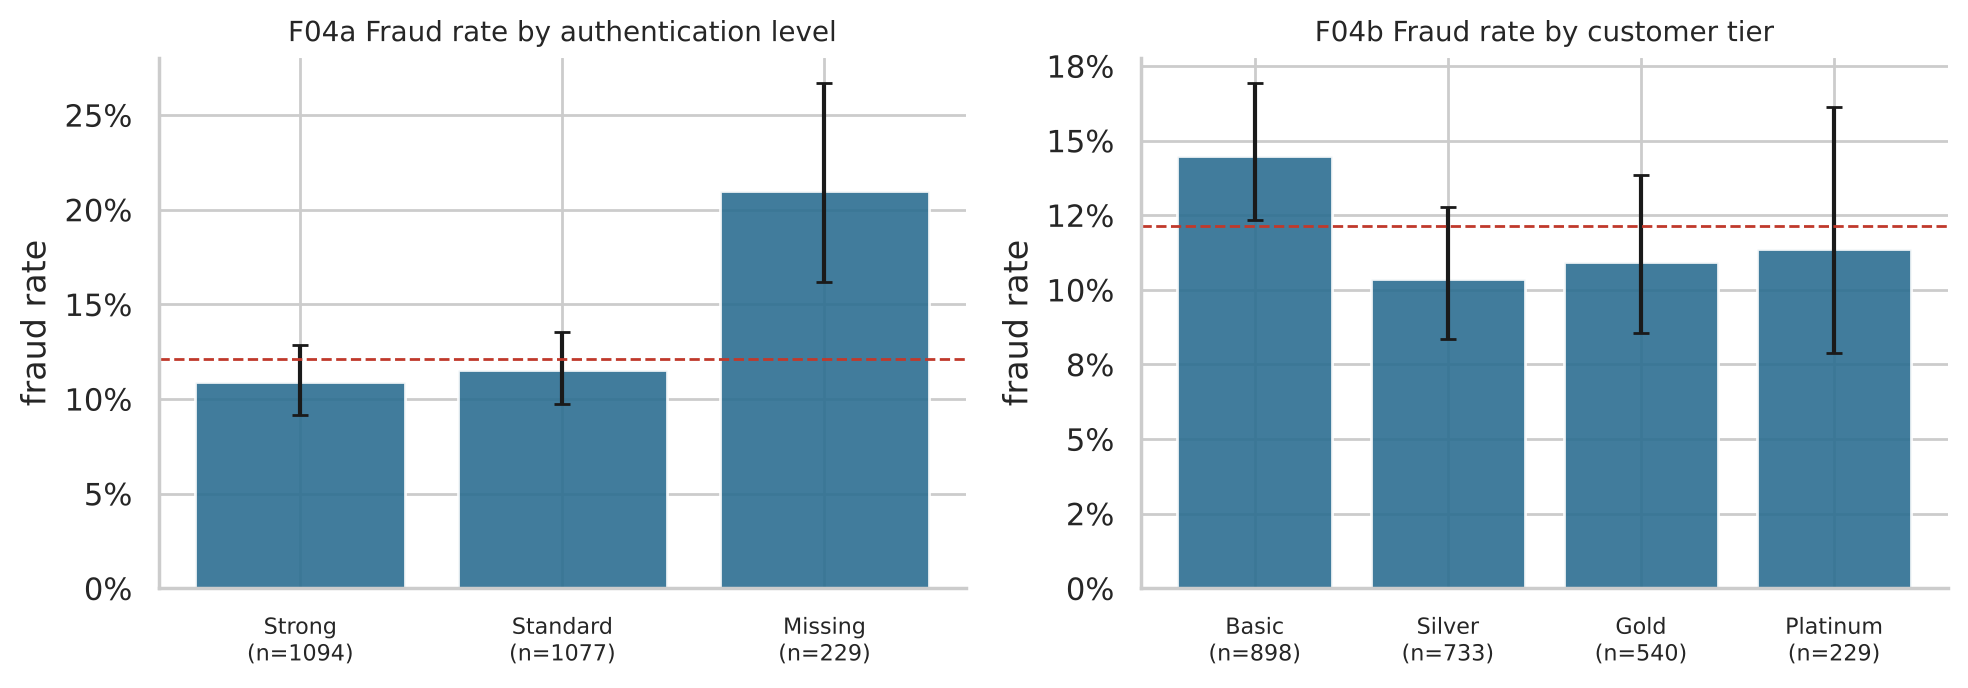

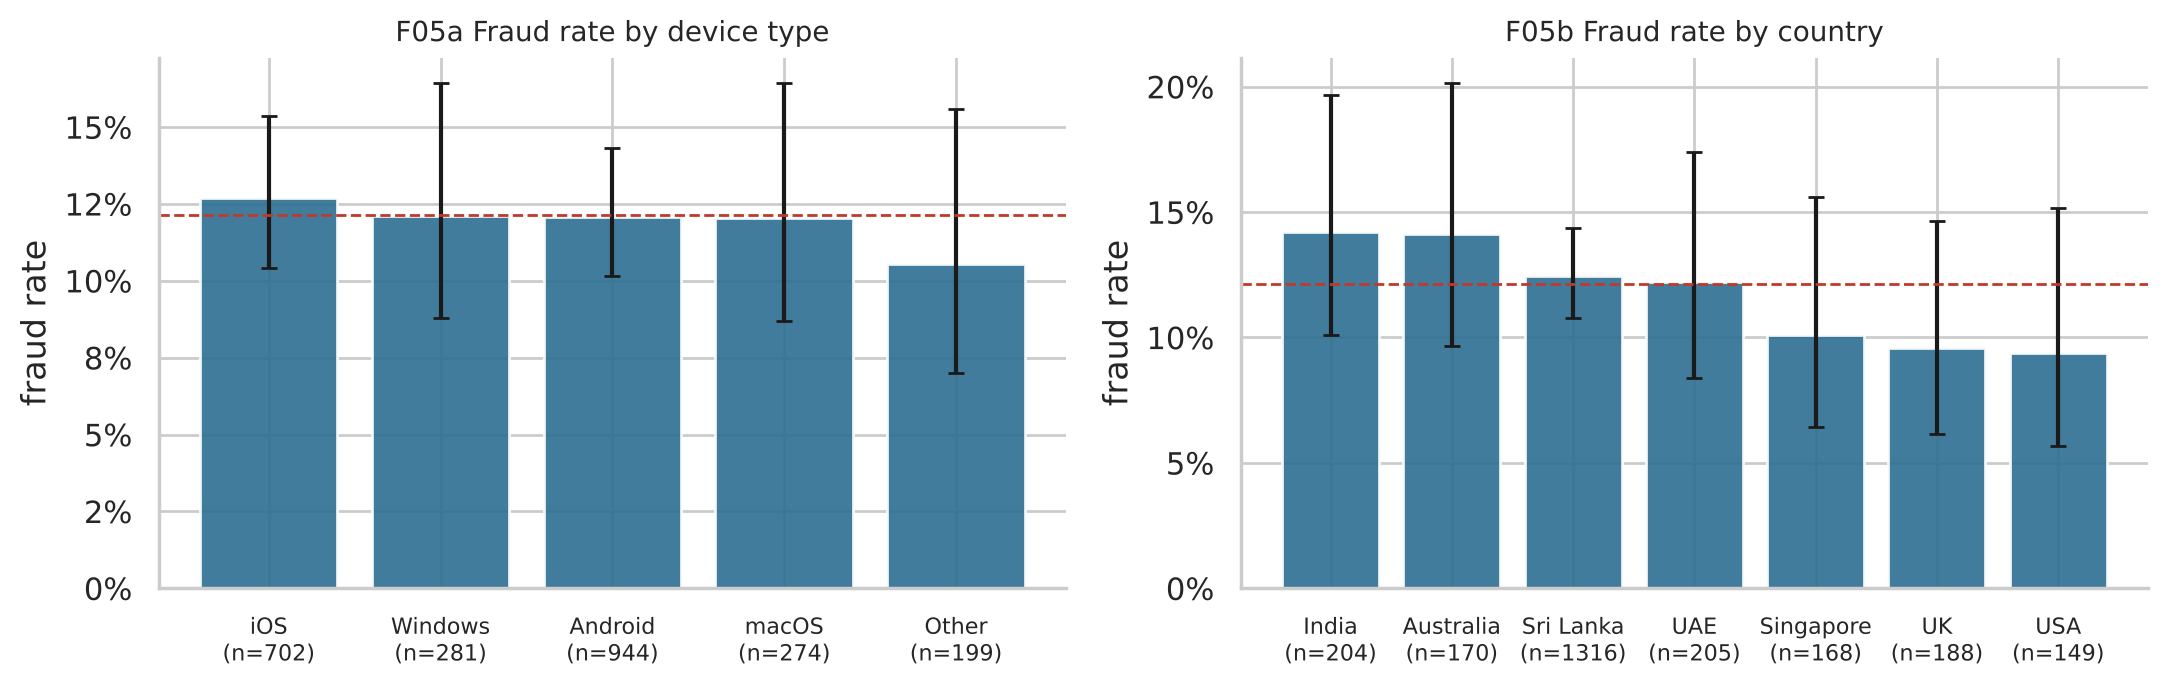

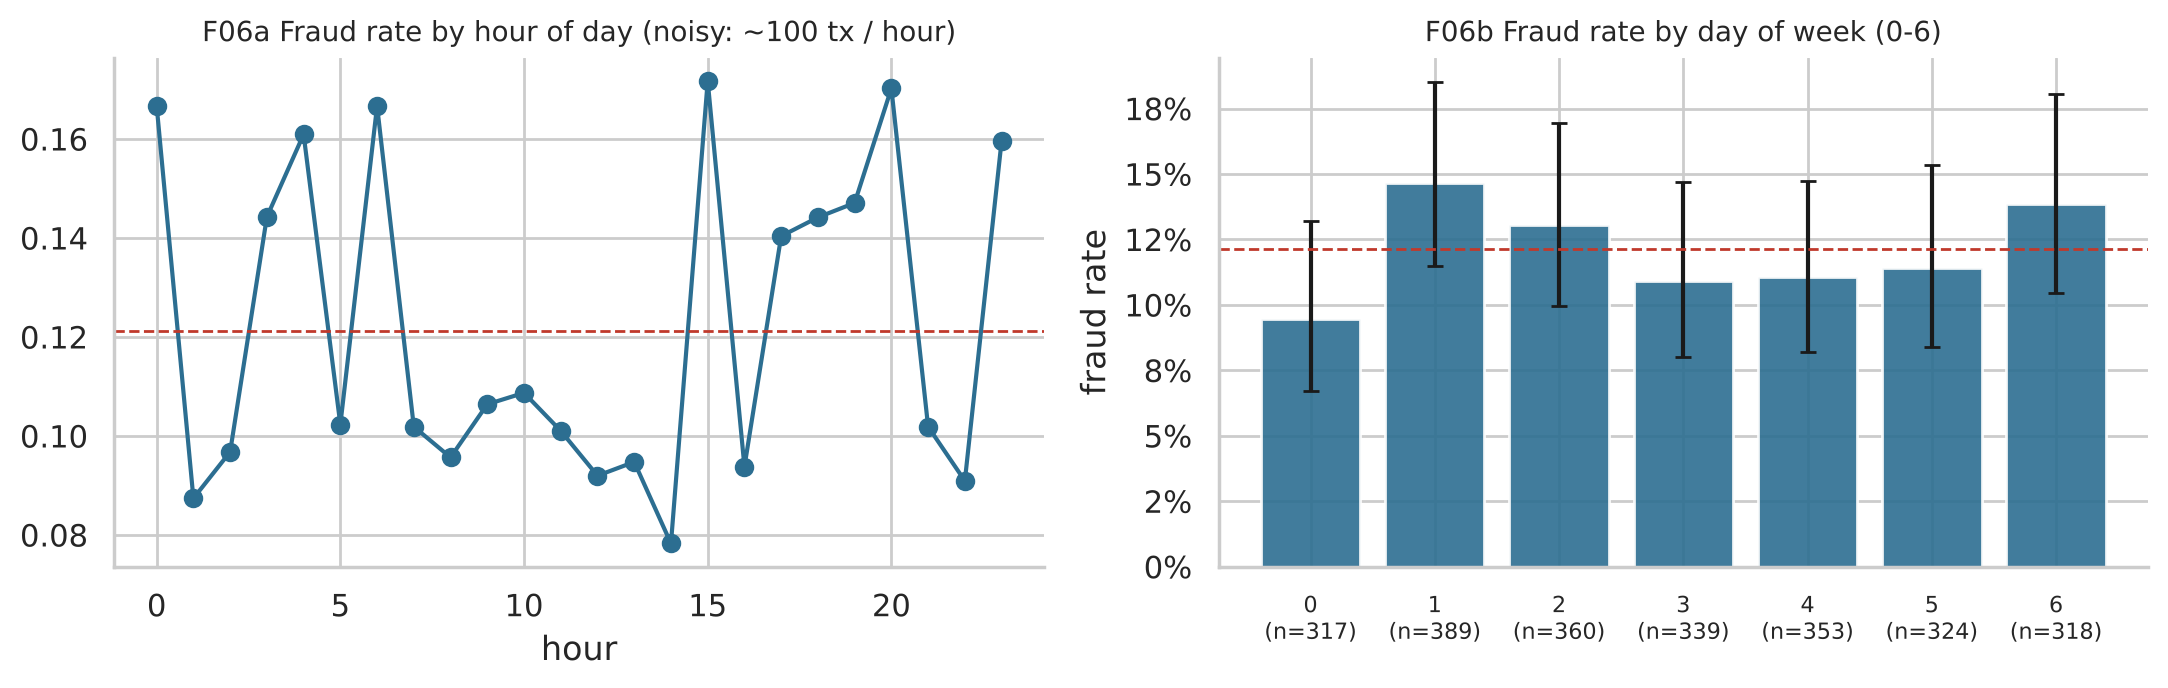

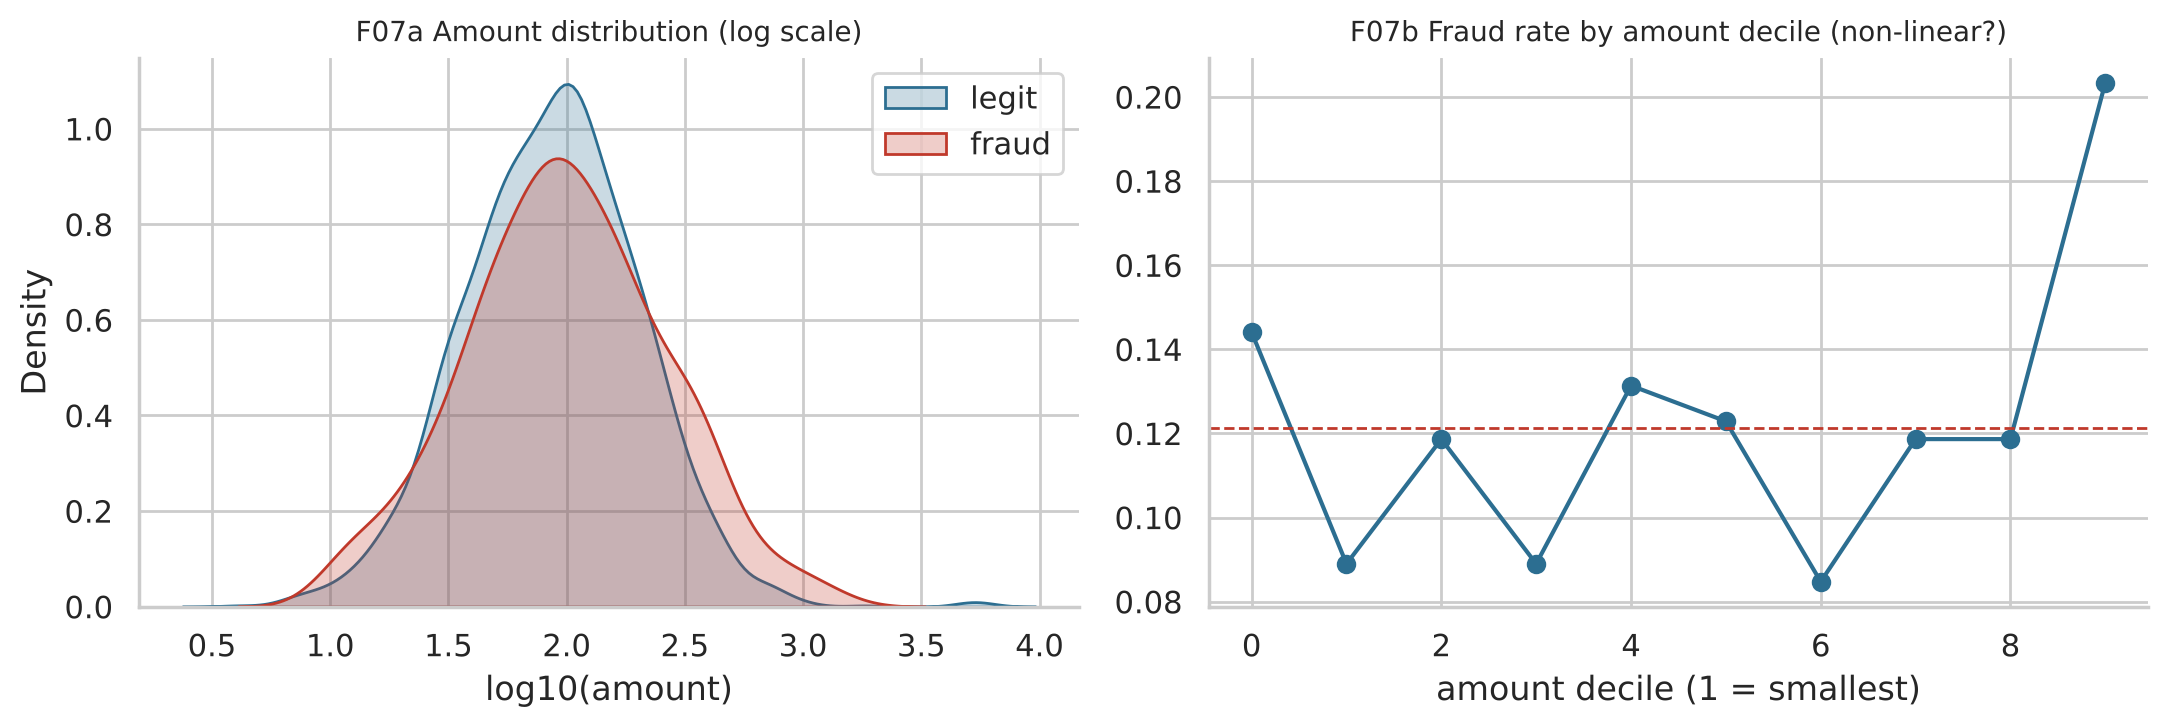

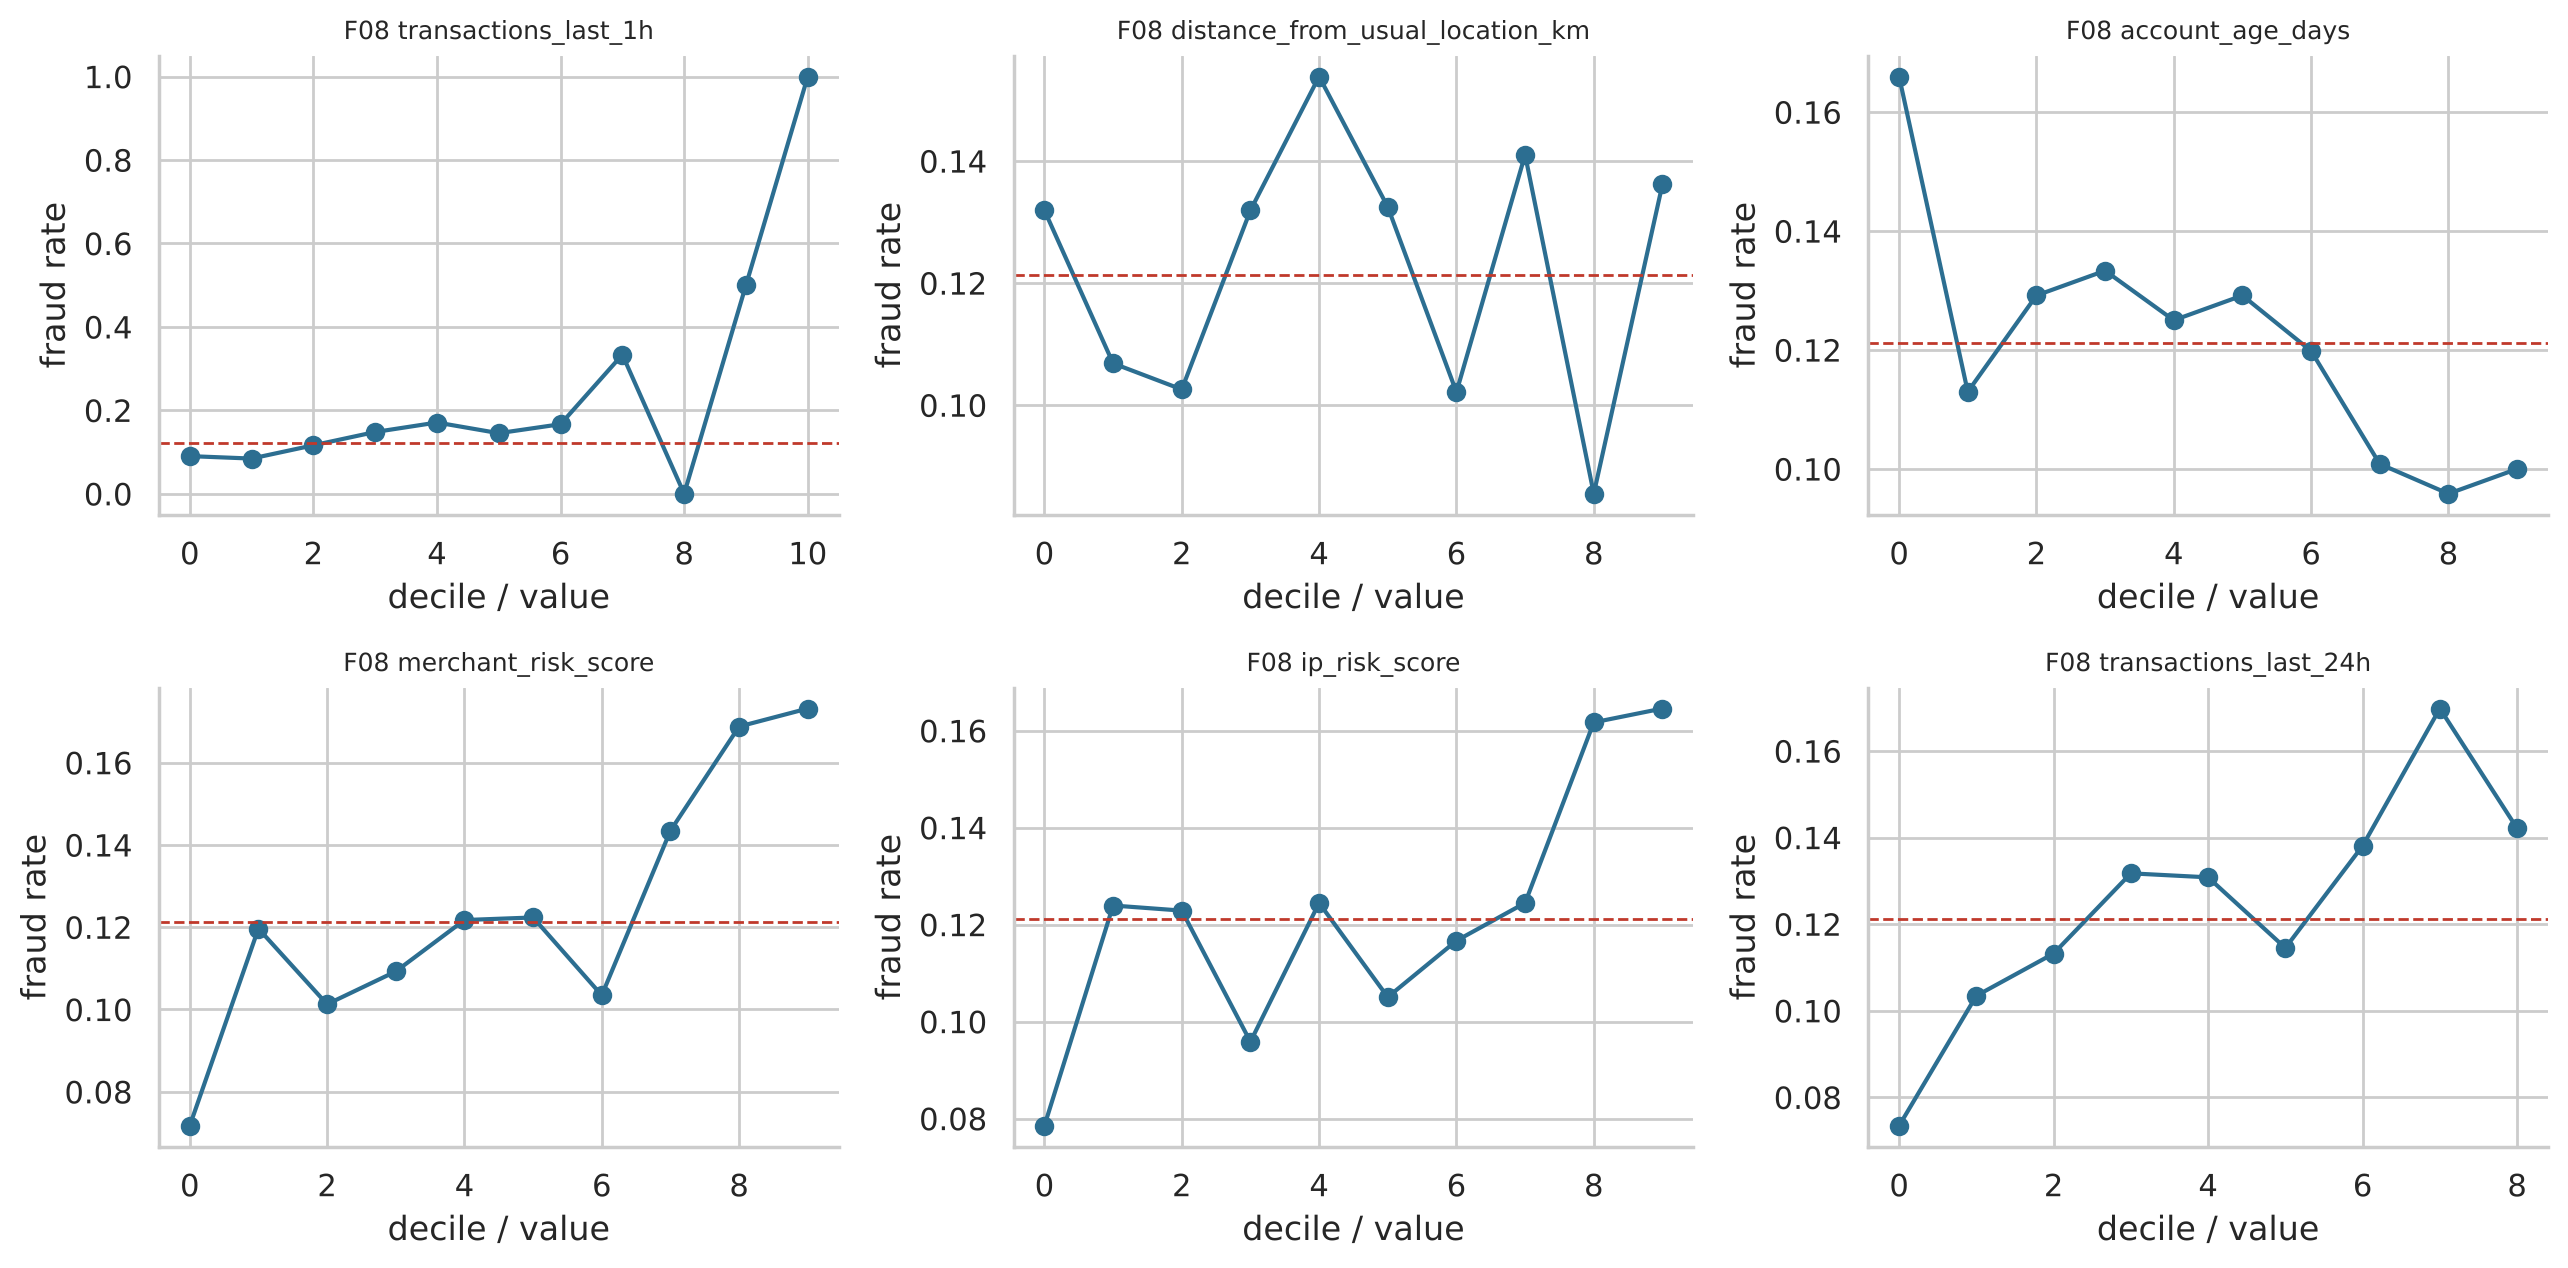

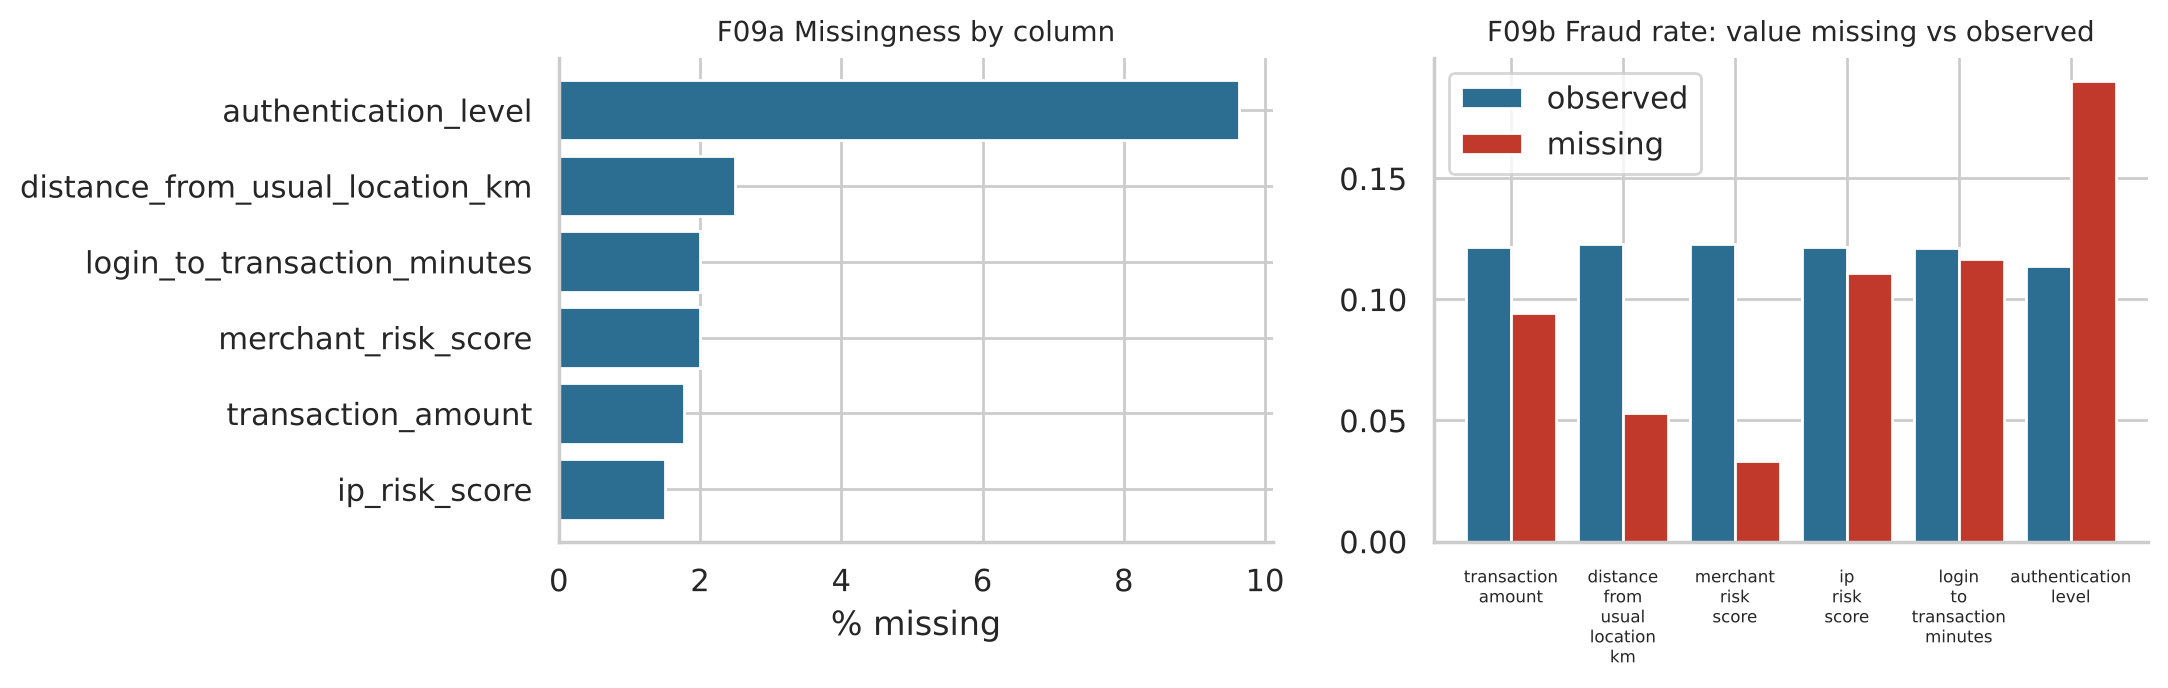

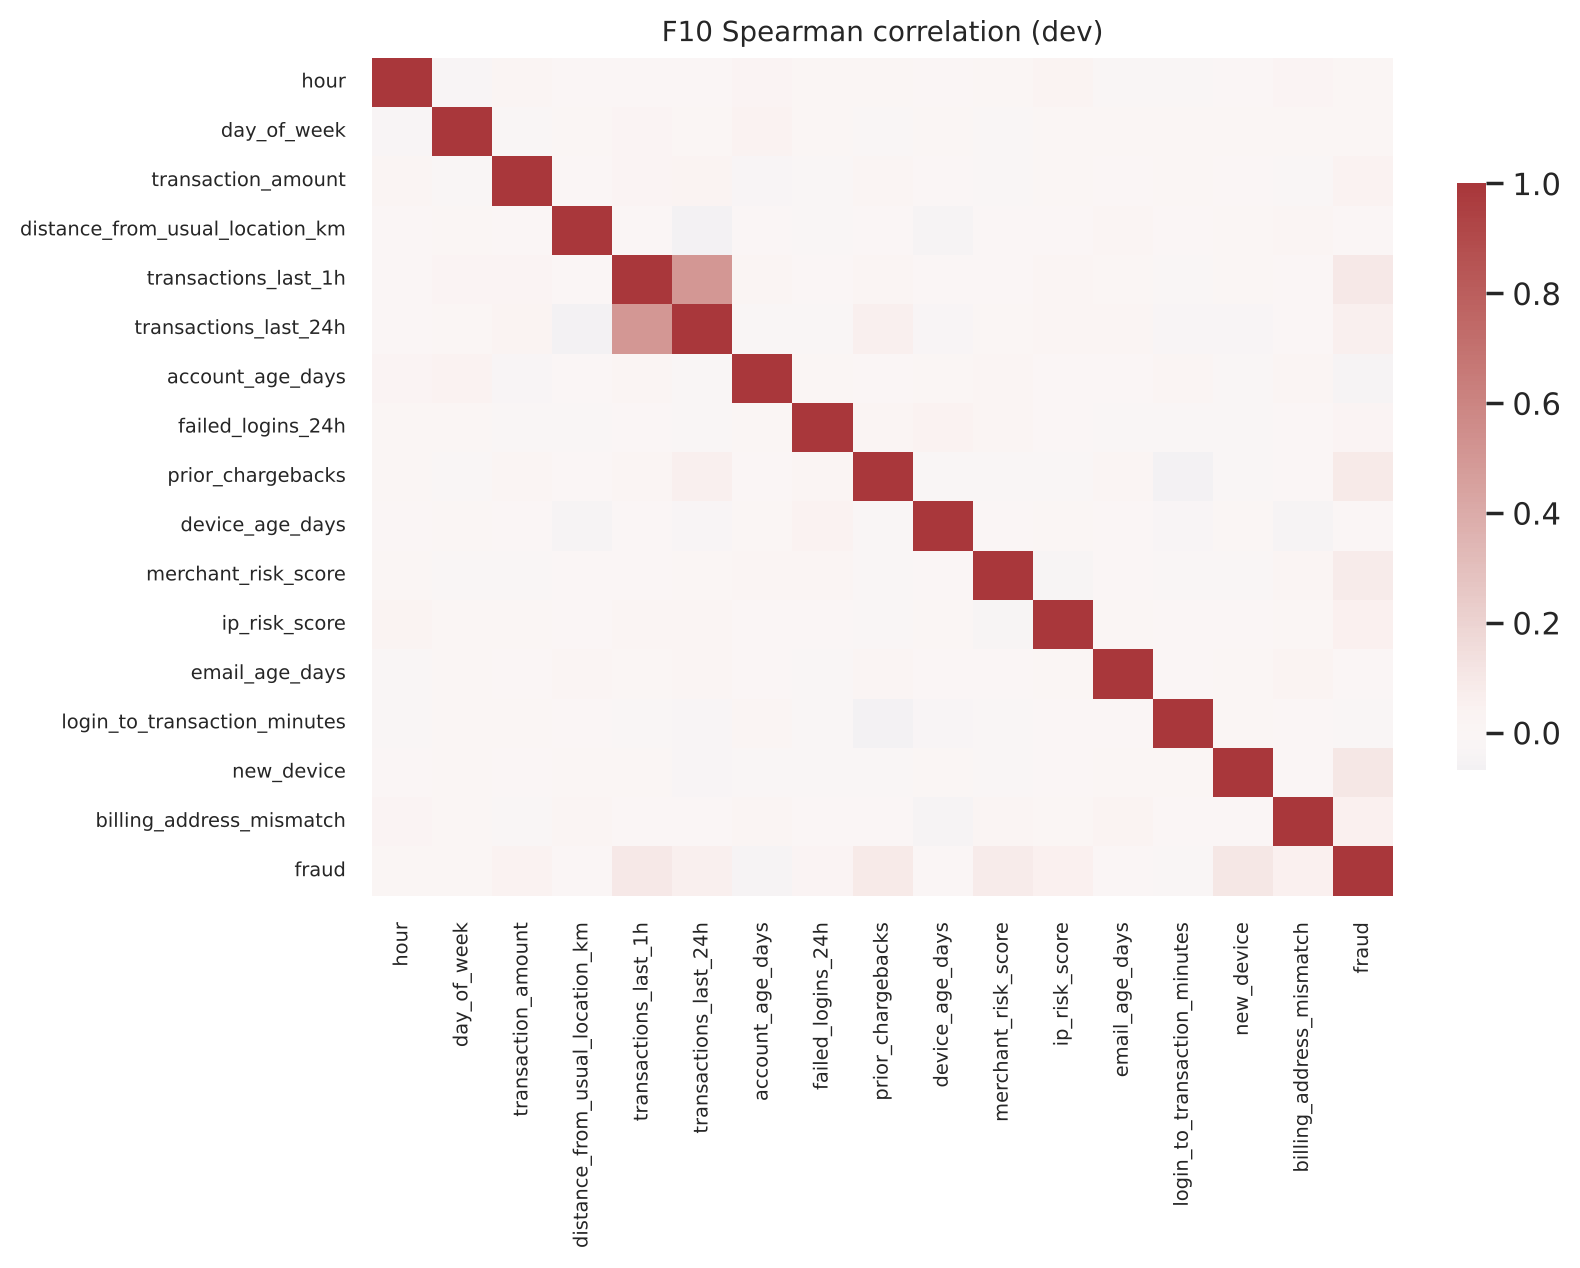

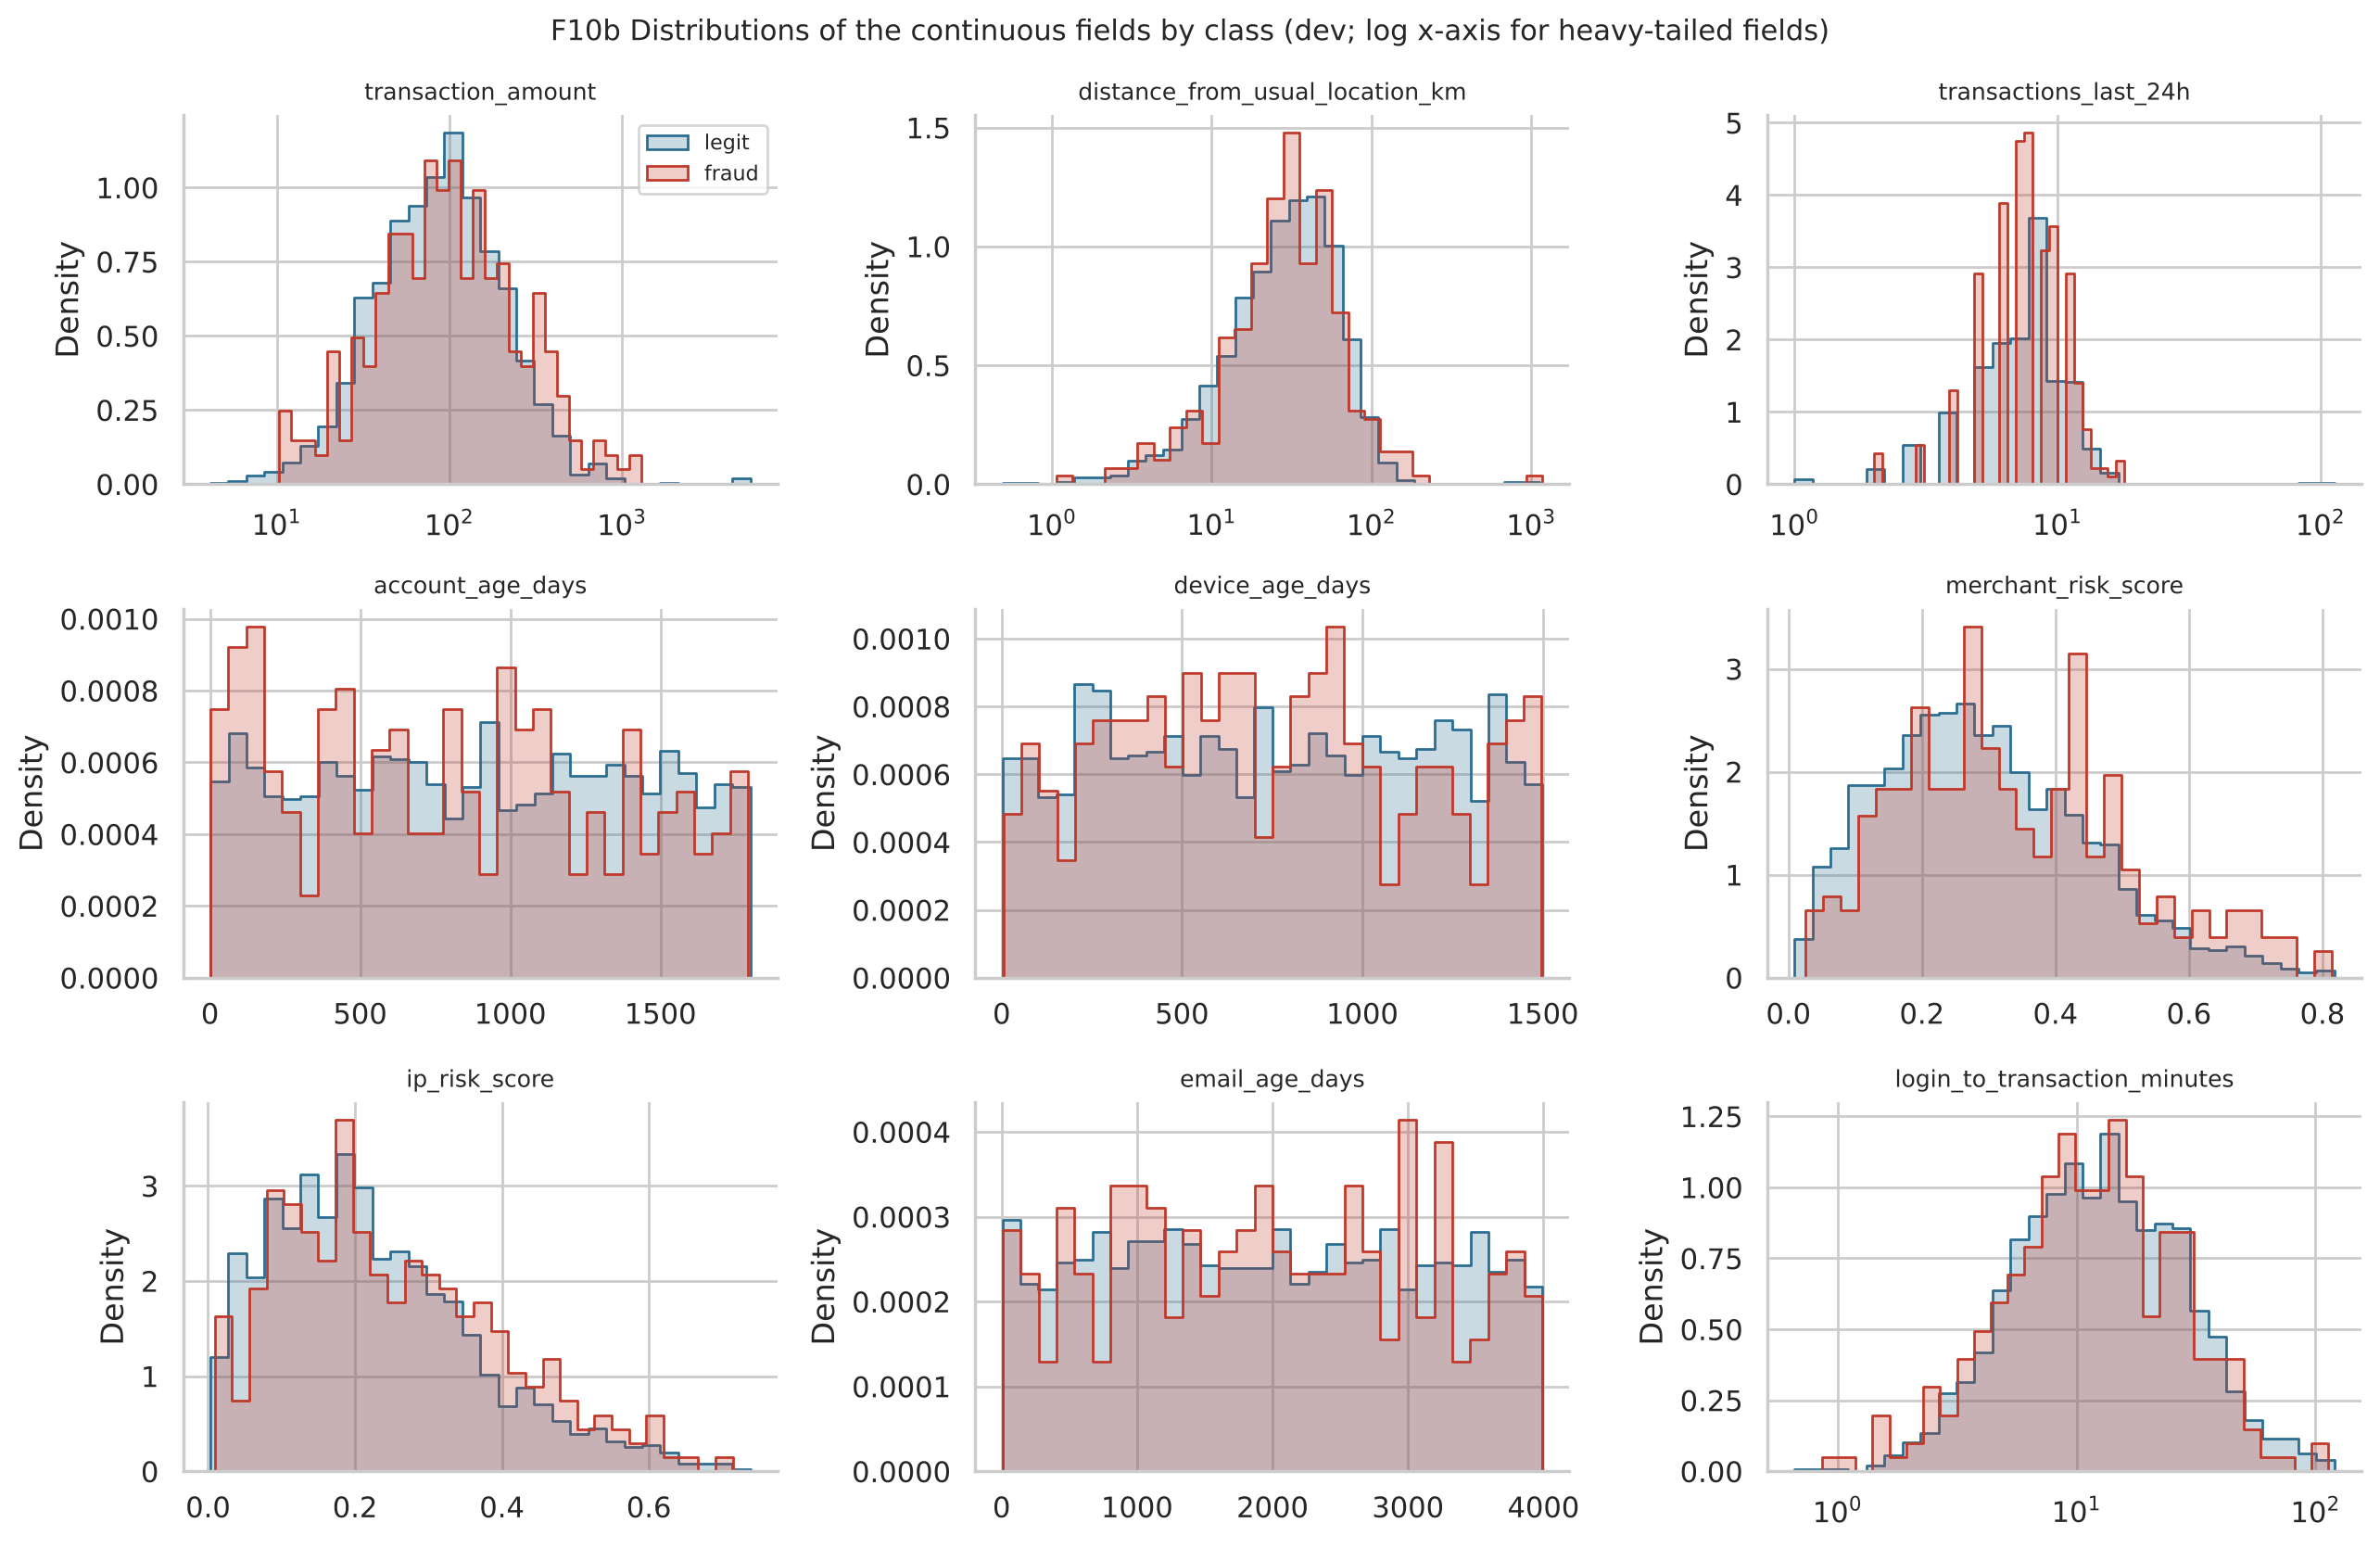

,feature,median_fraud,median_legit,mean_fraud,mean_legit,mannwhitney_p
2,transactions_last_1h,2.0000,2.0000,2.5739,2.1304,0.0000
6,prior_chargebacks,0.0000,0.0000,0.2062,0.1133,0.0000
12,new_device,0.0000,0.0000,0.2680,0.1508,0.0000
8,merchant_risk_score,0.3105,0.2770,0.3396,0.2953,0.0001
3,transactions_last_24h,8.0000,7.0000,8.1100,7.7833,0.0026
13,billing_address_mismatch,0.0000,0.0000,0.1409,0.0901,0.0059
9,ip_risk_score,0.2220,0.2015,0.2510,0.2249,0.0063
4,account_age_days,808.0000,897.0000,818.1649,893.8393,0.0200
0,transaction_amount,95.2350,89.3900,156.2093,131.3084,0.0426
11,login_to_transaction_minutes,11.4100,12.3800,15.9484,17.0626,0.2017


In [7]:
eda = X_dev.assign(fraud=y_dev); eda["authentication_level"] = eda["authentication_level"].fillna("Missing")
base_rate = eda.fraud.mean()

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

def rate_bar(ax, col, order=None, title=None, data=eda):
    g = data.groupby(col).fraud.agg(["sum", "count"]);  g["rate"] = g["sum"] / g["count"]
    g = g.loc[order] if order else g.sort_values("rate", ascending=False)
    ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["count"])])
    ax.bar(range(len(g)), g.rate, color=C_OK, yerr=[g.rate - ci[:, 0], ci[:, 1] - g.rate], capsize=3, alpha=.9)
    ax.axhline(base_rate, color=C_FRAUD, ls="--", lw=1); ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(g.index, g["count"])], fontsize=8, rotation=0)
    ax.set_ylabel("fraud rate"); ax.set_title(title or col, fontsize=10); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    return g

# F01 class balance and F02 channel / card presence
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(["legitimate", "fraud"], [(y_dev == 0).sum(), (y_dev == 1).sum()], color=[C_OK, C_FRAUD])
for i, v in enumerate([(y_dev == 0).sum(), (y_dev == 1).sum()]): ax[0].text(i, v, f"{v}", ha="center", va="bottom")
ax[0].set_title(f"F01 Class balance (fraud = {base_rate:.1%}, 1:{(1-base_rate)/base_rate:.1f})", fontsize=10)
rate_bar(ax[1], "channel", title="F02 Fraud rate by channel (95% Wilson CI, dashed = overall)"); savefig("F01_F02_class_balance_channel")
chan = eda.groupby("channel").fraud.mean().to_dict(); R["rate_channel"] = chan

# F03 merchant category
fig, ax = plt.subplots(figsize=(10, 3.6)); g = rate_bar(ax, "merchant_category", title="F03 Fraud rate by merchant category"); savefig("F03_merchant_category")
R["rate_merchant"] = g["rate"].to_dict()

# F04 authentication / tier
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ga = rate_bar(ax[0], "authentication_level", order=["Strong", "Standard", "Missing"], title="F04a Fraud rate by authentication level")
gt = rate_bar(ax[1], "customer_tier", order=["Basic", "Silver", "Gold", "Platinum"], title="F04b Fraud rate by customer tier"); savefig("F04_auth_tier")
R["rate_auth"] = ga["rate"].to_dict(); R["rate_tier"] = gt["rate"].to_dict()

# F05 device / country
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
rate_bar(ax[0], "device_type", title="F05a Fraud rate by device type"); rate_bar(ax[1], "country", title="F05b Fraud rate by country"); savefig("F05_device_country")

# F06 time periods
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h = eda.groupby("hour").fraud.agg(["mean", "count"]); ax[0].plot(h.index, h["mean"], marker="o", color=C_OK)
ax[0].axhline(base_rate, color=C_FRAUD, ls="--", lw=1); ax[0].set_title("F06a Fraud rate by hour of day (noisy: ~100 tx / hour)", fontsize=10); ax[0].set_xlabel("hour")
rate_bar(ax[1], "day_of_week", order=list(range(7)), title="F06b Fraud rate by day of week (0-6)"); savefig("F06_time")
tp = pd.crosstab(eda.hour.isin(range(0, 6)), eda.fraud); R["night_p"] = float(stats.chi2_contingency(tp)[1])

# F07 amount: distribution + nonlinear rate
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for lab, col in [(0, C_OK), (1, C_FRAUD)]:
    sns.kdeplot(np.log10(eda.loc[eda.fraud == lab, "transaction_amount"].dropna()), ax=ax[0], color=col, label="fraud" if lab else "legit", fill=True, alpha=.25)
ax[0].set_xlabel("log10(amount)"); ax[0].legend(); ax[0].set_title("F07a Amount distribution (log scale)", fontsize=10)
q = pd.qcut(eda.transaction_amount, 10, duplicates="drop"); gq = eda.groupby(q).fraud.mean()
ax[1].plot(range(len(gq)), gq.values, marker="o", color=C_OK); ax[1].axhline(base_rate, color=C_FRAUD, ls="--", lw=1)
ax[1].set_xlabel("amount decile (1 = smallest)"); ax[1].set_title("F07b Fraud rate by amount decile (non-linear?)", fontsize=10); savefig("F07_amount")

# F08 nonlinear effects of velocity, distance, account age, risk scores
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axs.ravel(), ["transactions_last_1h", "distance_from_usual_location_km", "account_age_days", "merchant_risk_score", "ip_risk_score", "transactions_last_24h"]):
    s = eda[c]
    b = pd.cut(s, [-np.inf] + list(np.unique(s.quantile(np.linspace(0, 1, 11)[1:-1]))) + [np.inf]) if s.nunique() > 12 else s
    gg = eda.groupby(b).fraud.agg(["mean", "count"])
    ax.plot(range(len(gg)), gg["mean"], marker="o", color=C_OK); ax.axhline(base_rate, color=C_FRAUD, ls="--", lw=1)
    ax.set_title(f"F08 {c}", fontsize=9); ax.set_xlabel("decile / value"); ax.set_ylabel("fraud rate")
savefig("F08_nonlinear_effects")

# F09 missingness as signal
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
mp = (raw.isna().mean() * 100); mp = mp[mp > 0].sort_values(); ax[0].barh(mp.index, mp.values, color=C_OK); ax[0].set_xlabel("% missing"); ax[0].set_title("F09a Missingness by column", fontsize=10)
mm = miss_df.set_index("feature"); xx = np.arange(len(mm)); ax[1].bar(xx - .2, mm.fraud_rate_observed, .4, color=C_OK, label="observed"); ax[1].bar(xx + .2, mm.fraud_rate_missing, .4, color=C_FRAUD, label="missing")
ax[1].set_xticks(xx); ax[1].set_xticklabels([f.replace("_", "\n") for f in mm.index], fontsize=6); ax[1].legend(); ax[1].set_title("F09b Fraud rate: value missing vs observed", fontsize=10); savefig("F09_missingness")

# F10 correlations
fig, ax = plt.subplots(figsize=(8.5, 6.5)); cm = eda.drop(columns=[]).select_dtypes("number").corr(method="spearman")
sns.heatmap(cm, cmap="vlag", center=0, ax=ax, cbar_kws=dict(shrink=.7), xticklabels=True, yticklabels=True); ax.tick_params(labelsize=7); ax.set_title("F10 Spearman correlation (dev)", fontsize=10); savefig("F10_correlation")
R["corr_with_fraud"] = cm["fraud"].drop("fraud").sort_values().round(3).to_dict()

# F10b numeric distributions by class + class-difference tests
numc = ["transaction_amount", "distance_from_usual_location_km", "transactions_last_24h", "account_age_days", "device_age_days", "merchant_risk_score", "ip_risk_score", "email_age_days", "login_to_transaction_minutes"]
logc = {"transaction_amount", "distance_from_usual_location_km", "transactions_last_24h", "login_to_transaction_minutes"}
fig, axs = plt.subplots(3, 3, figsize=(13, 8.5))
for ax, c in zip(axs.ravel(), numc):
    for lab, col, nm in [(0, C_OK, "legit"), (1, C_FRAUD, "fraud")]:
        sns.histplot(eda.loc[(eda.fraud == lab) & eda[c].notna() & ((eda[c] > 0) | (c not in logc)), c], ax=ax, stat="density", common_norm=False, element="step", fill=True, alpha=.25, color=col, label=nm, bins=30, log_scale=(c in logc))
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
axs[0, 0].legend(fontsize=8); fig.suptitle("F10b Distributions of the continuous fields by class (dev; log x-axis for heavy-tailed fields)", fontsize=11); savefig("F10b_distributions_by_class")
cd_rows = []
for c in [x for x in NUM_RAW if x not in ("hour", "day_of_week")]:
    a_, b_ = eda.loc[eda.fraud == 1, c].dropna(), eda.loc[eda.fraud == 0, c].dropna()
    cd_rows.append(dict(feature=c, median_fraud=a_.median(), median_legit=b_.median(), mean_fraud=a_.mean(), mean_legit=b_.mean(), mannwhitney_p=stats.mannwhitneyu(a_, b_).pvalue))
cdiff = pd.DataFrame(cd_rows).round(4).sort_values("mannwhitney_p"); display(cdiff); R["class_diff"] = cdiff.to_dict("records")

### B-interactions

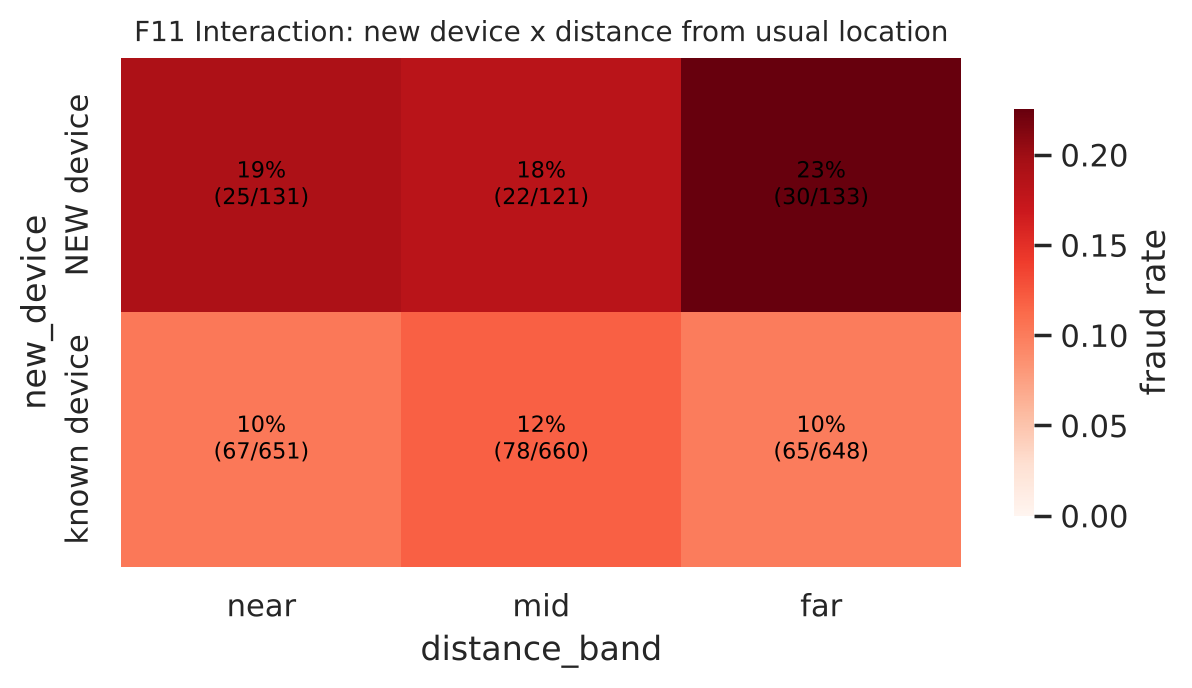

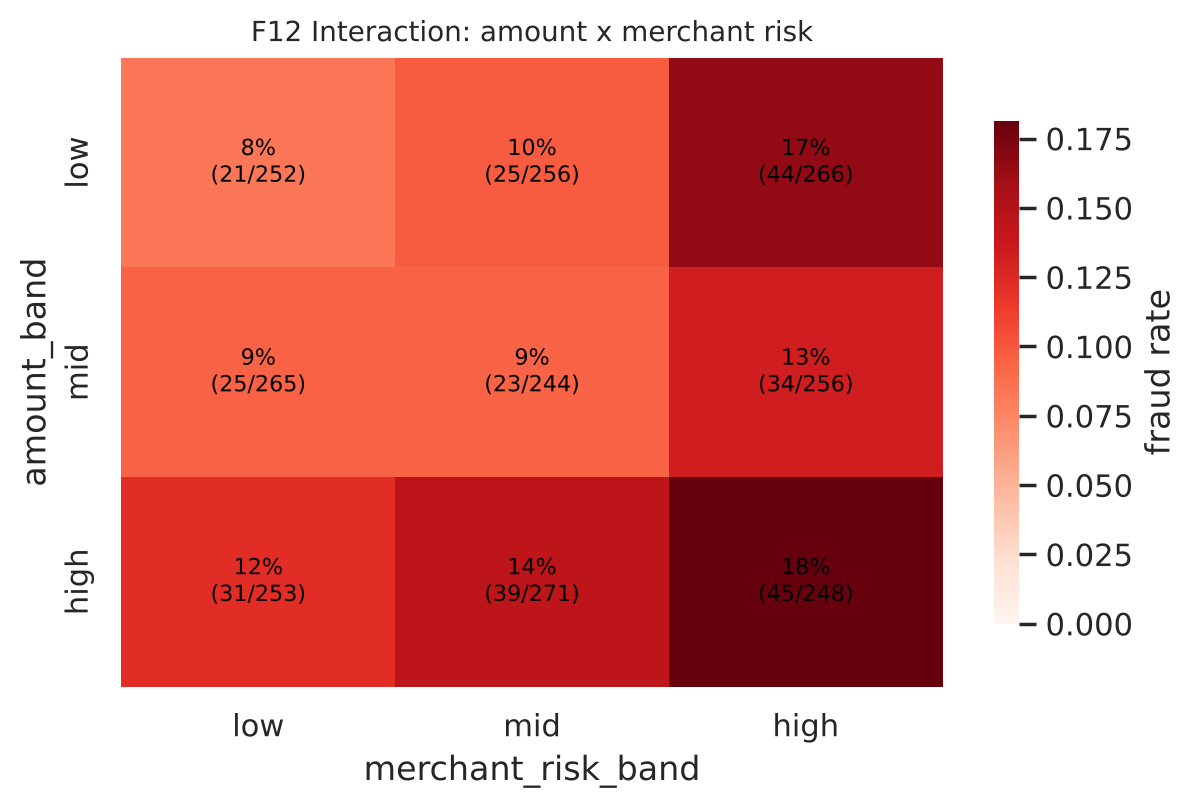

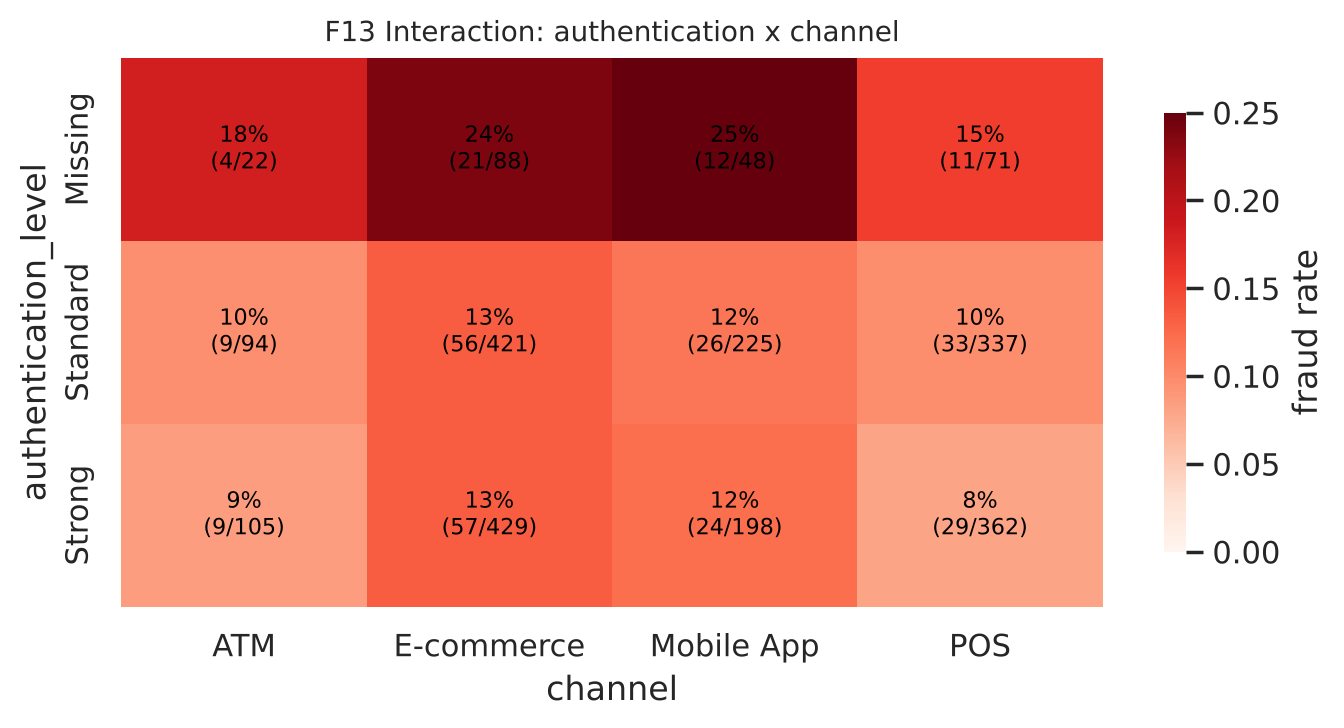

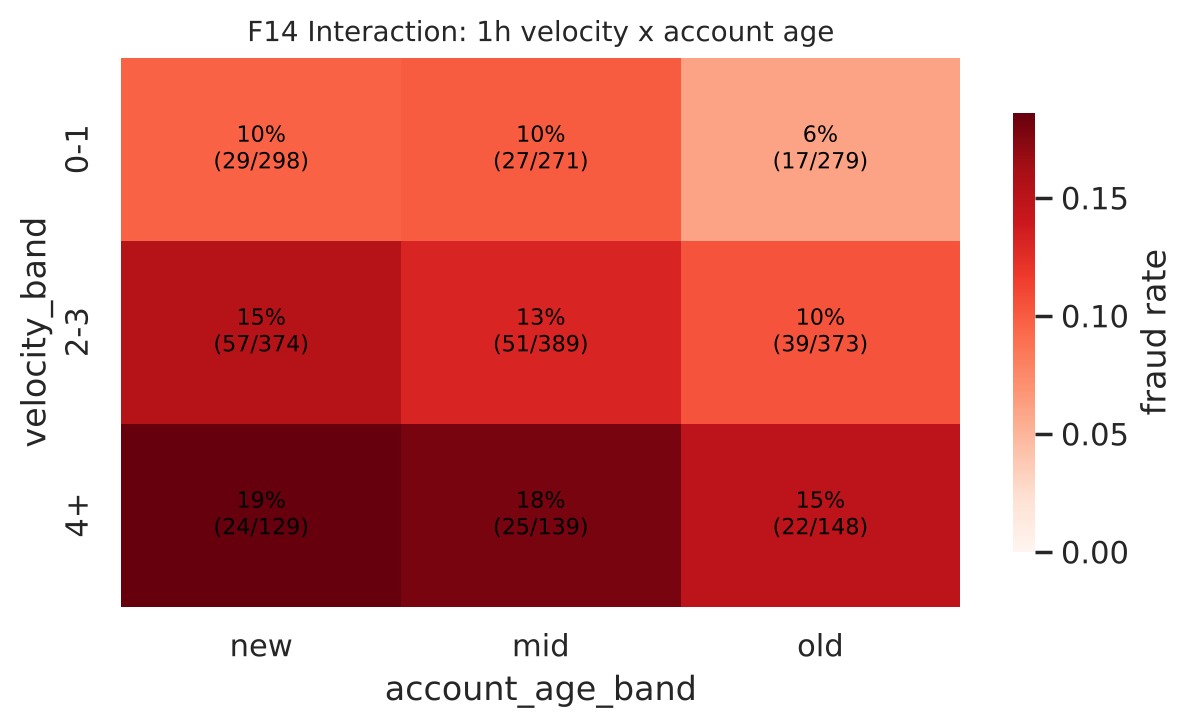

14 figures saved (F01-F14) incl. 4 interaction plots


In [8]:
def tercile(s, labels): return pd.qcut(s, 3, labels=labels, duplicates="drop")
def heat(ax, data, rowc, colc, title, rl=None):
    t = data.pivot_table(index=rowc, columns=colc, values="fraud", aggfunc="mean", observed=True)
    n = data.pivot_table(index=rowc, columns=colc, values="fraud", aggfunc="count", observed=True)
    k = data.pivot_table(index=rowc, columns=colc, values="fraud", aggfunc="sum", observed=True)
    sns.heatmap(t, annot=False, cmap="Reds", ax=ax, vmin=0, cbar_kws=dict(label="fraud rate", shrink=.8))
    for i in range(t.shape[0]):
        for j in range(t.shape[1]): ax.text(j + .5, i + .5, f"{t.iloc[i, j]:.0%}\n({int(k.iloc[i, j])}/{int(n.iloc[i, j])})", ha="center", va="center", fontsize=8, color="black")
    ax.set_title(title, fontsize=10); return t

# F11 new device x distance
d = eda.copy(); d["distance_band"] = tercile(d.distance_from_usual_location_km, ["near", "mid", "far"]); d["new_device"] = d.new_device.map({0: "known device", 1: "NEW device"})
fig, ax = plt.subplots(figsize=(6.2, 3.6)); t1 = heat(ax, d.dropna(subset=["distance_band"]), "new_device", "distance_band", "F11 Interaction: new device x distance from usual location"); savefig("F11_interaction_newdevice_distance")
# F12 amount x merchant risk
d = eda.copy(); d["amount_band"] = tercile(d.transaction_amount, ["low", "mid", "high"]); d["merchant_risk_band"] = tercile(d.merchant_risk_score, ["low", "mid", "high"])
fig, ax = plt.subplots(figsize=(6.2, 4.2)); t2 = heat(ax, d.dropna(subset=["amount_band", "merchant_risk_band"]), "amount_band", "merchant_risk_band", "F12 Interaction: amount x merchant risk"); savefig("F12_interaction_amount_merchantrisk")
# F13 authentication x channel
fig, ax = plt.subplots(figsize=(7, 3.8)); t3 = heat(ax, eda, "authentication_level", "channel", "F13 Interaction: authentication x channel"); savefig("F13_interaction_auth_channel")
# F14 velocity x account age
d = eda.copy(); d["velocity_band"] = pd.cut(d.transactions_last_1h, [-1, 1, 3, 100], labels=["0-1", "2-3", "4+"]); d["account_age_band"] = tercile(d.account_age_days, ["new", "mid", "old"])
fig, ax = plt.subplots(figsize=(6.2, 3.8)); t4 = heat(ax, d, "velocity_band", "account_age_band", "F14 Interaction: 1h velocity x account age"); savefig("F14_interaction_velocity_age")
R["inter_newdev_dist"] = t1.round(3).to_dict(); R["inter_amt_merchant"] = t2.round(3).to_dict(); R["inter_auth_channel"] = t3.round(3).to_dict()
print("14 figures saved (F01-F14) incl. 4 interaction plots")

## C. Feature engineering
The raw table has 23 predictors. `FeatureEngineer` (in `fraud_lib.py`) derives **89 engineered features in 11 groups**; after one-hot encoding and target-encoding the model sees about 140 columns. Design rules:
1. **Every statistic is learned in `fit()` on training data only** (group means, percentiles, bin edges, frequencies). Target encodings of category combinations use scikit-learn's cross-fitted `TargetEncoder` inside the pipeline.
2. **Nothing uses the label or post-transaction information.** All features can be computed at authorisation time if (i) velocity windows end before the transaction, (ii) risk scores / chargeback counts are point-in-time snapshots and (iii) the learned statistics are refreshed with each retrain.
3. Each feature has a stated rationale (table below). We then *measure* what each group is worth (ablation), whether selection helps, and how stable the evidence is.

In [9]:
fe_doc = pd.DataFrame(FE_SPEC, columns=["feature", "group", "definition / rationale", "needs_fitted_state"])
fe_doc["available_at_prediction_time"] = "yes (point-in-time inputs required)"
display(fe_doc.groupby("group", sort=False).size().rename("n_features").to_frame().T)
display(fe_doc.drop(columns=["available_at_prediction_time"]))
fe_doc.to_csv("feature_dictionary.csv", index=False)
R["n_engineered"] = len(fe_doc); R["fe_groups"] = fe_doc.groupby("group", sort=False).size().to_dict()
R["fe_stateful"] = int(fe_doc.needs_fitted_state.sum())

group,transform,velocity,amount_norm,risk,time,behaviour,interaction,flags,missing,binning,encoding
n_features,9,6,7,8,9,9,11,10,7,6,7


,feature,group,definition / rationale,needs_fitted_state
0,log_amount,transform,log1p(amount): amounts are heavy-tailed (max 5...,False
1,log_distance_km,transform,log1p(distance from usual location).,False
2,log_account_age,transform,log1p(account age in days): early-life account...,False
3,log_device_age,transform,log1p(device age in days).,False
4,log_email_age,transform,log1p(email age in days).,False
...,...,...,...,...
84,freq_device_type,encoding,Training share of the device type.,True
85,combo_channel_merchant,encoding,channel x merchant_category -> smoothed target...,True
86,combo_auth_channel,encoding,authentication x channel -> smoothed target en...,True
87,combo_country_device,encoding,country x device_type -> smoothed target encod...,True


### C1. Univariate evaluation of every engineered feature (development set, descriptive)
For each numeric feature: single-feature ROC-AUC (distance from 0.5 = strength; direction ignored), mutual information with the label, Spearman correlation, % missing. Stateful features are computed with statistics from the dev set; no label is used (target-encoded combos are excluded here and shown separately). This is exploratory, selection decisions are made inside CV in C3-C4.

,feature,kind,group,auc,strength,mutual_info,spearman,pct_missing
45,red_flag_count,engineered,risk,0.6308,0.1308,0.0182,0.1540,0.0000
38,combined_risk_mean,engineered,risk,0.5865,0.0865,0.0025,0.0987,3.3750
4,transactions_last_1h,raw,raw,0.5821,0.0821,0.0067,0.0951,0.0000
39,combined_risk_max,engineered,risk,0.5820,0.0820,0.0118,0.0935,3.3750
40,risk_product,engineered,risk,0.5817,0.0817,0.0000,0.0932,3.3750
30,amount_x_tx1h,engineered,velocity,0.5775,0.0775,0.0119,0.0880,1.6667
10,merchant_risk_score,raw,raw,0.5723,0.0723,0.0027,0.0823,2.0833
43,merchant_risk_sq,engineered,risk,0.5723,0.0723,0.0081,0.0823,2.0833
25,velocity_ratio_1h_24h,engineered,velocity,0.5718,0.0718,0.0030,0.0814,0.0000
27,hourly_rate_vs_daily,engineered,velocity,0.5718,0.0718,0.0144,0.0814,0.0000


{'n_eng': 85, 'n_eng_beat_best_raw': 2, 'best_raw': {'feature': 'transactions_last_1h', 'strength': 0.08213286536672315}, 'best_eng': {'feature': 'red_flag_count', 'strength': 0.13076668638253008}}


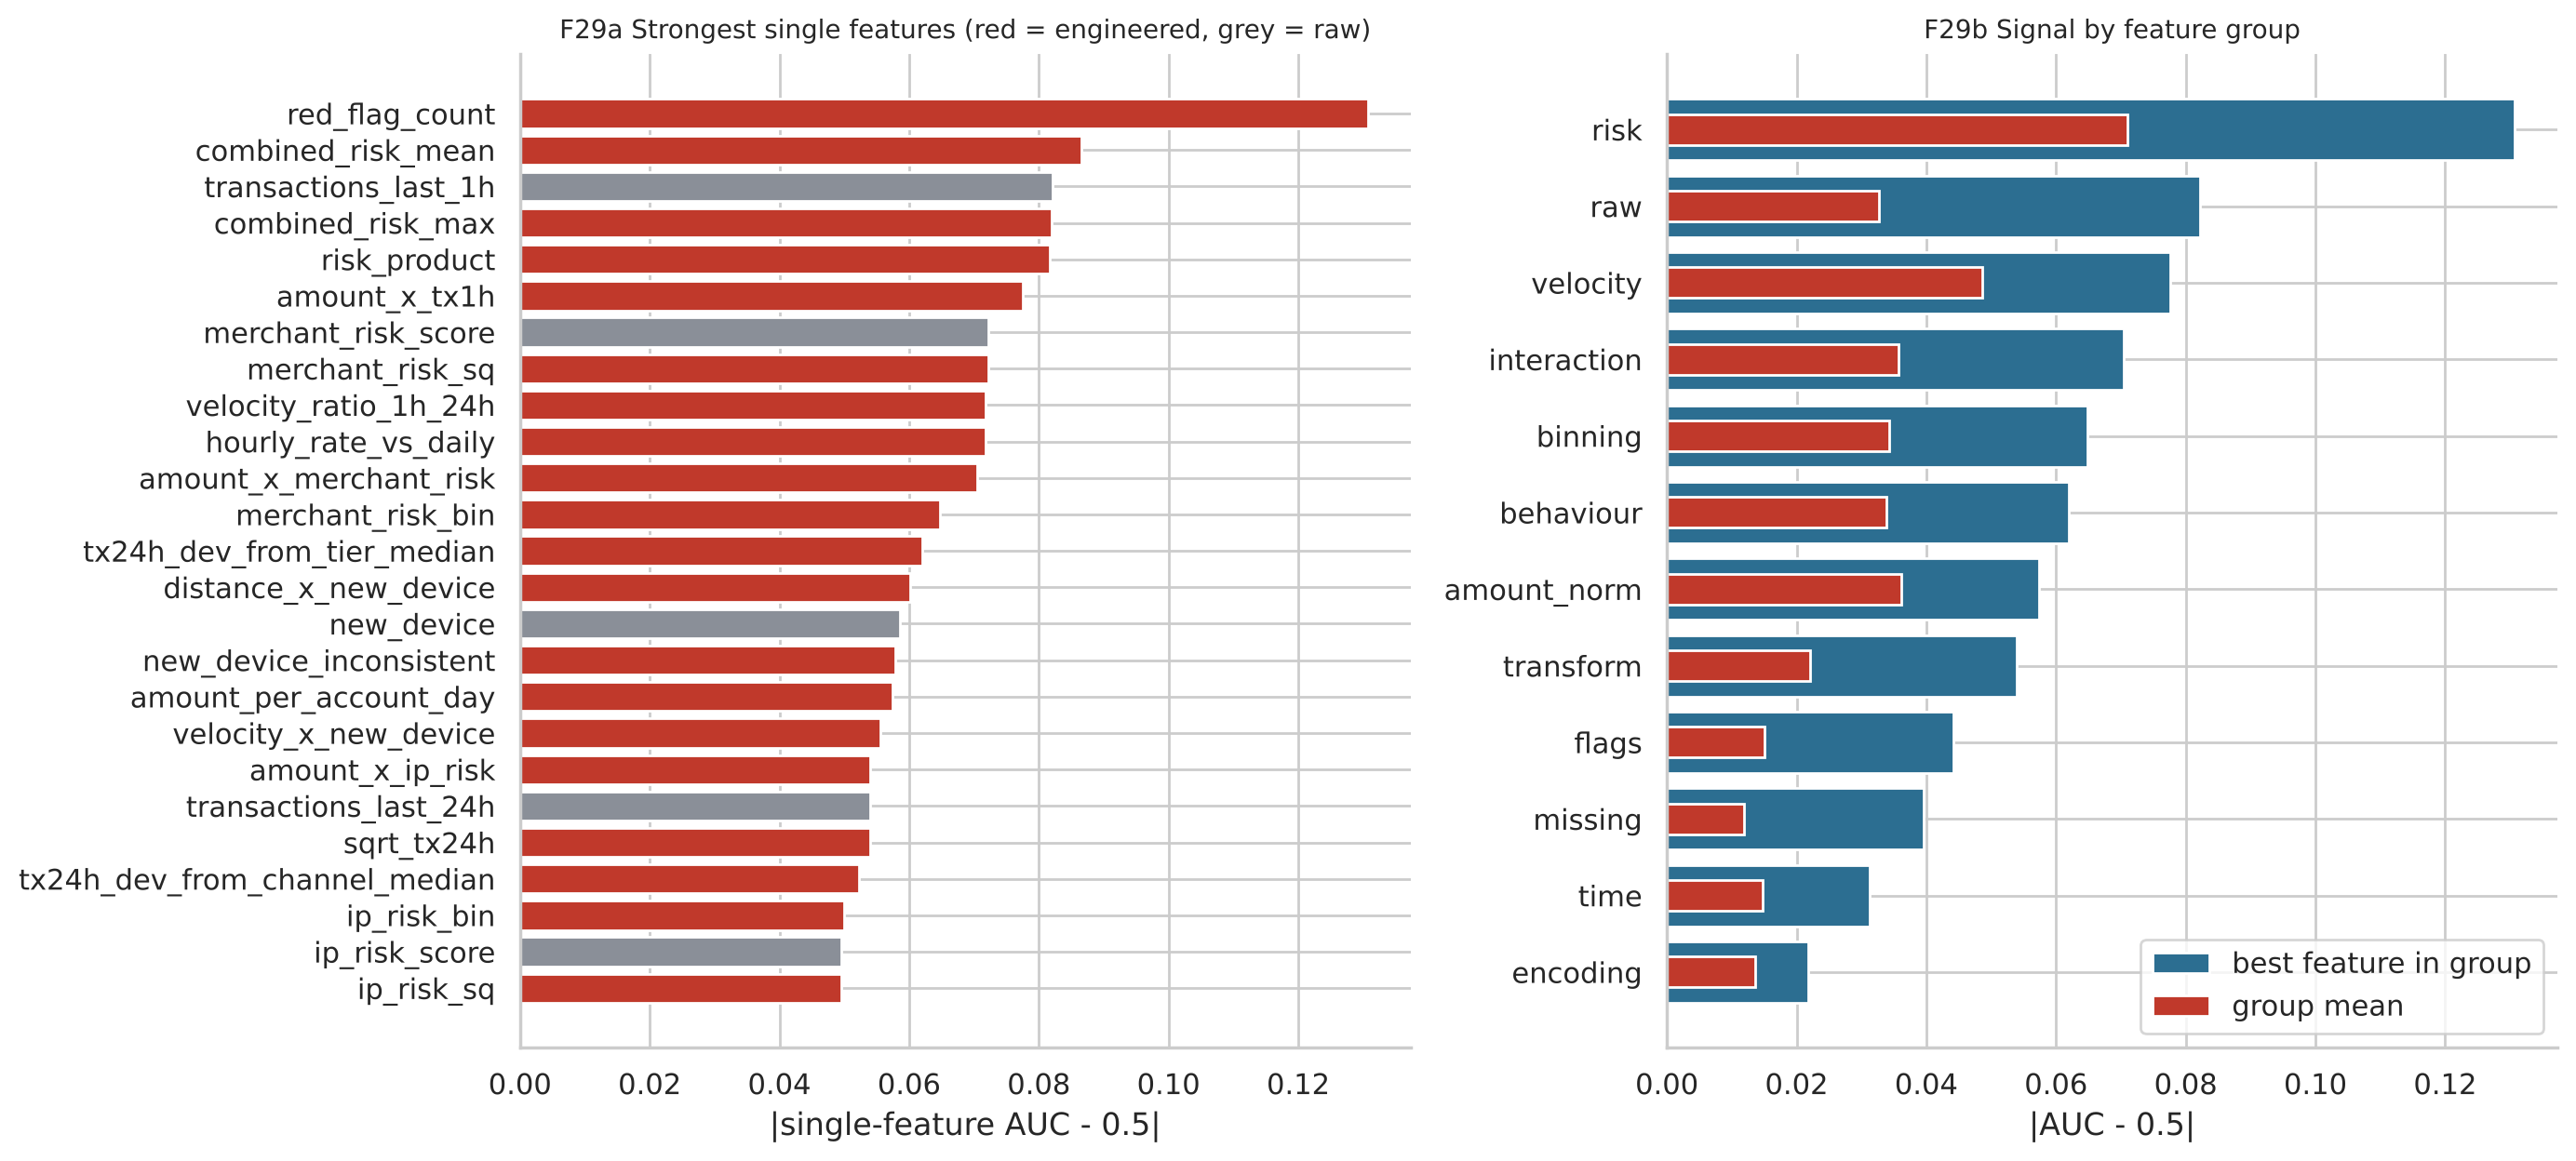

In [10]:
from sklearn.feature_selection import mutual_info_classif
fe_eda = FeatureEngineer().fit(X_dev); Fd = fe_eda.transform(X_dev)
num_feats = [c for c in Fd.columns if c not in CAT_RAW and c not in TE_COLS]
rows = []
Xn = Fd[num_feats].astype(float); Xn_f = Xn.fillna(Xn.median())
mi = mutual_info_classif(Xn_f, y_dev, random_state=SEED, discrete_features=False)
for c, m_ in zip(num_feats, mi):
    s = Xn[c]; ok = s.notna()
    auc = roc_auc_score(y_dev[ok], s[ok]) if s[ok].nunique() > 1 else 0.5
    rows.append(dict(feature=c, kind="engineered" if c in FE_GROUP else "raw", group=FE_GROUP.get(c, "raw"), auc=auc, strength=abs(auc - .5), mutual_info=m_,
                     spearman=stats.spearmanr(s[ok], y_dev[ok])[0] if s[ok].nunique() > 1 else 0.0, pct_missing=100 * (1 - ok.mean())))
uni = pd.DataFrame(rows).sort_values("strength", ascending=False); uni.round(4).to_csv("feature_univariate_evaluation.csv", index=False)
display(uni.head(25).round(4))
R["uni_top"] = uni.head(25).round(4).to_dict("records")
R["uni_summary"] = dict(n_eng=int((uni.kind == "engineered").sum()), n_eng_beat_best_raw=int(((uni.kind == "engineered") & (uni.strength > uni[uni.kind == "raw"].strength.max())).sum()),
                        best_raw=uni[uni.kind == "raw"].iloc[0][["feature", "strength"]].to_dict(), best_eng=uni[uni.kind == "engineered"].iloc[0][["feature", "strength"]].to_dict())
print(R["uni_summary"])
fig, ax = plt.subplots(1, 2, figsize=(14, 6.4))
t = uni.head(25)[::-1]; ax[0].barh(t.feature, t.strength, color=[C_FRAUD if k == "engineered" else C_GREY for k in t.kind]); ax[0].set_xlabel("|single-feature AUC - 0.5|"); ax[0].set_title("F29a Strongest single features (red = engineered, grey = raw)", fontsize=10)
gs_ = uni.groupby("group").strength.agg(["max", "mean"]).sort_values("max"); ax[1].barh(gs_.index, gs_["max"], color=C_OK, label="best feature in group"); ax[1].barh(gs_.index, gs_["mean"], color=C_FRAUD, height=.4, label="group mean"); ax[1].legend(); ax[1].set_xlabel("|AUC - 0.5|"); ax[1].set_title("F29b Signal by feature group", fontsize=10); savefig("F29_feature_univariate")

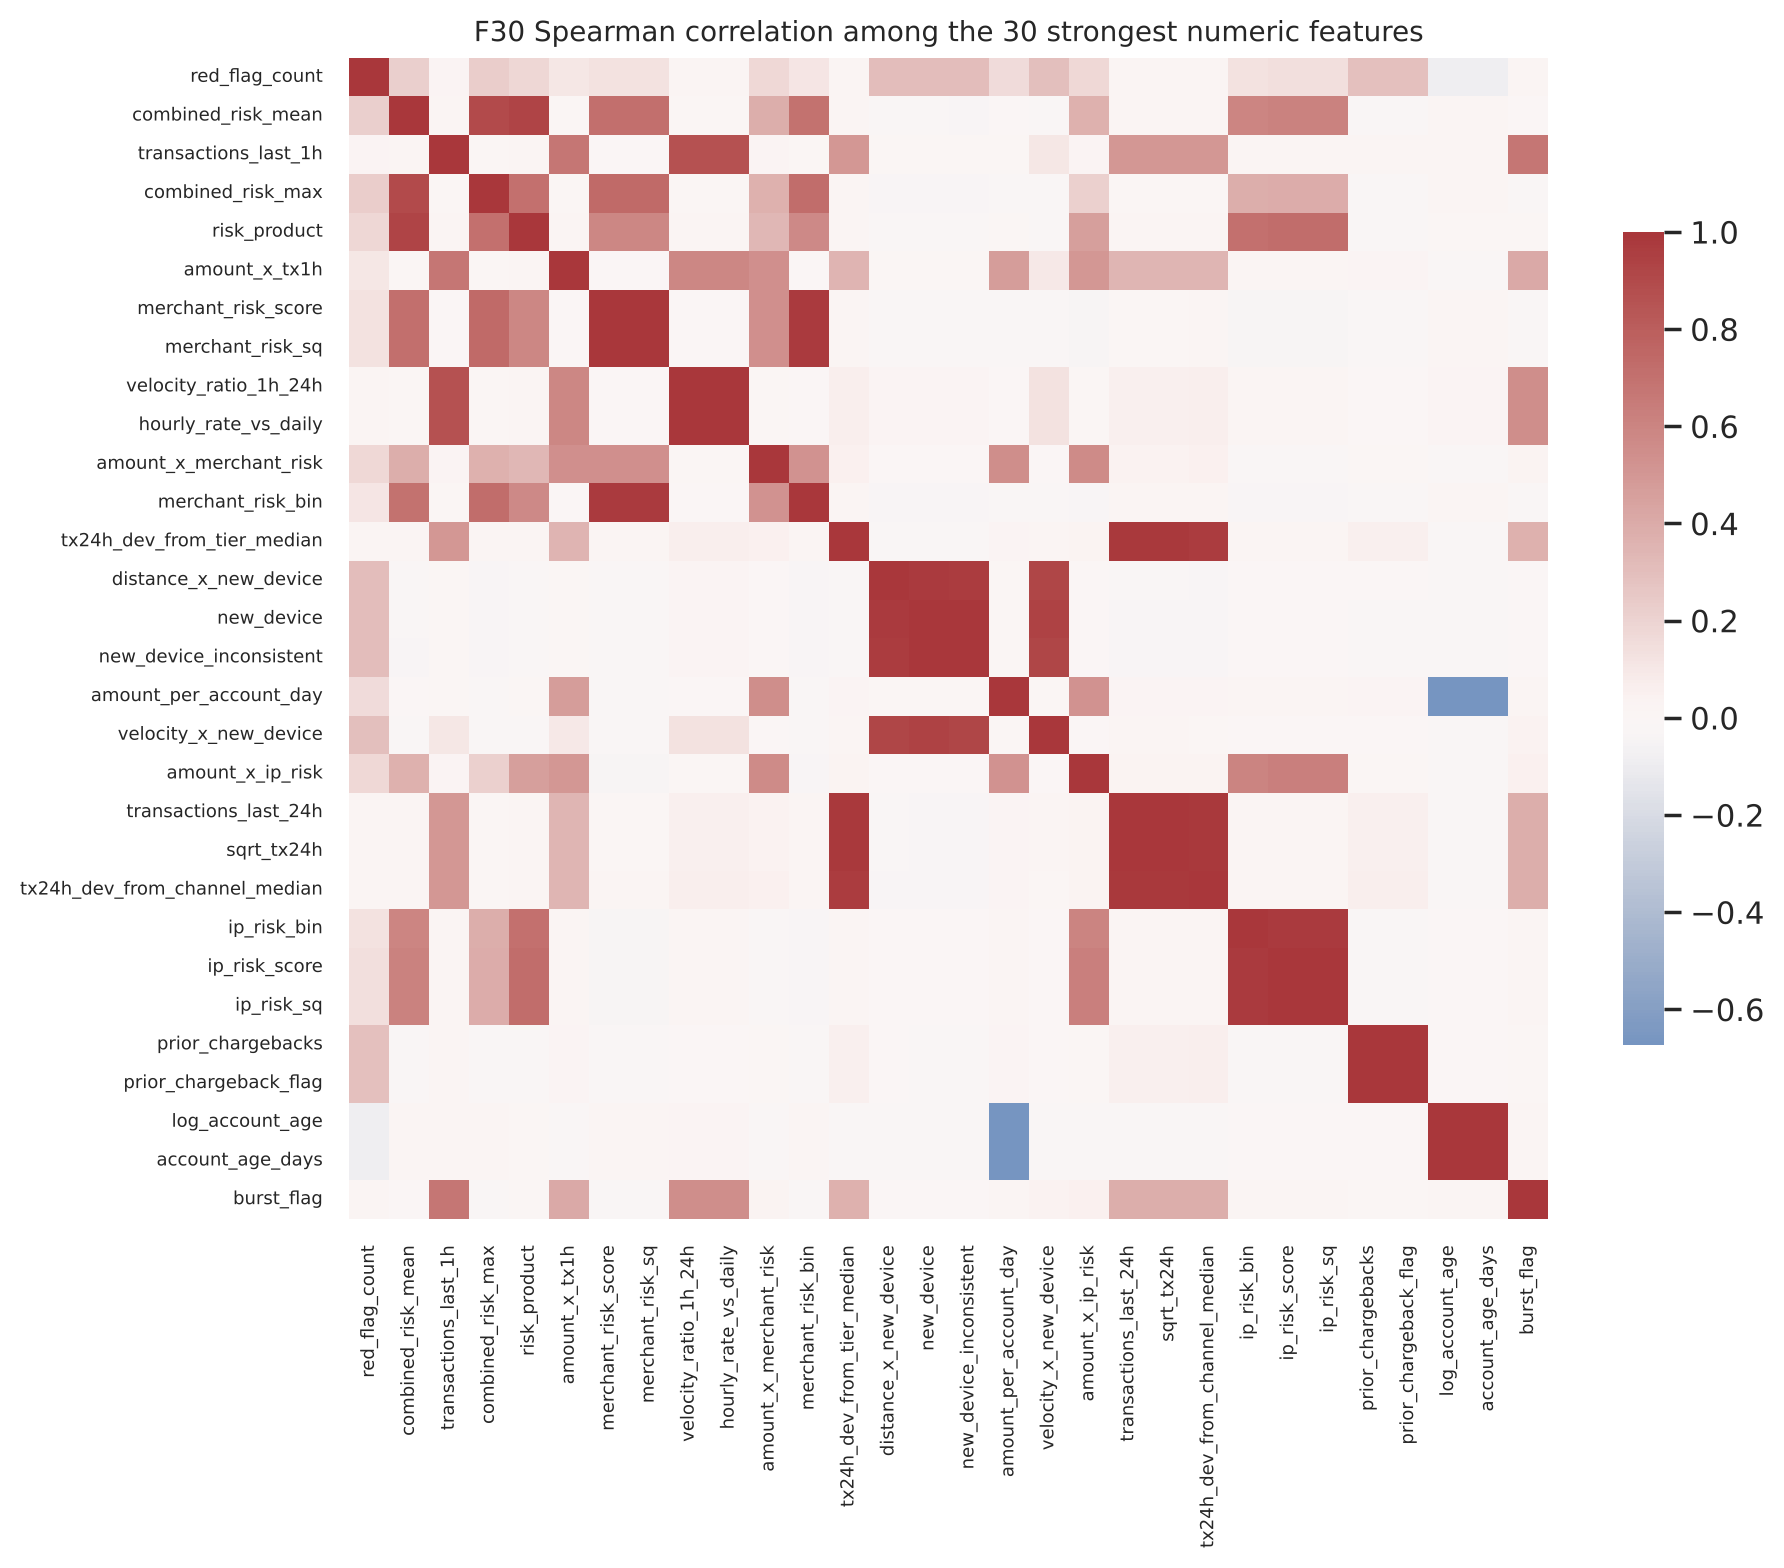

63 feature pairs with |rho| > 0.95 (near-duplicates; harmless for trees, handled by L2 for LogReg)


,a,b,abs_spearman
1926,log_login_minutes,login_z,1.0
1075,ip_risk_score,ip_risk_sq,1.0
310,distance_from_usual_location_km,log_distance_km,1.0
317,distance_from_usual_location_km,distance_pct_rank,1.0
1141,email_age_days,log_email_age,1.0
1266,login_to_transaction_minutes,login_z,1.0
873,device_age_days,log_device_age,1.0
212,transaction_amount,log_amount,1.0
1229,login_to_transaction_minutes,log_login_minutes,1.0
1486,log_amount,amount_pct_rank,1.0


In [11]:
# redundancy: highly correlated engineered pairs, and a clustered correlation map of the 30 strongest numeric features
top30 = list(uni.head(30).feature); cm30 = Xn_f[top30].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8)); sns.heatmap(cm30, cmap="vlag", center=0, ax=ax, xticklabels=True, yticklabels=True, cbar_kws=dict(shrink=.7)); ax.tick_params(labelsize=6.5); ax.set_title("F30 Spearman correlation among the 30 strongest numeric features", fontsize=10); savefig("F30_feature_correlation")
cc = Xn_f.corr(method="spearman").abs(); iu = np.triu_indices_from(cc, 1)
pairs = pd.DataFrame({"a": cc.columns[iu[0]], "b": cc.columns[iu[1]], "abs_spearman": cc.values[iu]}).sort_values("abs_spearman", ascending=False)
red = pairs[pairs.abs_spearman > 0.95]; print(f"{len(red)} feature pairs with |rho| > 0.95 (near-duplicates; harmless for trees, handled by L2 for LogReg)")
R["n_redundant_pairs"] = int(len(red)); display(pairs.head(12).round(3)); R["redundant_pairs_top"] = pairs.head(12).round(3).to_dict("records")

### C2. Target-encoded category combinations (rates learned inside CV)
Smoothed fraud rate of the strongest category combinations on the dev set (n >= 25 only), to show *why* these encodings are included.

In [12]:
combo = Fd.assign(fraud=y_dev.values); te_rows = []
for c in TE_COLS:
    g = combo.groupby(c).fraud.agg(["mean", "count"]); g = g[g["count"] >= 25].sort_values("mean", ascending=False)
    for lab, r_ in list(g.head(2).iterrows()) + list(g.tail(1).iterrows()):
        te_rows.append(dict(combination=c.replace("combo_", ""), level=lab, n=int(r_["count"]), fraud_rate=r_["mean"]))
te_tab = pd.DataFrame(te_rows).round(3); display(te_tab); R["te_levels"] = te_tab.to_dict("records")

,combination,level,n,fraud_rate
0,channel_merchant,E-commerce|Jewelry,31,0.323
1,channel_merchant,Mobile App|Fashion,54,0.241
2,channel_merchant,POS|Digital Services,89,0.045
3,auth_channel,Missing|Mobile App,48,0.250
4,auth_channel,Missing|E-commerce,88,0.239
5,auth_channel,Strong|POS,362,0.080
6,country_device,UAE|iOS,48,0.250
7,country_device,India|Windows,28,0.179
8,country_device,Singapore|iOS,55,0.036
9,tier_channel,Basic|E-commerce,339,0.186


### C3. Ablation: what is each feature group worth? (5-fold CV, identical folds, fixed reasonable hyper-parameters)
*Add-one*: raw columns + one group. *Drop-one*: all groups except one. Positive "drop" values mean removing the group hurts.

,model,setting,pr_auc,roc_auc,d_pr_vs_raw,d_roc_vs_raw
0,LogReg,raw features only,0.2470,0.6693,0.0000,0.0000
1,LogReg,ALL 11 groups,0.2581,0.6840,0.0111,0.0147
2,LogReg,add only: transform,0.2394,0.6687,-0.0076,-0.0006
3,LogReg,drop: transform,0.2587,0.6842,0.0117,0.0149
4,LogReg,add only: velocity,0.2447,0.6669,-0.0023,-0.0025
5,LogReg,drop: velocity,0.2597,0.6856,0.0127,0.0163
6,LogReg,add only: amount_norm,0.2480,0.6804,0.0010,0.0111
7,LogReg,drop: amount_norm,0.2506,0.6742,0.0036,0.0049
8,LogReg,add only: risk,0.2444,0.6665,-0.0026,-0.0029
9,LogReg,drop: risk,0.2558,0.6848,0.0088,0.0155


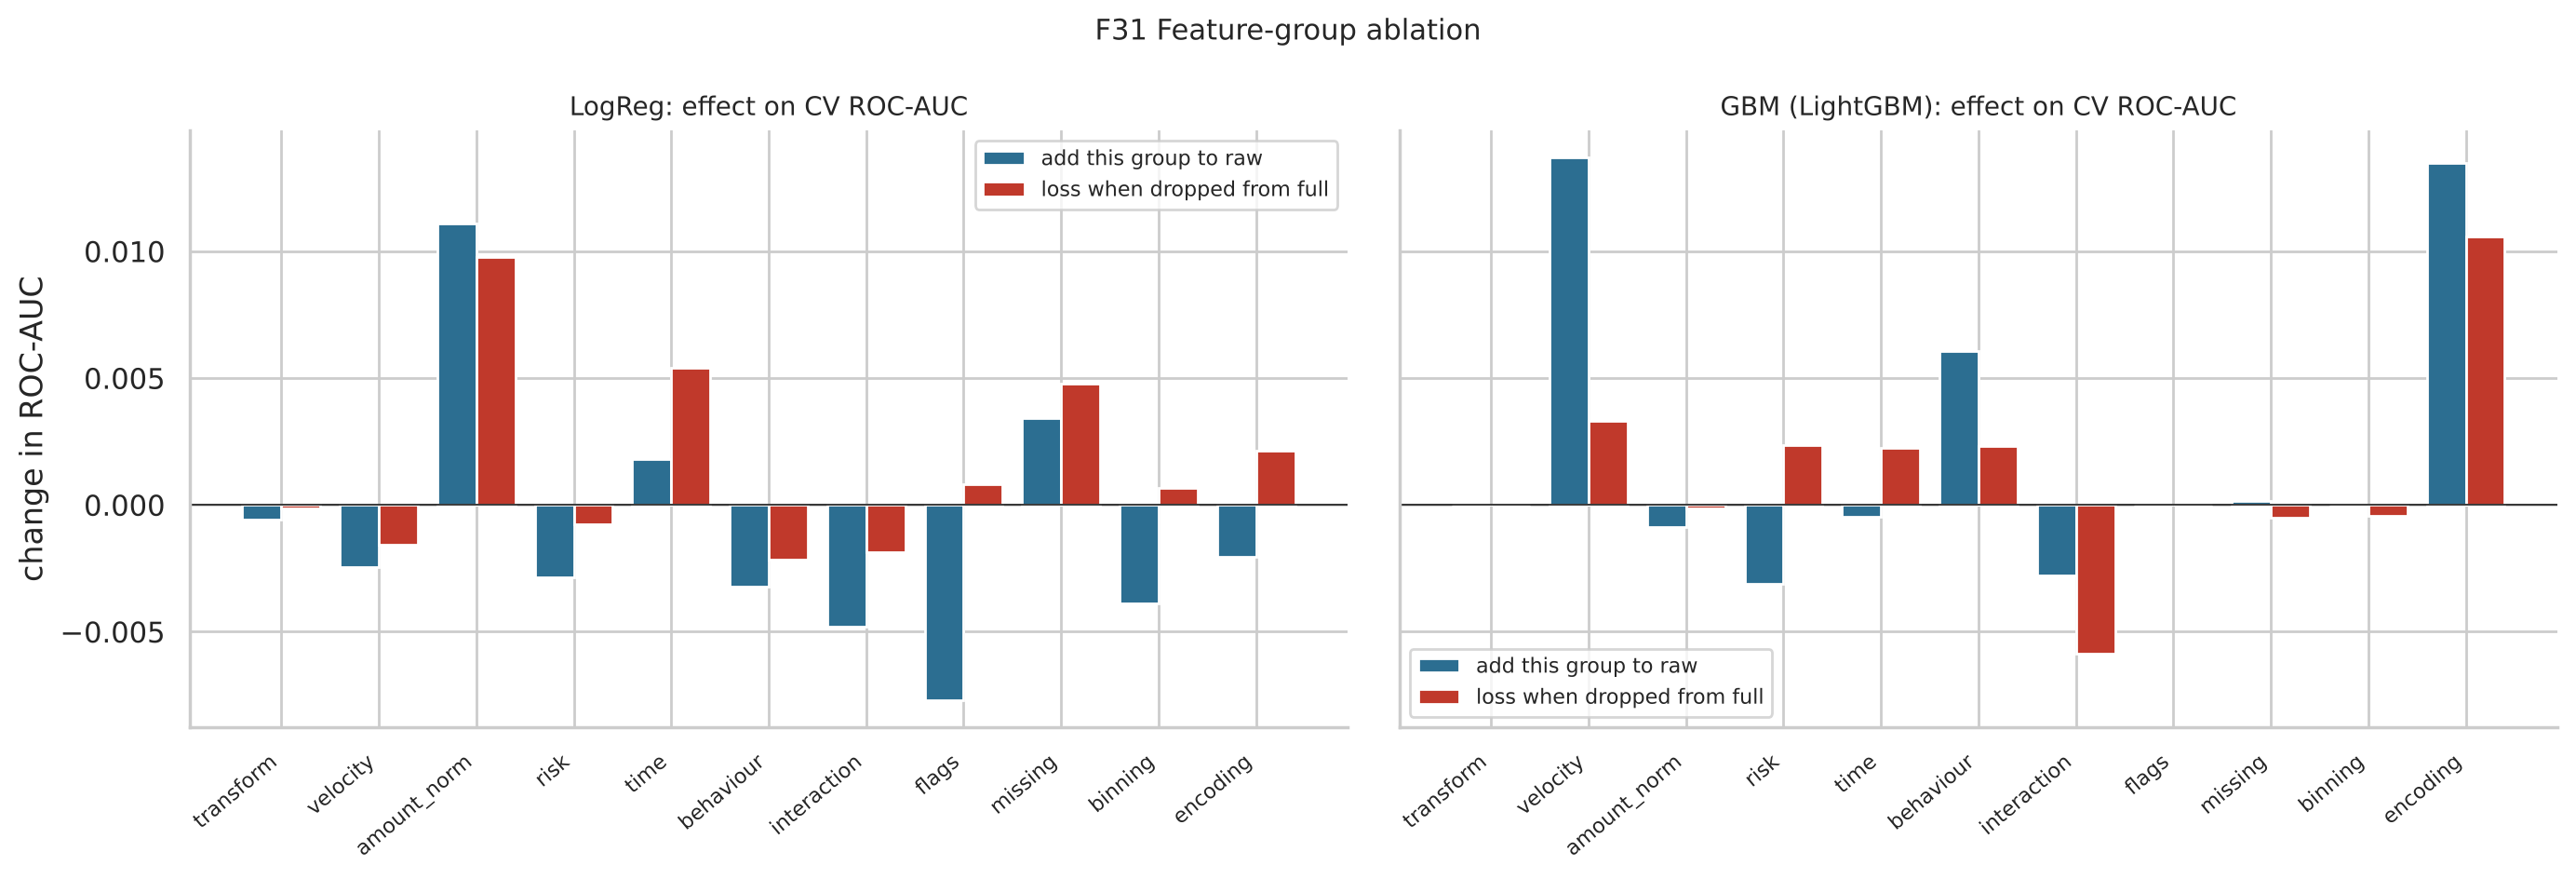

In [13]:
ABL_LR = lambda: LogisticRegression(max_iter=5000, C=0.01, random_state=SEED)
ABL_GB = lambda: LGBMClassifier(n_estimators=200, learning_rate=0.02, num_leaves=4, min_child_samples=80, random_state=SEED, n_jobs=1, verbose=-1)
def oof_scores(est, X, y):
    _, fm, _ = cv_eval(est, X, y); return fm.pr_auc.mean(), fm.roc_auc.mean()
# helper defined here because the abalation needs it before section D
def recall_at_top(y, p, share=0.10):
    k = int(np.ceil(share * len(p))); idx = np.argsort(-p)[:k]; return float(np.asarray(y)[idx].sum() / np.sum(y))
def fold_metrics(y, p):
    return dict(pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p), brier=brier_score_loss(y, p), recall_at_10pct=recall_at_top(y, p))
def cv_eval(est, X, y, cv=None):
    cv = cv or CV; oof = np.zeros(len(y)); rows = []; models = []
    for k, (tr, va) in enumerate(cv.split(X, y)):
        m = clone(est).fit(X.iloc[tr], y.iloc[tr]); p = m.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p; rows.append(dict(fold=k, **fold_metrics(y.iloc[va], p))); models.append(m)
    return oof, pd.DataFrame(rows), models
def summarise(fm): return {m: f"{fm[m].mean():.3f} +/- {fm[m].std():.3f}" for m in ["pr_auc", "roc_auc", "brier", "recall_at_10pct"]}

abl = []
for mname, mk, sc in [("LogReg", ABL_LR, True), ("GBM (LightGBM)", ABL_GB, False)]:
    pr0, roc0 = oof_scores(make_pipeline(mk(), use_fe=False, scale=sc), X_dev, y_dev); prF, rocF = oof_scores(make_pipeline(mk(), True, sc), X_dev, y_dev)
    abl.append(dict(model=mname, setting="raw features only", pr_auc=pr0, roc_auc=roc0)); abl.append(dict(model=mname, setting="ALL 11 groups", pr_auc=prF, roc_auc=rocF))
    for g in GROUPS:
        pa, ra = oof_scores(make_pipeline(mk(), True, sc, groups=[g]), X_dev, y_dev); pd_, rd = oof_scores(make_pipeline(mk(), True, sc, groups=[x for x in GROUPS if x != g]), X_dev, y_dev)
        abl.append(dict(model=mname, setting=f"add only: {g}", pr_auc=pa, roc_auc=ra)); abl.append(dict(model=mname, setting=f"drop: {g}", pr_auc=pd_, roc_auc=rd))
abl = pd.DataFrame(abl); abl["d_pr_vs_raw"] = abl.pr_auc - abl.groupby("model").pr_auc.transform("first"); abl["d_roc_vs_raw"] = abl.roc_auc - abl.groupby("model").roc_auc.transform("first")
display(abl.round(4)); abl.round(4).to_csv("feature_group_ablation.csv", index=False); R["ablation"] = abl.round(4).to_dict("records")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for a, mname in zip(axs, ["LogReg", "GBM (LightGBM)"]):
    d_ = abl[(abl.model == mname) & abl.setting.str.startswith("add only")].copy(); d_["g"] = d_.setting.str.replace("add only: ", ""); dd = abl[(abl.model == mname) & abl.setting.str.startswith("drop")].copy(); dd["g"] = dd.setting.str.replace("drop: ", "")
    full = abl[(abl.model == mname) & (abl.setting == "ALL 11 groups")].roc_auc.iloc[0]; raw0 = abl[(abl.model == mname) & (abl.setting == "raw features only")].roc_auc.iloc[0]
    xx = np.arange(len(d_)); a.bar(xx - .2, d_.roc_auc - raw0, .4, color=C_OK, label="add this group to raw"); a.bar(xx + .2, full - dd.roc_auc.values, .4, color=C_FRAUD, label="loss when dropped from full")
    a.axhline(0, color="k", lw=.6); a.set_xticks(xx); a.set_xticklabels(d_.g, rotation=40, ha="right", fontsize=8); a.set_title(f"{mname}: effect on CV ROC-AUC", fontsize=10); a.legend(fontsize=8)
axs[0].set_ylabel("change in ROC-AUC"); fig.suptitle("F31 Feature-group ablation", fontsize=11); savefig("F31_feature_group_ablation")

### C4. Does feature *selection* help? (mutual-information SelectKBest inside the CV pipeline, selection re-fitted on every training fold)

In [14]:
sel_rows = []
for mname, mk, sc in [("LogReg", ABL_LR, True), ("GBM (LightGBM)", ABL_GB, False)]:
    for k in [20, 40, 70, None]:
        p_, r_ = oof_scores(make_pipeline(mk(), True, sc, select_k=k), X_dev, y_dev); sel_rows.append(dict(model=mname, k=("all (~140)" if k is None else k), pr_auc=p_, roc_auc=r_))
selk = pd.DataFrame(sel_rows).round(4); display(selk); R["selection"] = selk.to_dict("records")
mean_pr = selk.groupby("k").pr_auc.mean(); base_pr_all = mean_pr[[i for i in mean_pr.index if str(i).startswith("all")][0]]
others = mean_pr[[i for i in mean_pr.index if not str(i).startswith("all")]]
SELECT_K = int(others.idxmax()) if others.max() - base_pr_all >= 0.005 else None
print("selected k:", SELECT_K, "(None = keep all features; selection only adopted if it improves mean CV PR-AUC by >= 0.005)"); R["select_k"] = SELECT_K

,model,k,pr_auc,roc_auc
0,LogReg,20,0.2319,0.6630
1,LogReg,40,0.2534,0.6760
2,LogReg,70,0.2645,0.6847
3,LogReg,all (~140),0.2581,0.6840
4,GBM (LightGBM),20,0.2156,0.6365
5,GBM (LightGBM),40,0.2287,0.6514
6,GBM (LightGBM),70,0.2424,0.6581
7,GBM (LightGBM),all (~140),0.2538,0.6570


selected k: None (None = keep all features; selection only adopted if it improves mean CV PR-AUC by >= 0.005)


## D. Baseline and advanced models
Common evaluation helper (defined above): reproducible 5-fold stratified CV, out-of-fold (OOF) probabilities and per-fold metrics. Primary metric **PR-AUC** (average precision) because of the 1 : 7 imbalance; ROC-AUC, Brier, and `recall@10%` (share of frauds captured by the highest-scoring 10 % of transactions) are reported alongside.
Candidates: **Logistic Regression** (transparent baseline), **Random Forest**, **Extra Trees**, **HistGradientBoosting**, **LightGBM**, **XGBoost** and a **soft-voting ensemble** of the tuned LogReg + Random Forest + LightGBM.

In [15]:
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
lgbm = lambda **kw: LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1, **kw)
SPACES = {
    "LogReg": dict(est=LogisticRegression(max_iter=5000, random_state=SEED), scale=True, space={"model__C": np.logspace(-3, 0, 30)}, n_iter=15),
    "RandomForest": dict(est=RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=SEED), scale=False,
                         space={"model__max_depth": [3, 4, 6, 8, None], "model__min_samples_leaf": [5, 10, 20, 40], "model__max_features": [0.1, 0.2, 0.35, "sqrt"]}, n_iter=14),
    "ExtraTrees": dict(est=ExtraTreesClassifier(n_estimators=300, n_jobs=1, random_state=SEED), scale=False,
                       space={"model__max_depth": [3, 4, 6, 8, None], "model__min_samples_leaf": [5, 10, 15, 30], "model__max_features": [0.1, 0.2, 0.35, "sqrt"]}, n_iter=14),
    "HistGradBoosting": dict(est=HistGradientBoostingClassifier(random_state=SEED), scale=False,
                             space={"model__learning_rate": np.logspace(-2.2, -0.7, 12), "model__max_leaf_nodes": [4, 6, 8, 16], "model__min_samples_leaf": [10, 20, 40, 80],
                                    "model__l2_regularization": np.logspace(-3, 1, 8), "model__max_iter": [100, 200, 300]}, n_iter=16),
    "LightGBM": dict(est=lgbm(), scale=False,
                     space={"model__n_estimators": [100, 200, 300, 500], "model__learning_rate": np.logspace(-2.2, -0.8, 10), "model__num_leaves": [4, 6, 8, 12, 16],
                            "model__min_child_samples": [10, 20, 40, 80], "model__subsample": [0.6, 0.8, 1.0], "model__subsample_freq": [1],
                            "model__colsample_bytree": [0.2, 0.4, 0.6, 0.8], "model__reg_lambda": np.logspace(-2, 1.5, 8)}, n_iter=20),
    "XGBoost": dict(est=XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, eval_metric="logloss", verbosity=0), scale=False,
                    space={"model__n_estimators": [100, 200, 300, 500], "model__learning_rate": np.logspace(-2.2, -0.8, 10), "model__max_depth": [2, 3, 4], "model__min_child_weight": [1, 5, 10, 20],
                           "model__subsample": [0.6, 0.8, 1.0], "model__colsample_bytree": [0.2, 0.4, 0.6, 0.8], "model__reg_lambda": np.logspace(-1, 1.5, 8)}, n_iter=20),
}

### D1. Baseline: transparent Logistic Regression (untuned, C = 1), raw vs engineered features

In [16]:
base_rows = []
for fe in [False, True]:
    oof, fm, _ = cv_eval(make_pipeline(LogisticRegression(max_iter=5000, random_state=SEED), use_fe=fe, scale=True, select_k=SELECT_K if fe else None), X_dev, y_dev)
    base_rows.append(dict(model="LogReg (C=1, untuned)", engineered_features=fe, **summarise(fm)))
display(pd.DataFrame(base_rows)); R["baseline_rows"] = base_rows

,model,engineered_features,pr_auc,roc_auc,brier,recall_at_10pct
0,"LogReg (C=1, untuned)",False,0.249 +/- 0.033,0.665 +/- 0.026,0.104 +/- 0.004,0.230 +/- 0.042
1,"LogReg (C=1, untuned)",True,0.238 +/- 0.030,0.662 +/- 0.016,0.107 +/- 0.004,0.230 +/- 0.025


### D2. Hyper-parameter optimisation (RandomizedSearchCV, scoring = PR-AUC, same 5 folds, seed 42)
Tuning uses the development set only, with the full engineered feature set. The complete search log is saved to `hpo_log.csv`.

In [17]:
best_est, hpo_logs, tuned_params = {}, [], {}
t0 = time.time()
for name, cfg in SPACES.items():
    pipe = make_pipeline(cfg["est"], use_fe=True, scale=cfg["scale"], select_k=SELECT_K)
    rs = RandomizedSearchCV(pipe, cfg["space"], n_iter=cfg["n_iter"], scoring="average_precision", cv=CV, random_state=SEED, n_jobs=2, refit=False)
    rs.fit(X_dev, y_dev)
    res = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
    res.insert(0, "model", name); hpo_logs.append(res[["model", "rank_test_score", "mean_test_score", "std_test_score", "params"]])
    tuned_params[name] = rs.best_params_
    best_est[name] = clone(pipe).set_params(**rs.best_params_)
    print(f"{name:17s} best CV PR-AUC {rs.best_score_:.3f}  params={ {k.split('__')[1]: (round(v,4) if isinstance(v,float) else v) for k,v in rs.best_params_.items()} }  [{time.time()-t0:.0f}s]")
best_est["Ensemble"] = VotingClassifier([("lr", clone(best_est["LogReg"])), ("rf", clone(best_est["RandomForest"])), ("lgbm", clone(best_est["LightGBM"]))], voting="soft")
pd.concat(hpo_logs).astype({"params": str}).to_csv("hpo_log.csv", index=False)
print(f"HPO finished in {time.time()-t0:.0f}s")
def _jf(vv): return float(vv) if isinstance(vv, (float, np.floating)) else (int(vv) if isinstance(vv, (int, np.integer)) else vv)
R["tuned_params"] = {k: {kk.split("__")[1]: _jf(vv) for kk, vv in v.items()} for k, v in tuned_params.items()}
R["hpo_top"] = {n: [dict(rank=int(r.rank_test_score), mean=float(r.mean_test_score), sd=float(r.std_test_score), params=str(r.params)) for r in df_.head(3).itertuples()] for n, df_ in zip(SPACES, hpo_logs)}
R["hpo_n_iter"] = {k: v["n_iter"] for k, v in SPACES.items()}

LogReg            best CV PR-AUC 0.261  params={'C': np.float64(0.0033)}  [8s]


RandomForest      best CV PR-AUC 0.238  params={'min_samples_leaf': 40, 'max_features': 0.1, 'max_depth': 6}  [49s]


ExtraTrees        best CV PR-AUC 0.247  params={'min_samples_leaf': 10, 'max_features': 0.1, 'max_depth': 8}  [71s]


HistGradBoosting  best CV PR-AUC 0.251  params={'min_samples_leaf': 80, 'max_leaf_nodes': 6, 'max_iter': 300, 'learning_rate': np.float64(0.0063), 'l2_regularization': np.float64(0.7197)}  [97s]


LightGBM          best CV PR-AUC 0.260  params={'subsample_freq': 1, 'subsample': 1.0, 'reg_lambda': np.float64(10.0), 'num_leaves': 4, 'n_estimators': 100, 'min_child_samples': 80, 'learning_rate': np.float64(0.0185), 'colsample_bytree': 0.8}  [114s]


XGBoost           best CV PR-AUC 0.247  params={'subsample': 0.6, 'reg_lambda': np.float64(13.895), 'n_estimators': 200, 'min_child_weight': 20, 'max_depth': 2, 'learning_rate': np.float64(0.0129), 'colsample_bytree': 0.8}  [133s]
HPO finished in 133s


### D3. Model comparison with vs without engineered features (same folds, same hyper-parameters)

,model,engineered_features,pr_auc,roc_auc,brier,recall_at_10pct,pr_auc_sd,roc_auc_sd
0,LogReg,False,0.2425,0.6668,0.1046,0.2302,0.0270,0.0255
1,LogReg,True,0.2607,0.6849,0.1017,0.2613,0.0366,0.0367
2,RandomForest,False,0.2218,0.6562,0.1041,0.2059,0.0440,0.0143
3,RandomForest,True,0.2384,0.6629,0.1031,0.2129,0.0505,0.0362
4,ExtraTrees,False,0.2254,0.6335,0.1041,0.2302,0.0411,0.0288
5,ExtraTrees,True,0.2466,0.6771,0.1017,0.2646,0.0318,0.0272
6,HistGradBoosting,False,0.2249,0.6423,0.1034,0.2233,0.0217,0.0133
7,HistGradBoosting,True,0.2508,0.6587,0.1025,0.2303,0.0485,0.0324
8,LightGBM,False,0.2302,0.6531,0.1036,0.2197,0.0277,0.0194
9,LightGBM,True,0.2597,0.6588,0.1029,0.2269,0.0511,0.0444


engineered_features   False    True    gain
model                                      
Ensemble                NaN  0.2614     NaN
ExtraTrees           0.2254  0.2466  0.0212
HistGradBoosting     0.2249  0.2508  0.0259
LightGBM             0.2302  0.2597  0.0295
LogReg               0.2425  0.2607  0.0182
RandomForest         0.2218  0.2384  0.0166
XGBoost              0.1985  0.2471  0.0486


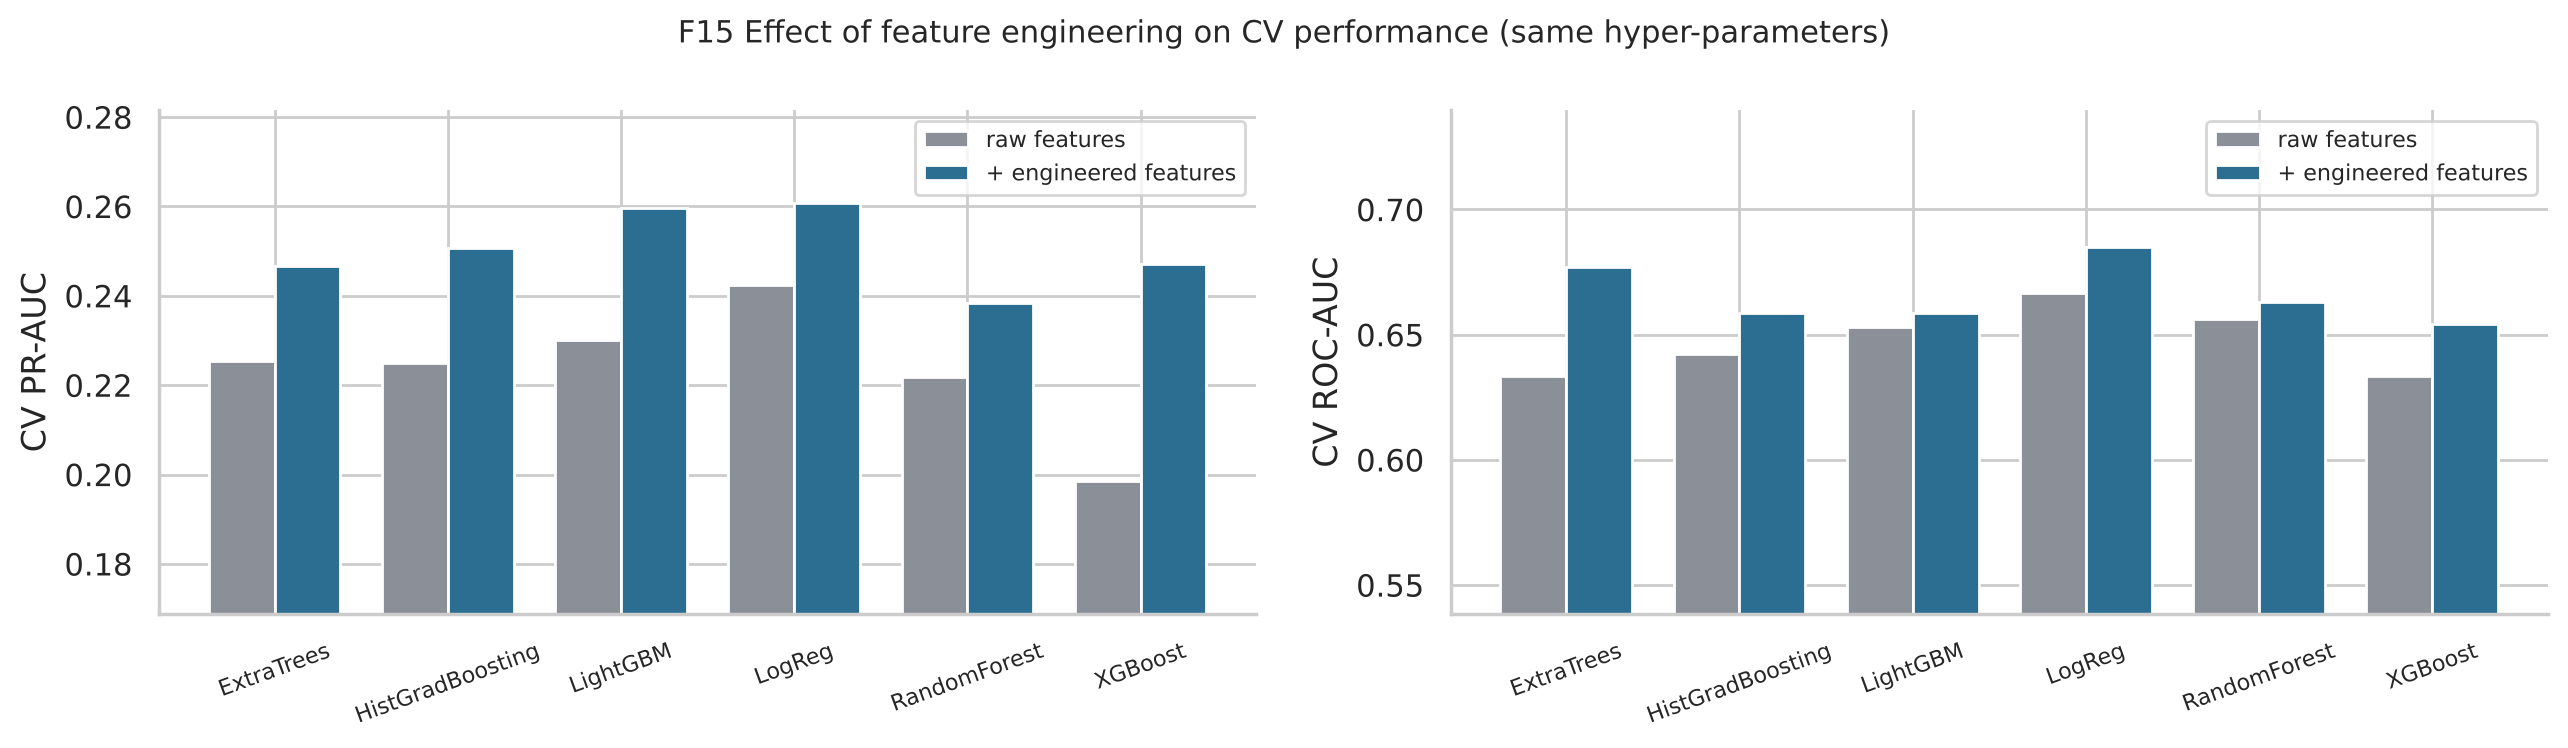

,model,mean_gain_roc,folds_improved_roc,mean_gain_pr,folds_improved_pr
0,LogReg,0.0182,4,0.0182,3
1,RandomForest,0.0068,2,0.0165,3
2,ExtraTrees,0.0436,5,0.0212,4
3,HistGradBoosting,0.0164,4,0.0259,3
4,LightGBM,0.0057,3,0.0295,3
5,XGBoost,0.0211,4,0.0487,4


In [18]:
cmp_rows, OOF, FOLDS, FMODELS = [], {}, {}, {}
for name, est in best_est.items():
    fes = [True] if name == "Ensemble" else [False, True]
    for fe in fes:
        e = clone(est)
        if not fe:  # same hyper-parameters, raw feature pipeline
            e = make_pipeline(clone(est.named_steps["model"]), use_fe=False, scale=SPACES[name]["scale"])
        oof, fm, models = cv_eval(e, X_dev, y_dev)
        cmp_rows.append(dict(model=name, engineered_features=fe, **{k: fm[k].mean() for k in ["pr_auc", "roc_auc", "brier", "recall_at_10pct"]}, pr_auc_sd=fm.pr_auc.std(), roc_auc_sd=fm.roc_auc.std()))
        if fe: OOF[name], FOLDS[name], FMODELS[name] = oof, fm, models
        else: OOF[name + "|raw"] = oof; FOLDS[name + "|raw"] = fm
cmp = pd.DataFrame(cmp_rows).round(4); display(cmp)
R["fe_compare"] = cmp.to_dict("records")
piv = cmp.pivot(index="model", columns="engineered_features", values="pr_auc"); piv["gain"] = piv[True] - piv[False]; print(piv.round(4))
pivr = cmp.pivot(index="model", columns="engineered_features", values="roc_auc"); pivr["gain"] = pivr[True] - pivr[False]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); w = .38
for a, pv, ttl in [(ax[0], piv, "CV PR-AUC"), (ax[1], pivr, "CV ROC-AUC")]:
    pv_ = pv.dropna(); xx = np.arange(len(pv_))
    a.bar(xx - w / 2, pv_[False], w, color=C_GREY, label="raw features"); a.bar(xx + w / 2, pv_[True], w, color=C_OK, label="+ engineered features")
    a.set_xticks(xx); a.set_xticklabels(pv_.index, rotation=20, fontsize=8); a.set_ylabel(ttl); a.legend(fontsize=8); a.set_ylim(pv_[False].min() * .85, pv_[True].max() * 1.08)
ax[0].axhline(R["fraud_rate"], color=C_FRAUD, ls="--", lw=1)
fig.suptitle("F15 Effect of feature engineering on CV performance (same hyper-parameters)", fontsize=11); savefig("F15_fe_comparison")
R["fe_gain_pr"] = piv["gain"].dropna().round(4).to_dict(); R["fe_gain_roc"] = pivr["gain"].dropna().round(4).to_dict()
# paired fold-level test of the gain (is it more than noise?)
pt_rows = []
for name in best_est:
    if name == "Ensemble": continue
    d1 = FOLDS[name].roc_auc.values - FOLDS[name + "|raw"].roc_auc.values; d2 = FOLDS[name].pr_auc.values - FOLDS[name + "|raw"].pr_auc.values
    pt_rows.append(dict(model=name, mean_gain_roc=d1.mean(), folds_improved_roc=int((d1 > 0).sum()), mean_gain_pr=d2.mean(), folds_improved_pr=int((d2 > 0).sum())))
pt_tab = pd.DataFrame(pt_rows).round(4); display(pt_tab); R["fe_paired"] = pt_tab.to_dict("records")

### D4. Fold-to-fold variability of every tuned model

,model,pr_auc_mean,roc_auc_mean,brier_mean,recall_at_10pct_mean,pr_auc_sd,roc_auc_sd,pr_auc_min,pr_auc_max
0,LogReg,0.2607,0.6849,0.1017,0.2613,0.0366,0.0367,0.2027,0.3027
1,RandomForest,0.2384,0.6629,0.1031,0.2129,0.0505,0.0362,0.1539,0.2876
2,ExtraTrees,0.2466,0.6771,0.1017,0.2646,0.0318,0.0272,0.1936,0.2735
3,HistGradBoosting,0.2508,0.6587,0.1025,0.2303,0.0485,0.0324,0.1680,0.2882
4,LightGBM,0.2597,0.6588,0.1029,0.2269,0.0511,0.0444,0.1752,0.3008
5,XGBoost,0.2471,0.6544,0.1031,0.2234,0.0498,0.0441,0.1696,0.2912
6,Ensemble,0.2614,0.6798,0.1018,0.2440,0.0477,0.0369,0.1861,0.3065


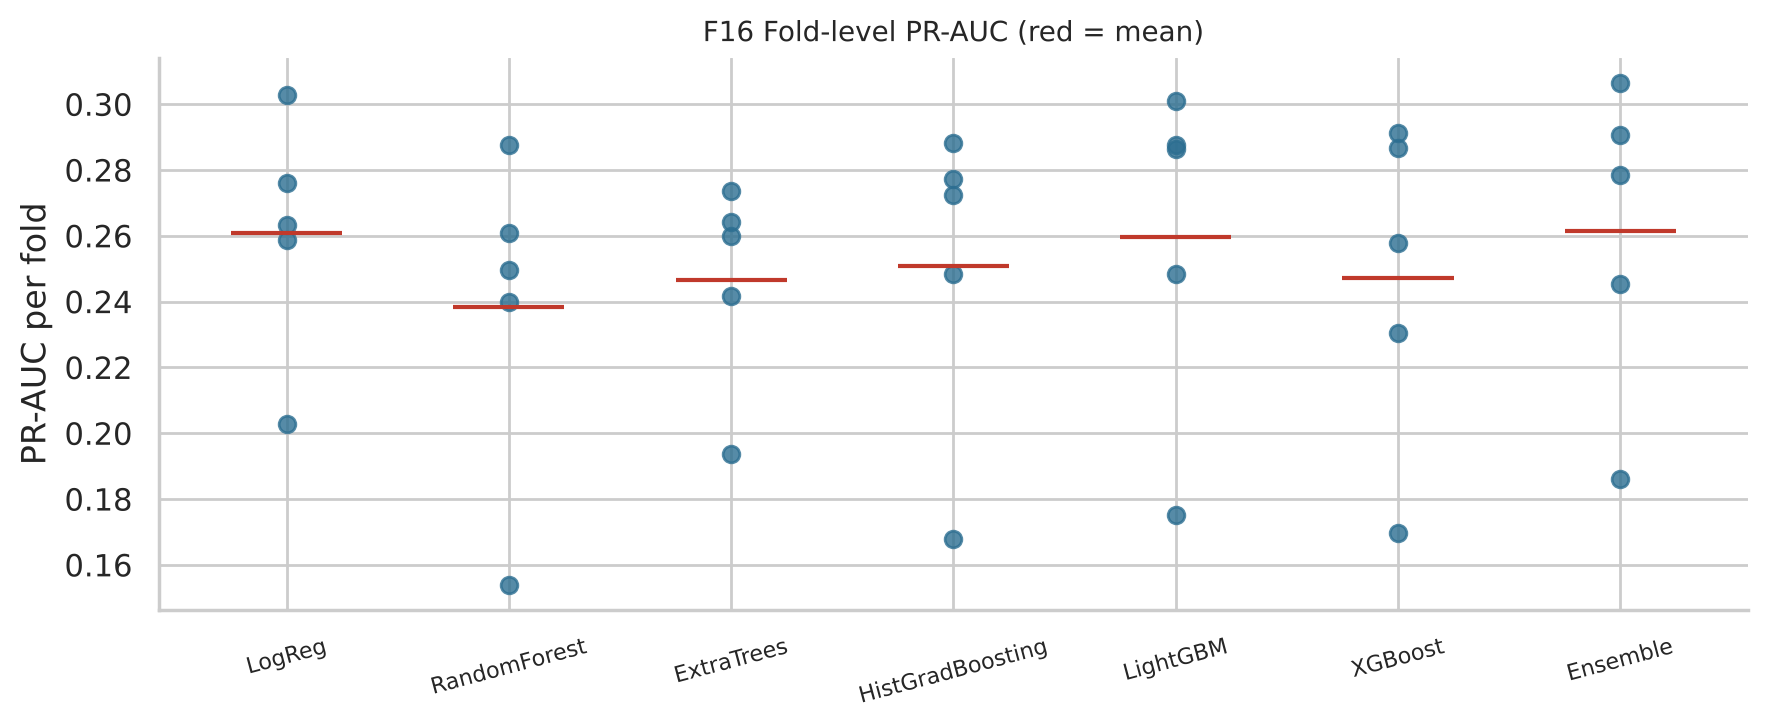

In [19]:
rows = []
for n in best_est:
    f = FOLDS[n]; rows.append(dict(model=n, **{f"{m}_mean": f[m].mean() for m in ["pr_auc", "roc_auc", "brier", "recall_at_10pct"]}, **{f"{m}_sd": f[m].std() for m in ["pr_auc", "roc_auc"]},
                                  pr_auc_min=f.pr_auc.min(), pr_auc_max=f.pr_auc.max()))
var_df = pd.DataFrame(rows).round(4); display(var_df); R["cv_variability"] = var_df.to_dict("records")
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, n in enumerate(best_est): ax.scatter([i] * 5, FOLDS[n].pr_auc, color=C_OK, alpha=.8); ax.hlines(FOLDS[n].pr_auc.mean(), i - .25, i + .25, color=C_FRAUD)
ax.set_xticks(range(len(best_est))); ax.set_xticklabels(best_est, rotation=15, fontsize=8); ax.set_ylabel("PR-AUC per fold"); ax.set_title("F16 Fold-level PR-AUC (red = mean)", fontsize=10); savefig("F16_fold_variability")

### D5. Learning curves: would more data help?

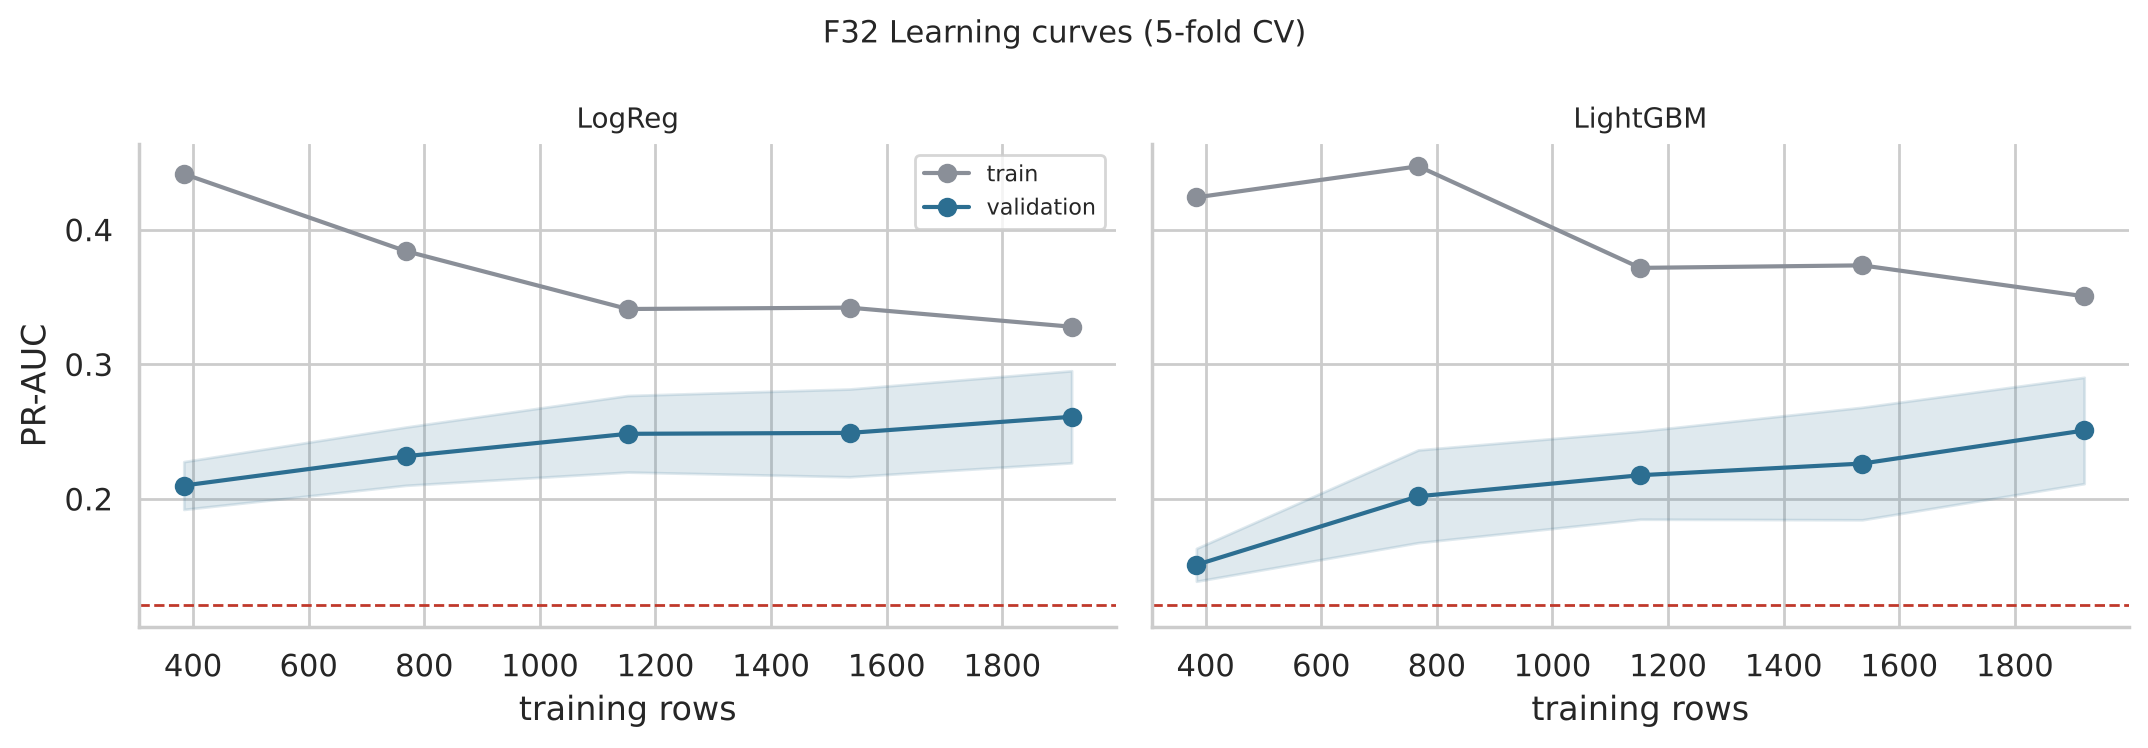

In [20]:
from sklearn.model_selection import learning_curve
lc_fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True); LC = {}
for a, nm in zip(axs, ["LogReg", "LightGBM"]):
    sizes, trs, vas = learning_curve(clone(best_est[nm]), X_dev, y_dev, cv=CV, scoring="average_precision", train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], n_jobs=2, random_state=SEED, shuffle=True)
    a.plot(sizes, trs.mean(1), marker="o", color=C_GREY, label="train"); a.plot(sizes, vas.mean(1), marker="o", color=C_OK, label="validation"); a.fill_between(sizes, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), color=C_OK, alpha=.15)
    a.axhline(R["fraud_rate"], color=C_FRAUD, ls="--", lw=1); a.set_title(f"{nm}", fontsize=10); a.set_xlabel("training rows"); LC[nm] = dict(sizes=sizes.tolist(), train=trs.mean(1).round(4).tolist(), val=vas.mean(1).round(4).tolist())
axs[0].set_ylabel("PR-AUC"); axs[0].legend(fontsize=8); lc_fig.suptitle("F32 Learning curves (5-fold CV)", fontsize=11); savefig("F32_learning_curves"); R["learning_curve"] = LC

## G. Imbalanced learning
Imbalance is **1 : 7.2** (12.1 % fraud). We compare, with the *tuned LightGBM and the LogReg baseline*: (1) nothing, (2) class weighting, (3) SMOTE to 50 % minority ratio, (4) random under-sampling to 50 %. Samplers are placed **after the preprocessing step inside an `imblearn` Pipeline**, so they only ever act on the training portion of each fold; validation folds are never resampled.

In [21]:
def lgb_variant(kind):
    p = {k.split("__")[1]: v for k, v in tuned_params["LightGBM"].items()}
    return lgbm(**p, **({"class_weight": "balanced"} if kind == "class_weight" else {}))

def lr_variant(kind):
    p = {k.split("__")[1]: v for k, v in tuned_params["LogReg"].items()}
    return LogisticRegression(max_iter=5000, random_state=SEED, **p, **({"class_weight": "balanced"} if kind == "class_weight" else {}))

SAMPLERS = {"none": None, "class_weight": None, "SMOTE(0.5)": SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=SEED), "undersample(0.5)": RandomUnderSampler(sampling_strategy=0.5, random_state=SEED)}
imb_rows, IMB_OOF = [], {}
for fam, mk, sc in [("LightGBM", lgb_variant, False), ("LogReg", lr_variant, True)]:
    for kind, smp in SAMPLERS.items():
        oof, fm, _ = cv_eval(make_pipeline(mk(kind), True, sc, sampler=smp, select_k=SELECT_K), X_dev, y_dev)
        IMB_OOF[(fam, kind)] = oof
        imb_rows.append(dict(model=fam, strategy=kind, **{k: fm[k].mean() for k in ["pr_auc", "roc_auc", "brier", "recall_at_10pct"]}, pr_auc_sd=fm.pr_auc.std(), mean_pred=oof.mean()))
imb = pd.DataFrame(imb_rows).round(4); display(imb); R["imbalance"] = imb.to_dict("records")

,model,strategy,pr_auc,roc_auc,brier,recall_at_10pct,pr_auc_sd,mean_pred
0,LightGBM,none,0.2597,0.6588,0.1029,0.2269,0.0511,0.1188
1,LightGBM,class_weight,0.2571,0.6523,0.2228,0.2165,0.0380,0.4657
2,LightGBM,SMOTE(0.5),0.2533,0.6444,0.1155,0.2372,0.0541,0.2347
3,LightGBM,undersample(0.5),0.2182,0.6497,0.1440,0.1992,0.0239,0.3220
4,LogReg,none,0.2607,0.6849,0.1017,0.2613,0.0366,0.1223
5,LogReg,class_weight,0.2593,0.6828,0.2120,0.2578,0.0389,0.4425
6,LogReg,SMOTE(0.5),0.2392,0.6720,0.1419,0.2404,0.0275,0.3049
7,LogReg,undersample(0.5),0.2535,0.6789,0.1432,0.2303,0.0305,0.3188


**Reading the table.** Class weighting / resampling change the *ranking* (PR-AUC, recall@10 %) only marginally but they **inflate the mean predicted probability** (`mean_pred` far above the 12.1 % base rate), i.e. they destroy probability calibration. Since the engine must output a *calibrated probability* used in an expected-cost decision, calibration is applied afterwards (section F) and the strategy is chosen on calibrated cost, not on raw metrics.

## F. Probability calibration
We cross-fit calibrators on the OOF scores (5 inner folds, so no calibration row is scored by a calibrator that has seen it) and compare **raw**, **Platt scaling** (sigmoid on the log-odds) and **isotonic regression**. Isotonic needs more data than Platt (it can over-fit with ~290 positives), which is why both are tested.

In [22]:
def calibrate_oof(oof, y, method, seed=SEED + 1):
    if method == "raw": return np.asarray(oof)
    out = np.zeros(len(oof)); oof = np.asarray(oof)
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(oof.reshape(-1, 1), y):
        if method == "platt":
            lg = lambda p: logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)
            c = LogisticRegression(C=1e6, max_iter=1000).fit(lg(oof[tr]), np.asarray(y)[tr]); out[va] = c.predict_proba(lg(oof[va]))[:, 1]
        else:
            c = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(oof[tr], np.asarray(y)[tr]); out[va] = c.predict(oof[va])
    return out

def calib_row(name, y, p):
    return dict(variant=name, brier=brier_score_loss(y, p), log_loss=log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), ece=expected_calibration_error(y, p), mean_pred=float(np.mean(p)), pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p))

cal_rows, CAL = [], {}
for key, lab in [(("LightGBM", "none"), "LightGBM (unweighted)"), (("LightGBM", "class_weight"), "LightGBM (class_weight)"), (("LightGBM", "SMOTE(0.5)"), "LightGBM (SMOTE)"), (("LogReg", "none"), "LogReg (unweighted)")]:
    for m in ["raw", "platt", "isotonic"]:
        p = calibrate_oof(IMB_OOF[key], y_dev, m); CAL[(lab, m)] = p
        cal_rows.append(dict(**calib_row(f"{lab} | {m}", y_dev, p)))
cal_df = pd.DataFrame(cal_rows).round(4); display(cal_df); R["calibration_table"] = cal_df.to_dict("records")
R["brier_baseline_prevalence"] = float(brier_score_loss(y_dev, np.full(len(y_dev), y_dev.mean())))
print("Brier of constant prevalence predictor:", round(R["brier_baseline_prevalence"], 4))

,variant,brier,log_loss,ece,mean_pred,pr_auc,roc_auc
0,LightGBM (unweighted) | raw,0.1029,0.3539,0.0188,0.1188,0.2357,0.6547
1,LightGBM (unweighted) | platt,0.1022,0.3519,0.0079,0.1213,0.2332,0.6538
2,LightGBM (unweighted) | isotonic,0.1023,0.3622,0.0158,0.1214,0.2194,0.6388
3,LightGBM (class_weight) | raw,0.2228,0.6375,0.3445,0.4657,0.2294,0.6495
4,LightGBM (class_weight) | platt,0.1028,0.3539,0.0110,0.1212,0.2256,0.6477
5,LightGBM (class_weight) | isotonic,0.1028,0.3634,0.0170,0.1212,0.2089,0.6339
6,LightGBM (SMOTE) | raw,0.1155,0.3981,0.1135,0.2347,0.2392,0.6438
7,LightGBM (SMOTE) | platt,0.1023,0.3532,0.0189,0.1212,0.2392,0.6425
8,LightGBM (SMOTE) | isotonic,0.1020,0.3612,0.0141,0.1207,0.2220,0.6352
9,LogReg (unweighted) | raw,0.1017,0.3487,0.0184,0.1223,0.2423,0.6830


Brier of constant prevalence predictor: 0.1065


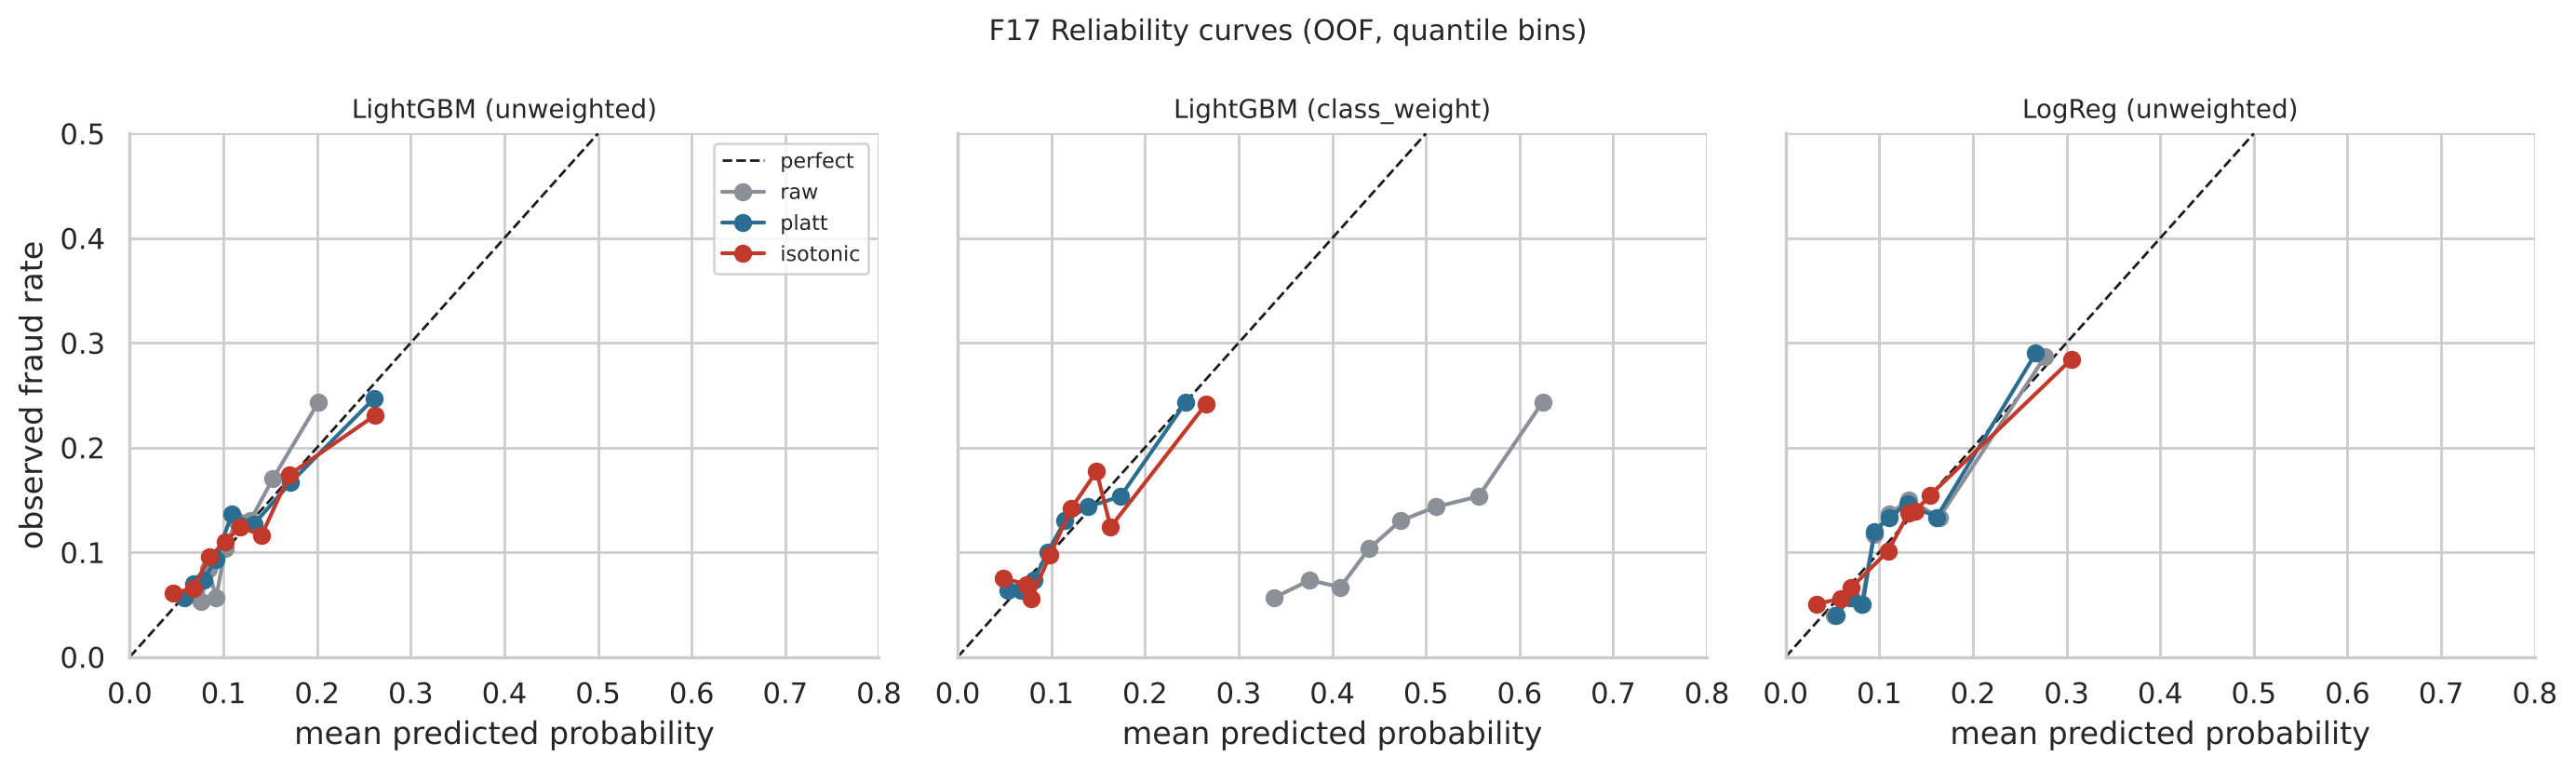

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, lab in zip(axs, ["LightGBM (unweighted)", "LightGBM (class_weight)", "LogReg (unweighted)"]):
    ax.plot([0, .5], [0, .5], "k--", lw=1, label="perfect")
    for m, col in [("raw", C_GREY), ("platt", C_OK), ("isotonic", C_FRAUD)]:
        fr, mp = calibration_curve(y_dev, CAL[(lab, m)], n_bins=8, strategy="quantile"); ax.plot(mp, fr, marker="o", color=col, label=m)
    ax.set_title(lab, fontsize=10); ax.set_xlabel("mean predicted probability"); ax.set_xlim(0, .8); ax.set_ylim(0, .5)
axs[0].set_ylabel("observed fraud rate"); axs[0].legend(fontsize=8); fig.suptitle("F17 Reliability curves (OOF, quantile bins)", fontsize=11); savefig("F17_calibration_curves")

**Operational meaning of calibration.** A raw score of, say, 0.4 from a class-weighted model might correspond to a true fraud rate of only ~15 %. Because the cost framework multiplies a probability by a loss to get an expected loss (Section E), a mis-calibrated probability gives wrong threshold decisions and a wrong estimate of review volume. The table below shows, for the class-weighted model, what the same raw score bands really mean before and after Platt calibration.

In [24]:
lab = "LightGBM (class_weight)"; raw_s = IMB_OOF[("LightGBM", "class_weight")]; cal_s = CAL[(lab, "platt")]
bins = pd.qcut(raw_s, 6, duplicates="drop")
op = pd.DataFrame({"raw_score_band": bins, "y": y_dev.values, "raw": raw_s, "calibrated": cal_s}).groupby("raw_score_band", observed=True).agg(n=("y", "size"), mean_raw_score=("raw", "mean"), mean_calibrated=("calibrated", "mean"), observed_fraud_rate=("y", "mean")).round(3)
display(op); R["calibration_meaning"] = op.reset_index().astype({"raw_score_band": str}).to_dict("records")

,n,mean_raw_score,mean_calibrated,observed_fraud_rate
raw_score_band,,,,
"(0.276, 0.371]",400,0.345,0.057,0.058
"(0.371, 0.414]",400,0.392,0.074,0.080
"(0.414, 0.455]",400,0.434,0.093,0.088
"(0.455, 0.503]",400,0.479,0.118,0.128
"(0.503, 0.565]",400,0.532,0.155,0.150
"(0.565, 0.697]",400,0.612,0.230,0.225


### Model selection
Selection uses **development-set OOF evidence only**: PR-AUC / Brier / recall@10 % and, in Section E, calibrated business cost. The test set plays no role in the choice.

## E. Cost-sensitive learning
### E1. Hypothetical financial cost matrix (every number is an assumption, stated and sensitivity-tested)

| Decision | Transaction is legitimate | Transaction is fraud |
|---|---|---|
| **Approve** | 0 | `amount + $15` (lost goods/funds + chargeback handling fee) |
| **Manual review** | `$20` analyst/customer-contact cost + `$3` customer friction | `$20` + the 10 % of fraud the analyst misses x (`amount + $15`) |
| **Block** | `$40 + 2 % of amount` (false decline: churn, support contact, lost margin) | 0 (loss prevented) |

`analyst_recall = 0.90`. Ordering logic: reviewing is cheaper than wrongly blocking (so a *Review* band can exist between Approve and Block) but dearer than approving a legitimate transaction. Missing amounts are valued at the dev median (shown below) for cost purposes only.

In [25]:
BASE = CostParams()
SCEN = {
    "base": BASE,
    "cheap_review ($8)": CostParams(review_cost=8, review_friction=2),
    "costly_review ($35)": CostParams(review_cost=35, review_friction=5),
    "low_FP_cost ($20)": CostParams(fp_block_fixed=20, fp_block_margin=0.01),
    "high_FP_cost ($120)": CostParams(fp_block_fixed=120, fp_block_margin=0.05),
    "high_fraud_loss (fee $60)": CostParams(fn_fee=60),
    "weak_analysts (recall 60%)": CostParams(analyst_recall=0.60),
}
display(pd.DataFrame({k: v.as_dict() for k, v in SCEN.items()}).T)
R["cost_params_base"] = BASE.as_dict(); R["amt_median_dev"] = AMT_MED
n = len(y_dev)
approve_all = {s: policy_costs(y_dev, amt_dev, np.zeros(n), cp).sum() / n for s, cp in SCEN.items()}
review_all = {s: policy_costs(y_dev, amt_dev, np.ones(n), cp).sum() / n for s, cp in SCEN.items()}
print("approve-all cost/txn (dev):", {k: round(v, 2) for k, v in approve_all.items()})

,fn_fee,fp_block_fixed,fp_block_margin,review_cost,review_friction,analyst_recall
base,15.0,40.0,0.02,20.0,3.0,0.9
cheap_review ($8),15.0,40.0,0.02,8.0,2.0,0.9
costly_review ($35),15.0,40.0,0.02,35.0,5.0,0.9
low_FP_cost ($20),15.0,20.0,0.01,20.0,3.0,0.9
high_FP_cost ($120),15.0,120.0,0.05,20.0,3.0,0.9
high_fraud_loss (fee $60),60.0,40.0,0.02,20.0,3.0,0.9
weak_analysts (recall 60%),15.0,40.0,0.02,20.0,3.0,0.6


approve-all cost/txn (dev): {'base': np.float64(20.68), 'cheap_review ($8)': np.float64(20.68), 'costly_review ($35)': np.float64(20.68), 'low_FP_cost ($20)': np.float64(20.68), 'high_FP_cost ($120)': np.float64(20.68), 'high_fraud_loss (fee $60)': np.float64(26.13), 'weak_analysts (recall 60%)': np.float64(20.68)}


### E2. Which model gives the best *business* outcome? (all four tuned models, OOF + Platt calibration, thresholds optimised per model and scenario)

In [26]:
MODELS = list(best_est)
P_PL = {m: calibrate_oof(OOF[m], y_dev, "platt") for m in MODELS}
rows = []
for m in MODELS:
    for s, cp in SCEN.items():
        tr, tb, tot = optimise_thresholds(y_dev, amt_dev, P_PL[m], cp)
        rows.append(dict(model=m, scenario=s, t_review=tr, t_block=tb, cost_per_txn=tot / n))
selection = pd.DataFrame(rows)
cost_tab = selection.pivot(index="model", columns="scenario", values="cost_per_txn")[list(SCEN)]
cost_tab.loc["APPROVE ALL"] = pd.Series(approve_all); cost_tab.loc["REVIEW ALL"] = pd.Series(review_all)
display(cost_tab.round(2))
rank = pd.DataFrame({"cv_roc_auc": {m: FOLDS[m].roc_auc.mean() for m in MODELS}, "cv_pr_auc": {m: FOLDS[m].pr_auc.mean() for m in MODELS},
                     "base_cost_per_txn": {m: cost_tab.loc[m, "base"] for m in MODELS}})
rank["rank_by_roc"] = rank.cv_roc_auc.rank(ascending=False).astype(int); rank["rank_by_pr"] = rank.cv_pr_auc.rank(ascending=False).astype(int); rank["rank_by_cost"] = rank.base_cost_per_txn.rank().astype(int)
display(rank.round(4)); R["model_rank"] = rank.round(4).reset_index().rename(columns={"index": "model"}).to_dict("records")
R["cost_table"] = cost_tab.round(3).reset_index().rename(columns={"index": "model"}).to_dict("records")
FINAL = rank.base_cost_per_txn.idxmin(); BEST_ROC = rank.cv_roc_auc.idxmax()
print(f"\nFINAL model (lowest expected business cost, base scenario): {FINAL}  | highest ROC-AUC model: {BEST_ROC}")
R["final_model"] = FINAL; R["best_roc_model"] = BEST_ROC

# bootstrap: is the cost advantage of FINAL over the others larger than sampling noise? (thresholds fixed per model)
def model_costs(m, cp=BASE):
    t = selection[(selection.model == m) & (selection.scenario == "base")].iloc[0]
    return policy_costs(y_dev, amt_dev, decide(P_PL[m], t.t_review, t.t_block), cp)
rng = np.random.default_rng(SEED); idx = rng.integers(0, n, (1000, n)); cF = model_costs(FINAL)
boot_rows = []
for m in MODELS:
    if m == FINAL: continue
    diff = model_costs(m) - cF; bs = diff[idx].mean(axis=1)
    boot_rows.append(dict(vs_model=m, mean_saving_per_txn_of_FINAL=diff.mean(), ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5), p_final_better=(bs > 0).mean()))
boot = pd.DataFrame(boot_rows).round(3); display(boot); R["final_vs_others_boot"] = boot.to_dict("records")

scenario,base,cheap_review ($8),costly_review ($35),low_FP_cost ($20),high_FP_cost ($120),high_fraud_loss (fee $60),weak_analysts (recall 60%)
model,,,,,,,
Ensemble,15.61,10.12,16.36,12.92,15.61,18.62,16.36
ExtraTrees,14.91,10.65,16.09,12.56,14.92,18.22,16.09
HistGradBoosting,16.24,10.66,17.00,13.81,16.38,19.31,17.00
LightGBM,15.52,10.35,16.27,13.52,15.74,19.08,16.27
LogReg,16.42,10.52,16.69,13.44,16.42,19.19,16.69
RandomForest,15.19,10.13,16.01,12.56,15.19,18.33,16.01
XGBoost,16.25,10.56,17.06,13.65,16.38,19.36,17.06
APPROVE ALL,20.68,20.68,20.68,20.68,20.68,26.13,20.68
REVIEW ALL,24.70,11.83,41.46,24.70,24.70,25.25,30.91


,cv_roc_auc,cv_pr_auc,base_cost_per_txn,rank_by_roc,rank_by_pr,rank_by_cost
LogReg,0.6849,0.2607,16.4174,1,2,7
RandomForest,0.6629,0.2384,15.1871,4,7,2
ExtraTrees,0.6771,0.2466,14.9098,3,6,1
HistGradBoosting,0.6587,0.2508,16.2352,6,4,5
LightGBM,0.6588,0.2597,15.5152,5,3,3
XGBoost,0.6544,0.2471,16.2474,7,5,6
Ensemble,0.6798,0.2614,15.6120,2,1,4



FINAL model (lowest expected business cost, base scenario): ExtraTrees  | highest ROC-AUC model: LogReg


,vs_model,mean_saving_per_txn_of_FINAL,ci_low,ci_high,p_final_better
0,LogReg,1.508,-0.032,3.386,0.970
1,RandomForest,0.277,-0.605,1.068,0.750
2,HistGradBoosting,1.325,0.037,2.792,0.975
3,LightGBM,0.605,-0.588,1.953,0.844
4,XGBoost,1.338,-0.241,3.119,0.951
5,Ensemble,0.702,-0.354,1.813,0.887


**Answer to "does the highest-ROC-AUC model give the best business outcome?"** see the rank table: ROC-AUC and PR-AUC measure ranking over *all* thresholds with every error weighted equally, whereas cost weights each error by its amount and selects a *specific operating point*. The bootstrap quantifies how much of the cost gap is signal rather than noise.

### E3. Calibration of the selected model, calibrated production candidate
The production candidate is `CalibratedClassifierCV(FINAL pipeline, cv=5)` fitted on the development set. The calibration **method is chosen by cross-fitted OOF Brier score** (dev only).

In [27]:
cal_cmp = pd.DataFrame([calib_row(m, y_dev, calibrate_oof(OOF[FINAL], y_dev, m)) for m in ["raw", "platt", "isotonic"]]).round(4); display(cal_cmp)
CAL_METHOD = "platt" if cal_cmp.set_index("variant").loc["platt", "brier"] <= cal_cmp.set_index("variant").loc["isotonic", "brier"] else "isotonic"
SK_METHOD = {"platt": "sigmoid", "isotonic": "isotonic"}[CAL_METHOD]; print("chosen calibration:", CAL_METHOD)
R["cal_method"] = CAL_METHOD; R["cal_final"] = cal_cmp.to_dict("records")

cal_unfitted = CalibratedClassifierCV(clone(best_est[FINAL]), method=SK_METHOD, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 2))
t0 = time.time()
from sklearn.model_selection import cross_val_predict
P_OOF = cross_val_predict(cal_unfitted, X_dev, y_dev, cv=CV, method="predict_proba")[:, 1]    # nested: every row scored by a model+calibrator that never saw it
print(f"nested OOF done in {time.time()-t0:.0f}s | nested-OOF Brier {brier_score_loss(y_dev, P_OOF):.4f}, ECE {expected_calibration_error(y_dev, P_OOF):.4f}, mean p {P_OOF.mean():.3f} vs rate {y_dev.mean():.3f}")
R["nested_oof_brier"] = float(brier_score_loss(y_dev, P_OOF)); R["nested_oof_ece"] = float(expected_calibration_error(y_dev, P_OOF))

,variant,brier,log_loss,ece,mean_pred,pr_auc,roc_auc
0,raw,0.1017,0.3487,0.0205,0.1213,0.2309,0.6741
1,platt,0.1016,0.3483,0.0256,0.1213,0.2270,0.6724
2,isotonic,0.1018,0.3565,0.0117,0.1218,0.2184,0.6620


chosen calibration: platt


nested OOF done in 17s | nested-OOF Brier 0.1015, ECE 0.0149, mean p 0.122 vs rate 0.121


### E4. Threshold optimisation: expected cost, not accuracy
Two thresholds on the calibrated probability `p`: **Approve** if `p < t_review`, **Review** if `t_review <= p < t_block`, **Block** if `p >= t_block`. Exhaustive grid search (0.01 steps) on the *dev nested-OOF calibrated probabilities*.

In [28]:
t_rev_s, t_blk_s, tot_s = optimise_thresholds(y_dev, amt_dev, P_OOF, BASE)                       # unconstrained optimum
t_rev, t_blk, tot_best = optimise_thresholds(y_dev, amt_dev, P_OOF, BASE, min_review_share=0.01, min_block_share=0.01)   # best GENUINE three-way policy
print(f"strict cost optimum   : review >= {t_rev_s:.2f}, block >= {t_blk_s:.2f} -> cost/txn {tot_s/n:.2f} (block share {(P_OOF>=t_blk_s).mean():.1%})")
print(f"proposed 3-way policy : review >= {t_rev:.2f}, block >= {t_blk:.2f} -> cost/txn {tot_best/n:.2f}  (approve-all {approve_all['base']:.2f}); review {((P_OOF>=t_rev)&(P_OOF<t_blk)).mean():.1%}, block {(P_OOF>=t_blk).mean():.1%}")
print("price of insisting on a real Block band (each band >= 1%% of volume): $%.2f per transaction" % ((tot_best - tot_s) / n))
R["thr"] = dict(review=t_rev, block=t_blk, cost_per_txn_dev=tot_best / n, approve_all_dev=approve_all["base"], strict_review=t_rev_s, strict_block=t_blk_s, strict_cost_per_txn_dev=tot_s / n,
                price_of_block_band=(tot_best - tot_s) / n, dev_review_share=float(((P_OOF >= t_rev) & (P_OOF < t_blk)).mean()), dev_block_share=float((P_OOF >= t_blk).mean()))

def pol_report(y, amt, decision, cp, name, scale_to=100_000):
    y = np.asarray(y); d = np.asarray(decision); N = len(y); c = policy_costs(y, amt, d, cp)
    fr_blk = int(((d == 2) & (y == 1)).sum()); fr_rev = int(((d == 1) & (y == 1)).sum()); fr_app = int(((d == 0) & (y == 1)).sum())
    f = scale_to / N
    stopped_val = ((y == 1) * ((d == 2) + cp.analyst_recall * (d == 1)) * np.asarray(amt)).sum()
    return dict(policy=name, approve_share=(d == 0).mean(), review_share=(d == 1).mean(), block_share=(d == 2).mean(),
                fraud_recall_flagged=(fr_blk + fr_rev) / y.sum(), fraud_stopped_effective=(fr_blk + cp.analyst_recall * fr_rev) / y.sum(),
                precision_flagged=(fr_blk + fr_rev) / max(1, int((d > 0).sum())), precision_blocked=fr_blk / max(1, int((d == 2).sum())),
                legit_blocked_share_of_legit=((d == 2) & (y == 0)).sum() / (y == 0).sum(), legit_reviewed_share_of_legit=((d == 1) & (y == 0)).sum() / (y == 0).sum(),
                cost_per_txn=c.mean(), monthly_cost_100k=c.sum() * f, monthly_reviews_100k=(d == 1).sum() * f, monthly_blocks_100k=(d == 2).sum() * f,
                monthly_fraud_value_stopped_100k=stopped_val * f)

# default 0.5 versus cost-sensitive
cmp_rows = [pol_report(y_dev, amt_dev, np.zeros(n, int), BASE, "Approve all"),
            pol_report(y_dev, amt_dev, np.where(P_OOF >= 0.5, 2, 0), BASE, "Default 0.50 threshold (block >= 0.5)")]
bt = min(np.round(np.arange(0.02, 0.9, 0.01), 2), key=lambda t: single_threshold_cost(y_dev, amt_dev, P_OOF, t, BASE))
cmp_rows += [pol_report(y_dev, amt_dev, np.where(P_OOF >= bt, 2, 0), BASE, f"Single cost-optimal threshold (block >= {bt:.2f}, no review)"),
             pol_report(y_dev, amt_dev, decide(P_OOF, t_rev_s, t_blk_s), BASE, f"Strict cost optimum, unconstrained (review {t_rev_s:.2f} / block {t_blk_s:.2f})"),
             pol_report(y_dev, amt_dev, decide(P_OOF, t_rev, t_blk), BASE, f"3-way cost-optimal with real Block band (review {t_rev:.2f} / block {t_blk:.2f})")]
dev_cmp = pd.DataFrame(cmp_rows).round(4); display(dev_cmp.T)
R["dev_policy_compare"] = dev_cmp.to_dict("records"); R["single_thr"] = float(bt)
f_default = ((P_OOF >= .5)).sum(); print("transactions flagged by default 0.50 threshold:", int(f_default), "of", n)

strict cost optimum   : review >= 0.14, block >= 0.54 -> cost/txn 15.26 (block share 0.0%)
proposed 3-way policy : review >= 0.14, block >= 0.35 -> cost/txn 15.31  (approve-all 20.68); review 24.0%, block 1.3%
price of insisting on a real Block band (each band >= 1% of volume): $0.05 per transaction


,0,1,2,3,4
policy,Approve all,Default 0.50 threshold (block >= 0.5),"Single cost-optimal threshold (block >= 0.17, ...","Strict cost optimum, unconstrained (review 0.1...",3-way cost-optimal with real Block band (revie...
approve_share,1.0,0.9992,0.84,0.7467,0.7467
review_share,0.0,0.0,0.0,0.2533,0.2404
block_share,0.0,0.0008,0.16,0.0,0.0129
fraud_recall_flagged,0.0,0.0,0.3574,0.4536,0.4536
fraud_stopped_effective,0.0,0.0,0.3574,0.4082,0.4113
precision_flagged,0.0,0.0,0.2708,0.2171,0.2171
precision_blocked,0.0,0.0,0.2708,0.0,0.2903
legit_blocked_share_of_legit,0.0,0.0009,0.1328,0.0,0.0104
legit_reviewed_share_of_legit,0.0,0.0,0.0,0.2257,0.2153


transactions flagged by default 0.50 threshold: 2 of 2400


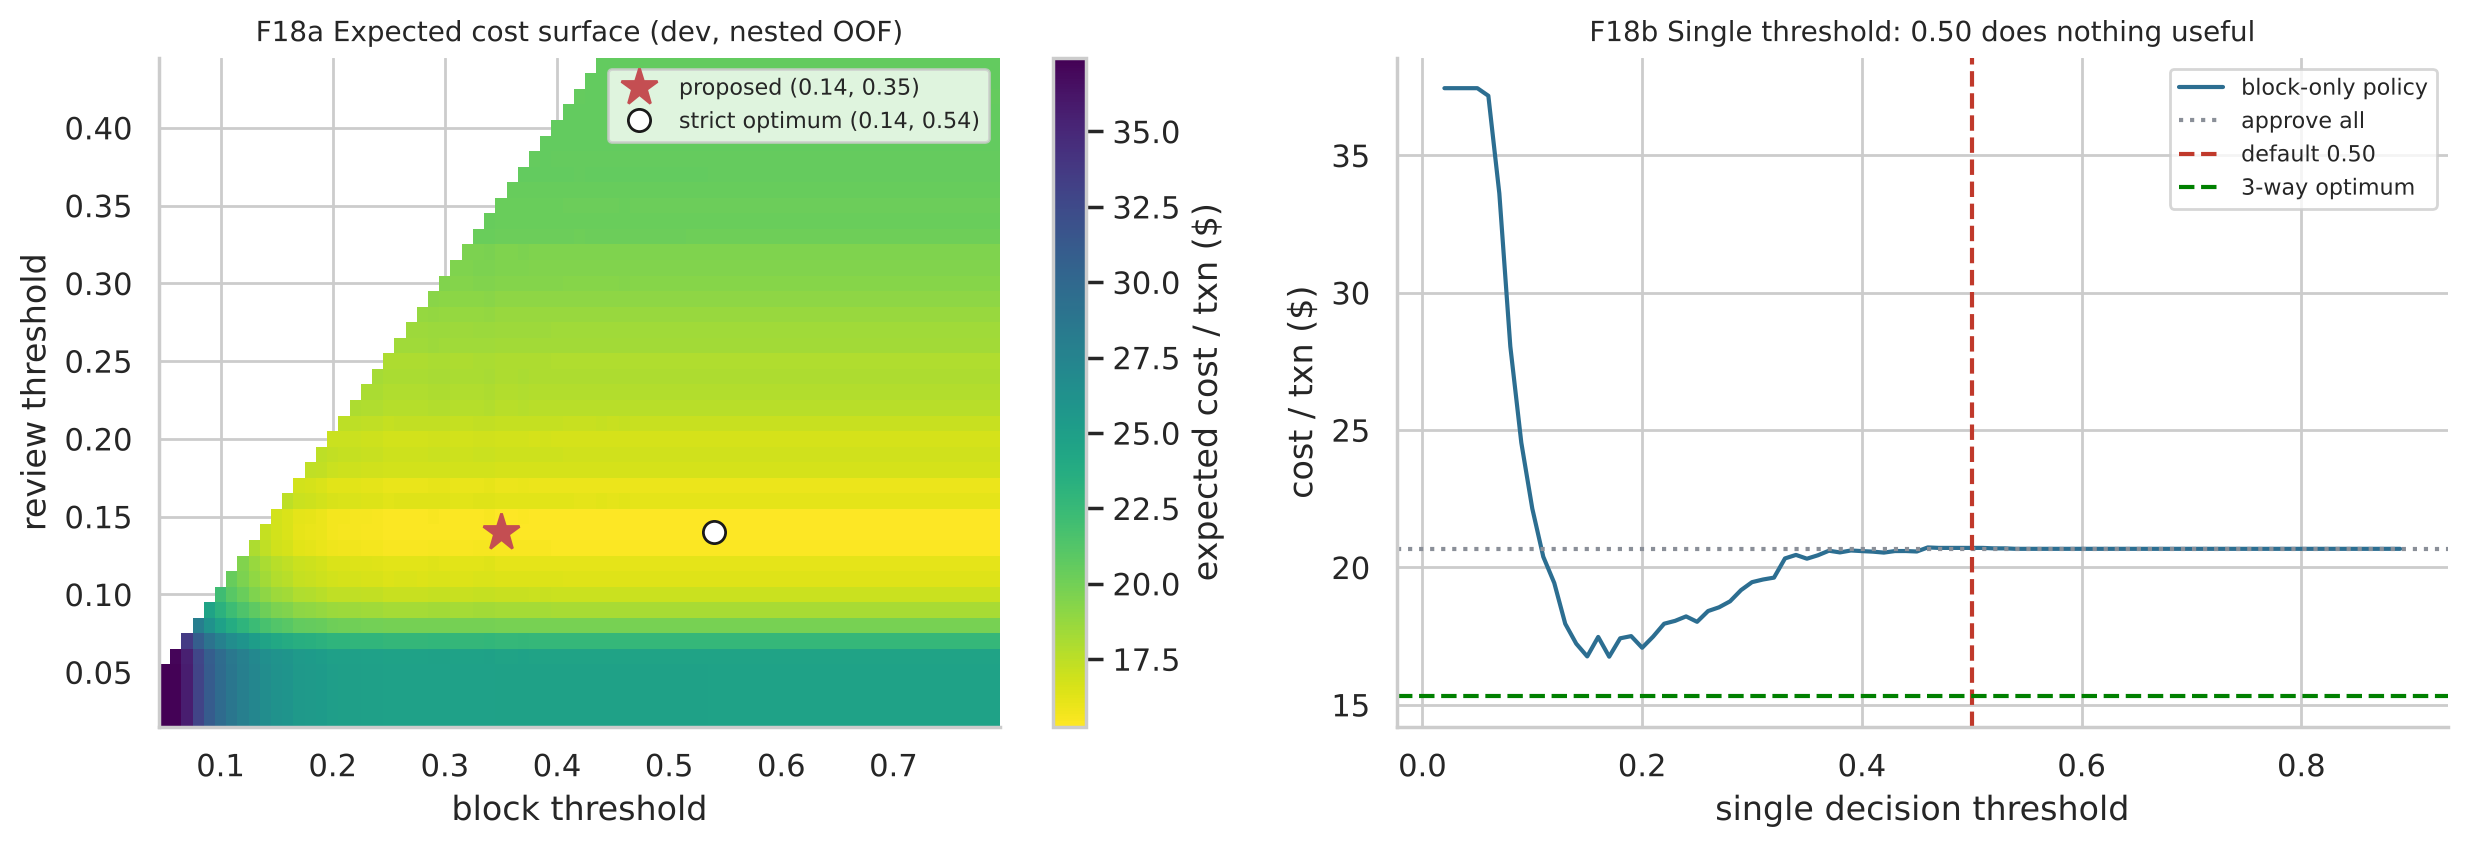

In [29]:
# F18 expected cost surface over the two thresholds + F19 single-threshold curve
grid_r = np.round(np.arange(0.02, 0.45, 0.01), 2); grid_b = np.round(np.arange(0.05, 0.80, 0.01), 2)
Z = np.full((len(grid_r), len(grid_b)), np.nan)
for i, a in enumerate(grid_r):
    for j, b in enumerate(grid_b):
        if b >= a: Z[i, j] = policy_total_cost(y_dev, amt_dev, P_OOF, a, b, BASE) / n
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
im = ax[0].pcolormesh(grid_b, grid_r, Z, cmap="viridis_r", shading="auto"); plt.colorbar(im, ax=ax[0], label="expected cost / txn ($)")
ax[0].plot(t_blk, t_rev, "r*", ms=14, label=f"proposed ({t_rev:.2f}, {t_blk:.2f})"); ax[0].plot(min(t_blk_s, grid_b.max()), t_rev_s, "wo", mec="k", ms=8, label=f"strict optimum ({t_rev_s:.2f}, {t_blk_s:.2f})"); ax[0].set_xlabel("block threshold"); ax[0].set_ylabel("review threshold"); ax[0].legend(fontsize=8); ax[0].set_title("F18a Expected cost surface (dev, nested OOF)", fontsize=10)
ths = np.round(np.arange(0.02, 0.9, 0.01), 2)
ax[1].plot(ths, [single_threshold_cost(y_dev, amt_dev, P_OOF, t, BASE) / n for t in ths], color=C_OK, label="block-only policy")
ax[1].axhline(approve_all["base"], color=C_GREY, ls=":", label="approve all"); ax[1].axvline(0.5, color=C_FRAUD, ls="--", label="default 0.50"); ax[1].axhline(tot_best / n, color="green", ls="--", label="3-way optimum")
ax[1].set_xlabel("single decision threshold"); ax[1].set_ylabel("cost / txn ($)"); ax[1].legend(fontsize=8); ax[1].set_title("F18b Single threshold: 0.50 does nothing useful", fontsize=10); savefig("F18_cost_surface")

### E5. Sensitivity analysis: (a) one-at-a-time cost scenarios, (b) review-cost x false-positive-cost grid, (c) cost of *using the wrong thresholds*

,scenario,t_review_opt,t_block_opt,review_share,block_share,cost_opt,cost_with_base_thresholds,regret_of_base_thresholds,cost_default_050,cost_approve_all
0,base,0.14,0.54,0.253,0.000,15.261,15.312,0.051,20.710,20.677
1,cheap_review ($8),0.08,0.54,0.728,0.000,10.413,12.238,1.825,20.710,20.677
2,costly_review ($35),0.17,0.17,0.000,0.160,16.751,19.296,2.546,20.710,20.677
3,low_FP_cost ($20),0.13,0.13,0.000,0.302,12.630,15.105,2.475,20.694,20.677
4,high_FP_cost ($120),0.14,0.54,0.253,0.000,15.261,16.116,0.855,20.778,20.677
5,high_fraud_loss (fee $60),0.13,0.42,0.298,0.004,18.359,18.524,0.164,26.167,26.133
6,weak_analysts (recall 60%),0.17,0.17,0.000,0.160,16.751,18.772,2.022,20.710,20.677


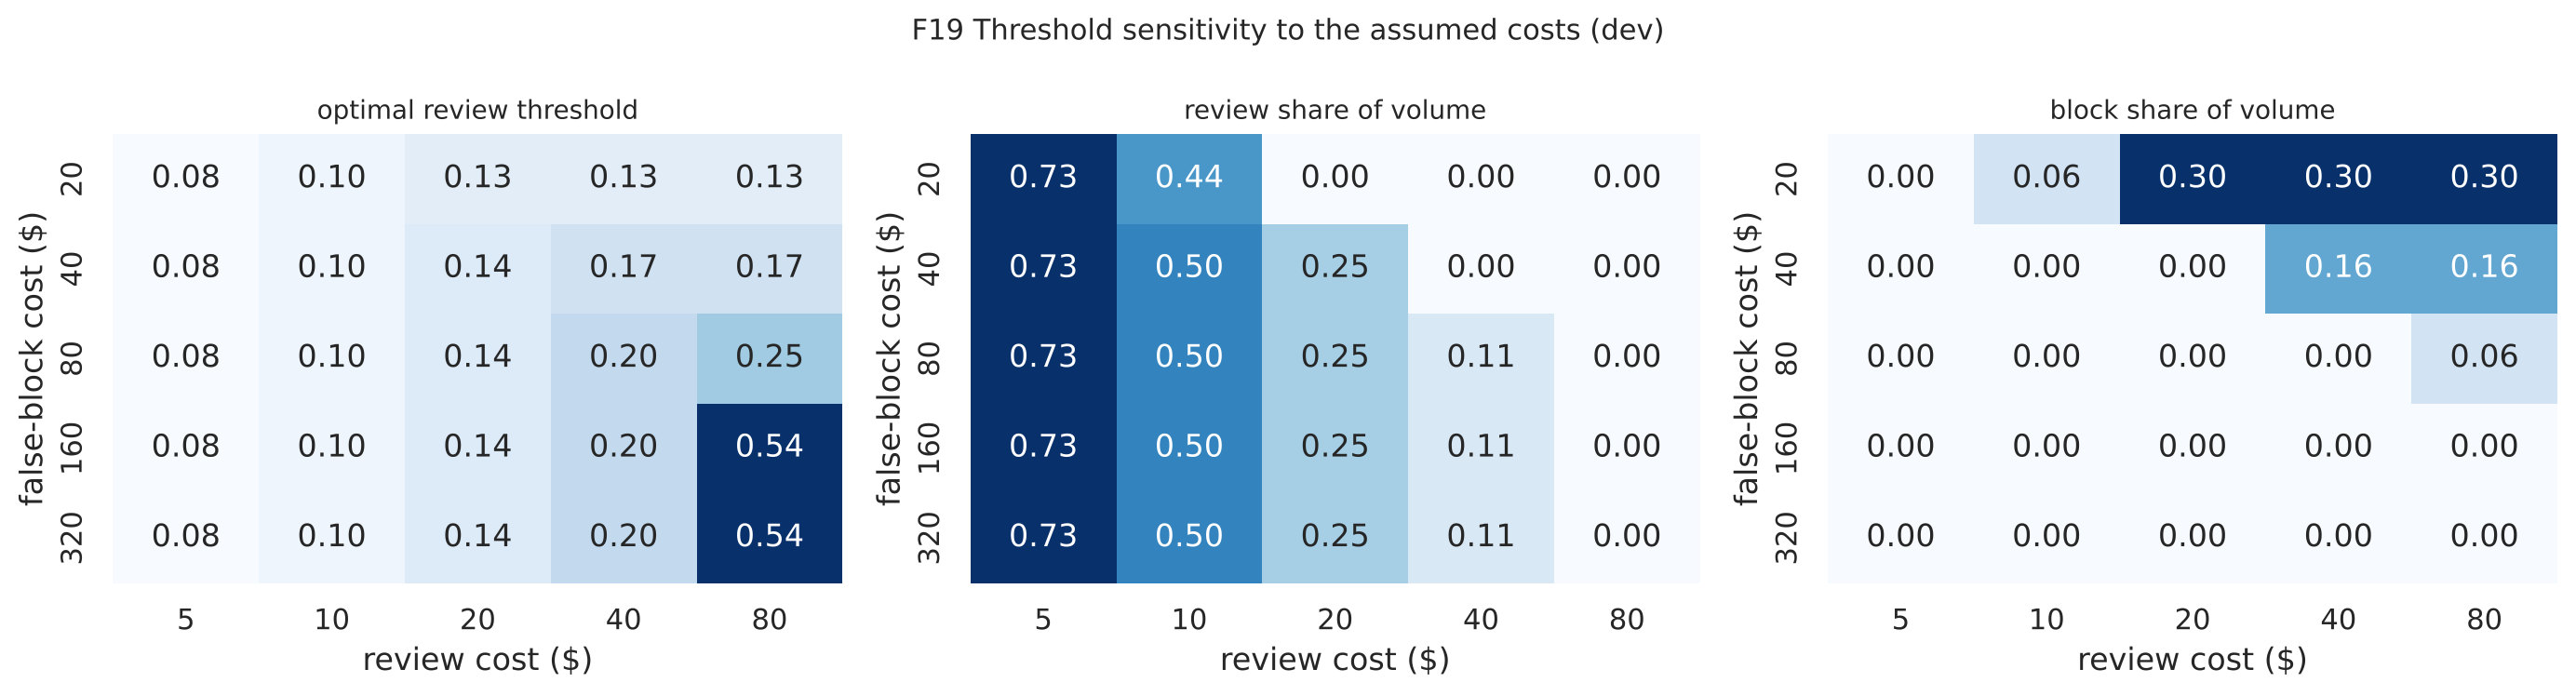

In [30]:
sens_rows = []
for s, cp in SCEN.items():
    tr, tb, tot = optimise_thresholds(y_dev, amt_dev, P_OOF, cp)
    c_base_thr = policy_total_cost(y_dev, amt_dev, P_OOF, t_rev, t_blk, cp)
    c_def = policy_costs(y_dev, amt_dev, np.where(P_OOF >= .5, 2, 0), cp).sum()
    sens_rows.append(dict(scenario=s, t_review_opt=tr, t_block_opt=tb, review_share=((P_OOF >= tr) & (P_OOF < tb)).mean(), block_share=(P_OOF >= tb).mean(),
                          cost_opt=tot / n, cost_with_base_thresholds=c_base_thr / n, regret_of_base_thresholds=(c_base_thr - tot) / n, cost_default_050=c_def / n, cost_approve_all=approve_all[s]))
sens = pd.DataFrame(sens_rows).round(3); display(sens); R["sensitivity"] = sens.to_dict("records")

fp_list, rv_list = [20, 40, 80, 160, 320], [5, 10, 20, 40, 80]
Gt, Gs, Gc = np.zeros((5, 5)), np.zeros((5, 5)), np.zeros((5, 5)); grid_rows = []
for i, fpv in enumerate(fp_list):
    for j, rv in enumerate(rv_list):
        cp = CostParams(fp_block_fixed=fpv, review_cost=rv); tr, tb, tot = optimise_thresholds(y_dev, amt_dev, P_OOF, cp)
        Gt[i, j] = tr; Gs[i, j] = ((P_OOF >= tr) & (P_OOF < tb)).mean(); Gc[i, j] = (P_OOF >= tb).mean()
        grid_rows.append(dict(fp_block_fixed=fpv, review_cost=rv, t_review=tr, t_block=tb, review_share=Gs[i, j], block_share=Gc[i, j], cost_per_txn=tot / n))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, M, ttl in zip(ax, [Gt, Gs, Gc], ["optimal review threshold", "review share of volume", "block share of volume"]):
    sns.heatmap(pd.DataFrame(M, index=fp_list, columns=rv_list), annot=True, fmt=".2f", cmap="Blues", ax=a, cbar=False); a.set_xlabel("review cost ($)"); a.set_ylabel("false-block cost ($)"); a.set_title(ttl, fontsize=10)
fig.suptitle("F19 Threshold sensitivity to the assumed costs (dev)", fontsize=11); savefig("F19_threshold_sensitivity")
R["thr_grid_range"] = dict(t_review_min=float(Gt.min()), t_review_max=float(Gt.max()), review_share_min=float(Gs.min()), review_share_max=float(Gs.max()))
fpfn = pd.DataFrame(grid_rows)

### E6. Review workload as recall is increased

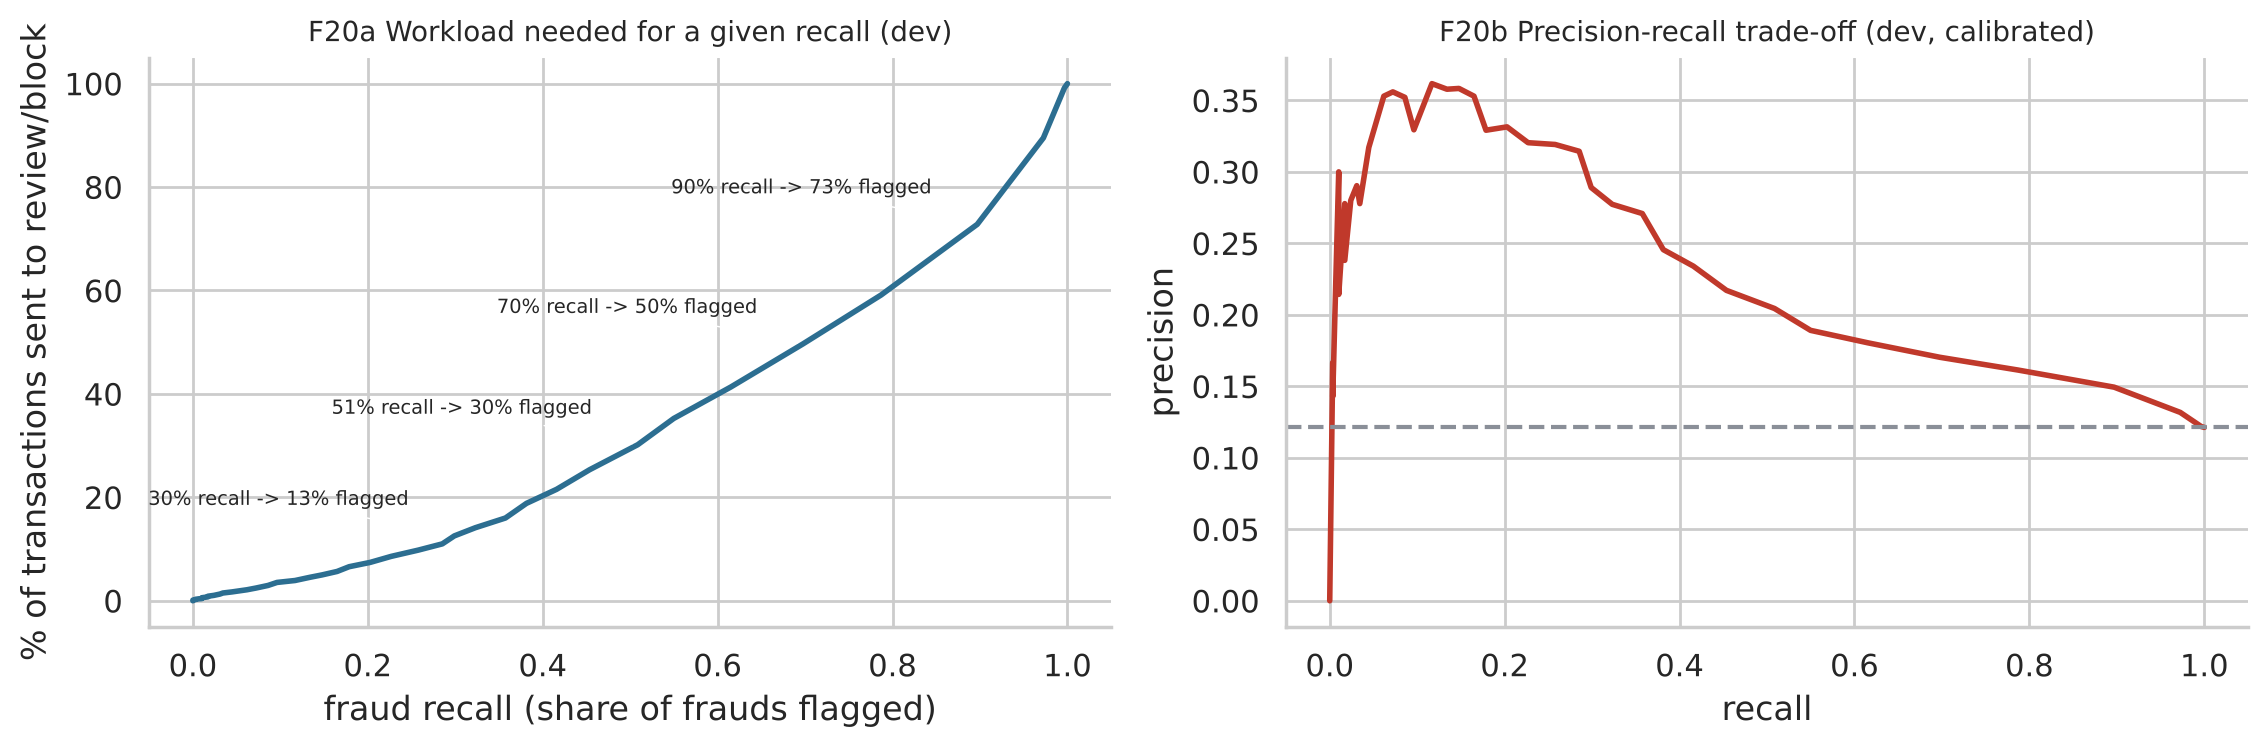

           threshold  recall  flagged_share  precision
recall_30       0.19   0.299          0.125      0.289
recall_50       0.13   0.509          0.302      0.204
recall_70       0.10   0.698          0.497      0.170
recall_90       0.08   0.897          0.728      0.149


In [31]:
wk = []
for t in np.round(np.arange(0.02, 0.60, 0.01), 2):
    fl = P_OOF >= t
    wk.append(dict(threshold=t, flagged_share=fl.mean(), recall=(fl & (y_dev == 1)).sum() / y_dev.sum(), precision=(fl & (y_dev == 1)).sum() / max(1, fl.sum()),
                   f1=f1_score(y_dev, fl) if fl.sum() else 0.0, cost_block_only=single_threshold_cost(y_dev, amt_dev, P_OOF, t, BASE) / n))
wk = pd.DataFrame(wk)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].plot(wk.recall, wk.flagged_share * 100, color=C_OK, lw=2); ax[0].set_xlabel("fraud recall (share of frauds flagged)"); ax[0].set_ylabel("% of transactions sent to review/block"); ax[0].set_title("F20a Workload needed for a given recall (dev)", fontsize=10)
for rc in [0.3, 0.5, 0.7, 0.9]:
    r_ = wk.iloc[(wk.recall - rc).abs().argmin()]; ax[0].annotate(f"{r_.recall:.0%} recall -> {r_.flagged_share:.0%} flagged", (r_.recall, r_.flagged_share * 100), fontsize=7, xytext=(r_.recall - .35, r_.flagged_share * 100 + 6), arrowprops=dict(arrowstyle="-", lw=.5))
ax[1].plot(wk.recall, wk.precision, color=C_FRAUD, lw=2); ax[1].axhline(y_dev.mean(), color=C_GREY, ls="--"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("F20b Precision-recall trade-off (dev, calibrated)", fontsize=10); savefig("F20_workload_recall")
wk_marks = {f"recall_{int(r*100)}": wk.iloc[(wk.recall - r).abs().argmin()][["threshold", "recall", "flagged_share", "precision"]].round(3).to_dict() for r in [0.3, 0.5, 0.7, 0.9]}
R["workload_marks"] = wk_marks; print(pd.DataFrame(wk_marks).T)

## Final hold-out evaluation (test set, used for the first time)
The calibrated production candidate and the thresholds are **frozen**. We fit on the development set and score the 600 locked test transactions once.

,model,pr_auc,pr_auc_ci,roc_auc,roc_auc_ci,brier,ece,mean_pred,recall_at_10pct
0,ExtraTrees calibrated (platt),0.1885,"[0.146, 0.260]",0.6703,"[0.614, 0.729]",0.1057,0.0326,0.1208,0.1781
1,ExtraTrees uncalibrated,0.2006,"[0.154, 0.279]",0.6803,"[0.624, 0.737]",0.1036,0.0303,0.1215,0.1781
2,LogReg baseline (untuned),0.2262,"[0.166, 0.321]",0.6838,"[0.624, 0.745]",0.1059,0.0520,0.1143,0.1781


,operating_point,flagged,precision,recall,f1
0,default 0.50,0,0.000,0.000,0.000
1,review+block (p >= 0.14),149,0.215,0.438,0.288
2,block only (p >= 0.35),12,0.000,0.000,0.000
3,dev best-F1 threshold (p >= 0.17),90,0.211,0.260,0.233


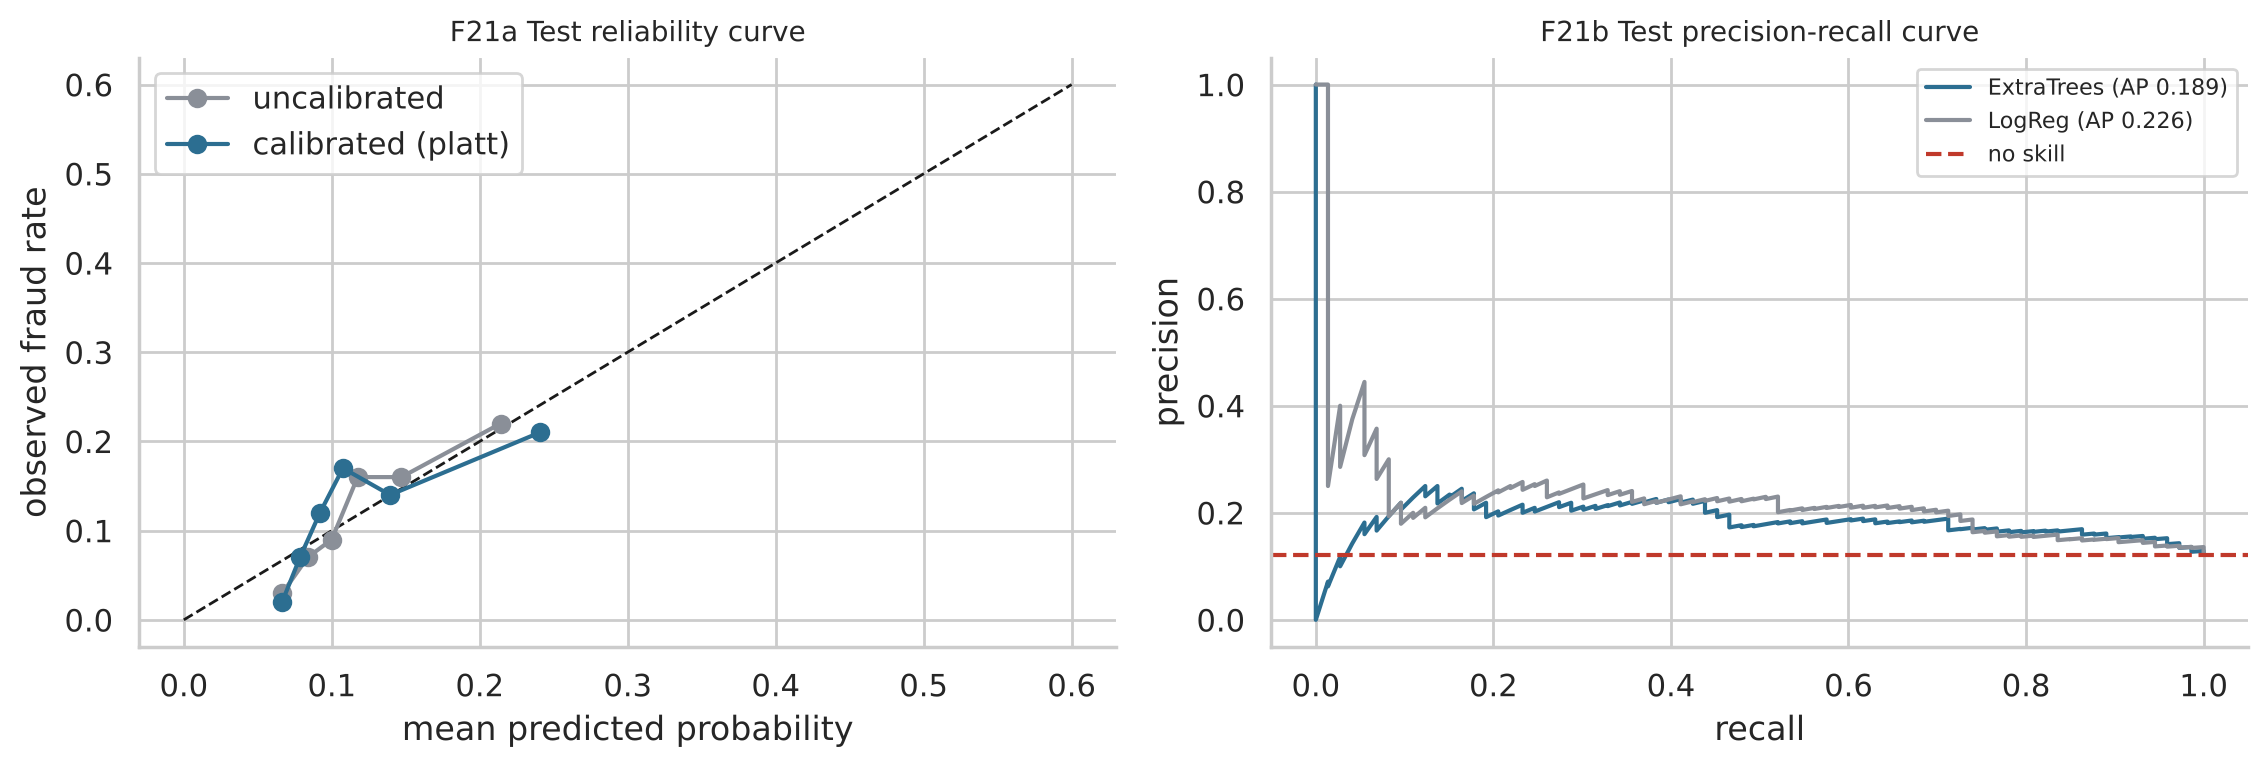

In [32]:
cal_model = clone(cal_unfitted).fit(X_dev, y_dev)                       # production candidate (calibrated)
base_fit = clone(best_est[FINAL]).fit(X_dev, y_dev)                      # uncalibrated pipeline (for SHAP and artefact 03)
p_test = cal_model.predict_proba(X_test)[:, 1]; p_test_raw = base_fit.predict_proba(X_test)[:, 1]
lr_base = make_pipeline(LogisticRegression(max_iter=5000, random_state=SEED), True, True).fit(X_dev, y_dev); p_test_lr = lr_base.predict_proba(X_test)[:, 1]

def boot_ci(fn, y, p, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); y = np.asarray(y); vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0: continue
        vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

te_rows = []
for name, p in [(f"{FINAL} calibrated ({CAL_METHOD})", p_test), (f"{FINAL} uncalibrated", p_test_raw), ("LogReg baseline (untuned)", p_test_lr)]:
    ci_pr = boot_ci(average_precision_score, y_test, p); ci_roc = boot_ci(roc_auc_score, y_test, p)
    te_rows.append(dict(model=name, pr_auc=average_precision_score(y_test, p), pr_auc_ci=f"[{ci_pr[0]:.3f}, {ci_pr[1]:.3f}]", roc_auc=roc_auc_score(y_test, p), roc_auc_ci=f"[{ci_roc[0]:.3f}, {ci_roc[1]:.3f}]",
                        brier=brier_score_loss(y_test, p), ece=expected_calibration_error(y_test, p), mean_pred=p.mean(), recall_at_10pct=recall_at_top(y_test, p)))
te = pd.DataFrame(te_rows).round(4); display(te)
R["test_metrics"] = te.to_dict("records"); R["test_prevalence"] = float(y_test.mean()); R["test_brier_prevalence"] = float(brier_score_loss(y_test, np.full(len(y_test), y_dev.mean())))
# precision / recall / F1 at default 0.5 and at the cost-optimal operating points
THR_F1 = float(wk.loc[wk.f1.idxmax(), 'threshold']); R['thr_f1_dev'] = THR_F1
ops = []
for nm, fl in [("default 0.50", p_test >= 0.5), (f"review+block (p >= {t_rev:.2f})", p_test >= t_rev), (f"block only (p >= {t_blk:.2f})", p_test >= t_blk), (f"dev best-F1 threshold (p >= {THR_F1:.2f})", p_test >= THR_F1)]:
    ops.append(dict(operating_point=nm, flagged=int(fl.sum()), precision=precision_score(y_test, fl, zero_division=0), recall=recall_score(y_test, fl), f1=f1_score(y_test, fl, zero_division=0)))
ops = pd.DataFrame(ops).round(3); display(ops); R["test_ops"] = ops.to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].plot([0, .6], [0, .6], "k--", lw=1)
for lab, p, col in [("uncalibrated", p_test_raw, C_GREY), (f"calibrated ({CAL_METHOD})", p_test, C_OK)]:
    fr, mp = calibration_curve(y_test, p, n_bins=6, strategy="quantile"); ax[0].plot(mp, fr, marker="o", color=col, label=lab)
ax[0].set_xlabel("mean predicted probability"); ax[0].set_ylabel("observed fraud rate"); ax[0].legend(); ax[0].set_title("F21a Test reliability curve", fontsize=10)
pr, rc, _ = precision_recall_curve(y_test, p_test); pr2, rc2, _ = precision_recall_curve(y_test, p_test_lr)
ax[1].plot(rc, pr, color=C_OK, label=f"{FINAL} (AP {average_precision_score(y_test, p_test):.3f})"); ax[1].plot(rc2, pr2, color=C_GREY, label=f"LogReg (AP {average_precision_score(y_test, p_test_lr):.3f})"); ax[1].axhline(y_test.mean(), color=C_FRAUD, ls="--", label="no skill")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend(fontsize=8); ax[1].set_title("F21b Test precision-recall curve", fontsize=10); savefig("F21_test_calibration_pr")

## I. Fraud operations simulation (test set, scaled to 100,000 transactions / month)
Policies compared: **(1)** approve everything, **(2)** default 0.50 threshold, **(3)** a hand-written business rule (review if new device, prior chargeback, or IP / merchant risk in the dev top 20 %), **(4)** single cost-optimal threshold with no review band, **(5)** the proposed **3-way cost-optimal** policy, **(6)** the same but **capacity-constrained** (review <= 4 % of volume, thresholds from dev), **(7)** the amount-aware Bayes policy that picks the cheapest action per transaction from the calibrated probability.

policy,1 Approve all,2 Default 0.50 threshold,3 Business rule (review only),4 Single threshold (block >= 0.17),5 PROPOSED 3-way (review 0.14 / block 0.35),"6 3-way, review capacity <= 4% (0.17/0.19)",7 Amount-aware Bayes (per-txn cheapest action),"8 Strict cost optimum, no real block band (0.14/0.54)"
approve_share,1.000,1.000,0.447,0.850,0.752,0.850,0.827,0.752
review_share,0.000,0.000,0.553,0.000,0.228,0.028,0.150,0.248
block_share,0.000,0.000,0.000,0.150,0.020,0.122,0.023,0.000
fraud_recall_flagged,0.000,0.000,0.685,0.260,0.438,0.260,0.247,0.438
fraud_stopped_effective,0.000,0.000,0.616,0.260,0.395,0.253,0.225,0.395
precision_flagged,0.000,0.000,0.151,0.211,0.215,0.211,0.173,0.215
precision_blocked,0.000,0.000,0.000,0.211,0.000,0.192,0.143,0.000
legit_blocked_share_of_legit,0.000,0.000,0.000,0.135,0.023,0.112,0.023,0.000
legit_reviewed_share_of_legit,0.000,0.000,0.535,0.000,0.199,0.023,0.140,0.222
cost_per_txn,22.298,22.298,22.922,17.729,15.445,17.787,13.818,15.057


policy,1 Approve all,2 Default 0.50 threshold,3 Business rule (review only),4 Single threshold (block >= 0.17),5 PROPOSED 3-way (review 0.14 / block 0.35),"6 3-way, review capacity <= 4% (0.17/0.19)",7 Amount-aware Bayes (per-txn cheapest action),"8 Strict cost optimum, no real block band (0.14/0.54)"
approve_share,1.000,0.999,0.468,0.840,0.747,0.840,0.823,0.747
review_share,0.000,0.000,0.532,0.000,0.240,0.035,0.159,0.253
block_share,0.000,0.001,0.000,0.160,0.013,0.125,0.018,0.000
fraud_recall_flagged,0.000,0.000,0.698,0.357,0.454,0.357,0.302,0.454
fraud_stopped_effective,0.000,0.000,0.628,0.357,0.411,0.352,0.276,0.408
precision_flagged,0.000,0.000,0.159,0.271,0.217,0.271,0.207,0.217
precision_blocked,0.000,0.000,0.000,0.271,0.290,0.289,0.227,0.000
legit_blocked_share_of_legit,0.000,0.001,0.000,0.133,0.010,0.101,0.016,0.000
legit_reviewed_share_of_legit,0.000,0.000,0.509,0.000,0.215,0.031,0.144,0.226
cost_per_txn,20.677,20.710,21.159,16.751,15.312,16.517,13.593,15.261


,policy,vs,saving_per_100k,ci_low,ci_high,p_saving_positive
0,2 Default 0.50 threshold,1 Approve all,0.0,0.0,0.0,0.0
1,2 Default 0.50 threshold,3 Business rule (review only),62430.0,-505635.0,525791.0,1.0
2,3 Business rule (review only),1 Approve all,-62430.0,-525791.0,505635.0,0.0
3,4 Single threshold (block >= 0.17),1 Approve all,456921.0,-163213.0,1207408.0,1.0
4,4 Single threshold (block >= 0.17),3 Business rule (review only),519350.0,48245.0,1090523.0,1.0
5,5 PROPOSED 3-way (review 0.14 / block 0.35),1 Approve all,685246.0,102563.0,1400818.0,1.0
6,5 PROPOSED 3-way (review 0.14 / block 0.35),3 Business rule (review only),747675.0,321500.0,1283377.0,1.0
7,"6 3-way, review capacity <= 4% (0.17/0.19)",1 Approve all,451107.0,-144395.0,1176650.0,1.0
8,"6 3-way, review capacity <= 4% (0.17/0.19)",3 Business rule (review only),513537.0,61310.0,1039750.0,1.0
9,7 Amount-aware Bayes (per-txn cheapest action),1 Approve all,847977.0,203905.0,1636728.0,1.0


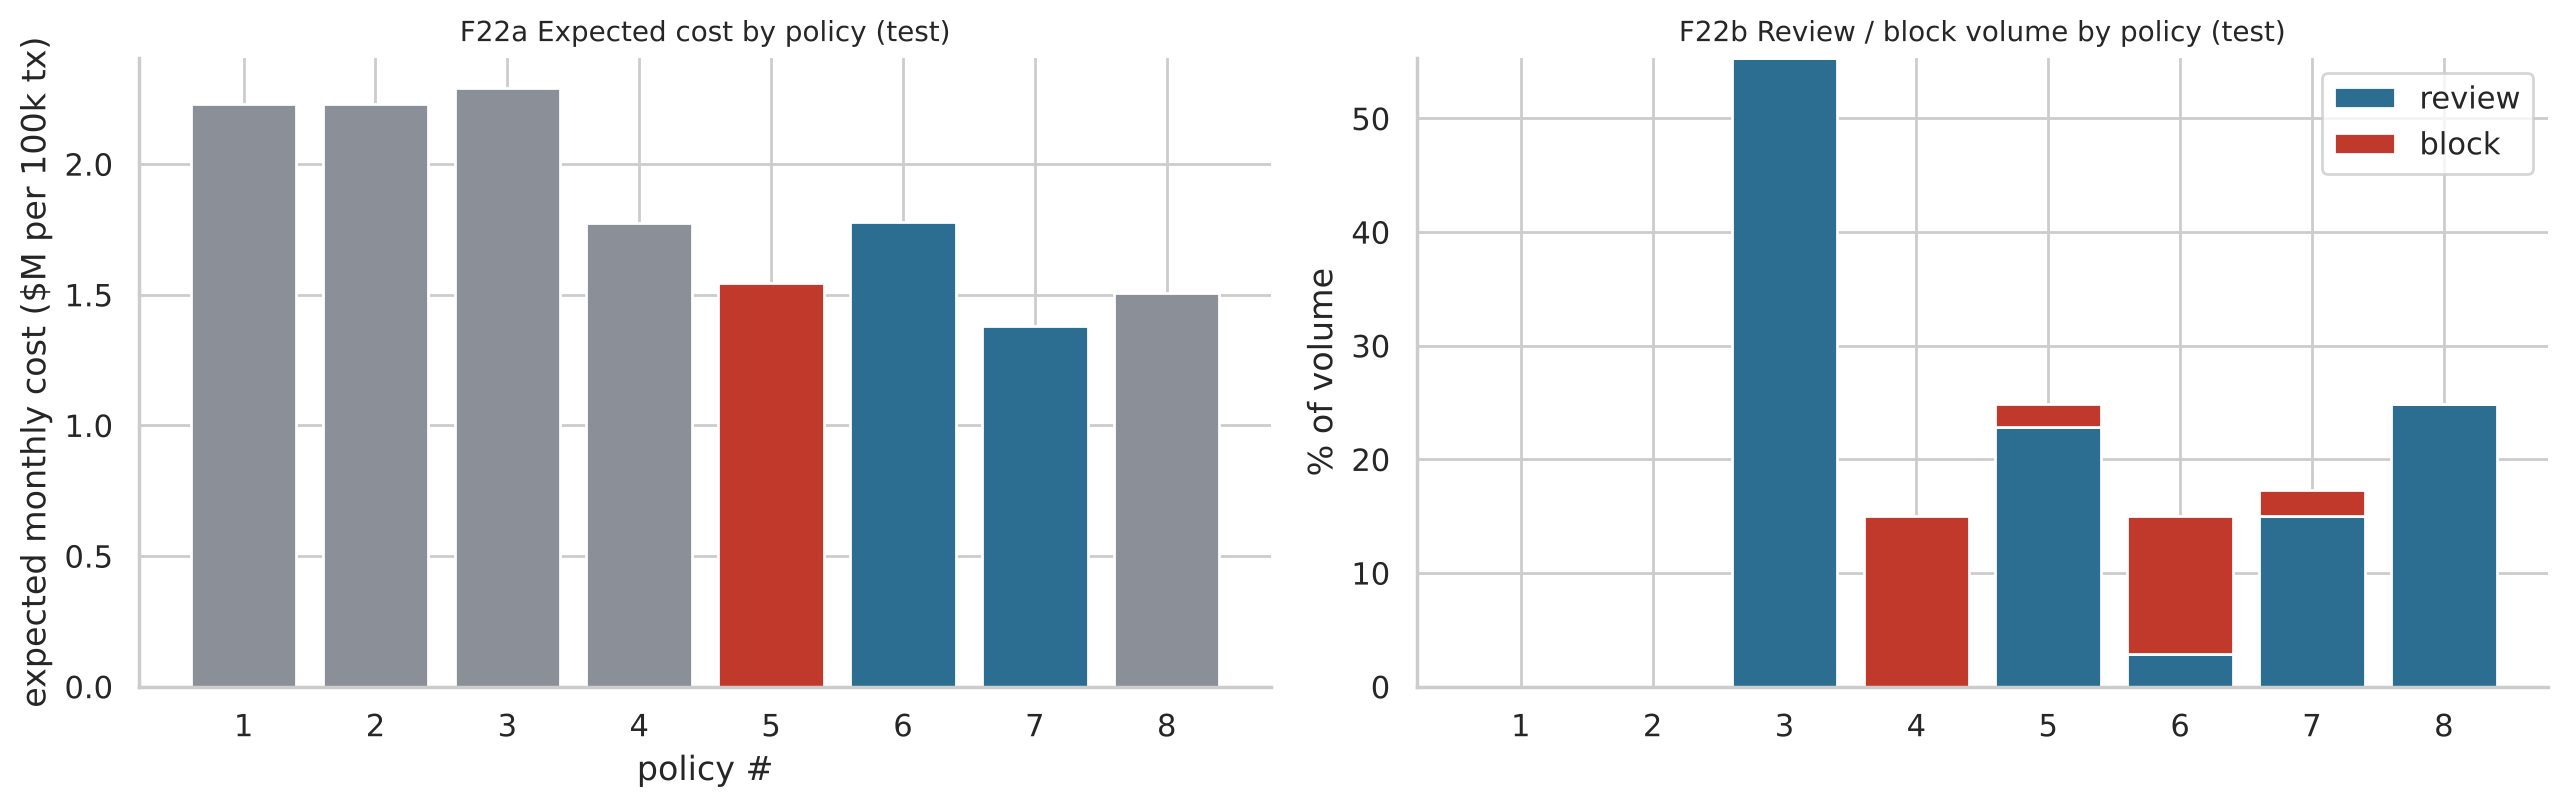

In [33]:
ip80, mr80 = X_dev.ip_risk_score.quantile(.8), X_dev.merchant_risk_score.quantile(.8)
def rule_decision(X): return np.where((X.new_device == 1) | (X.prior_chargebacks >= 1) | (X.ip_risk_score >= ip80) | (X.merchant_risk_score >= mr80), 1, 0)
tr_cap, tb_cap, _ = optimise_thresholds(y_dev, amt_dev, P_OOF, BASE, max_review_share=0.04, min_review_share=0.01, min_block_share=0.01)
R["rule_review_share_dev"] = float(rule_decision(X_dev).mean()); R["cap_thr"] = dict(review=tr_cap, block=tb_cap)
policies_test = {
    "1 Approve all": np.zeros(len(y_test), int),
    "2 Default 0.50 threshold": np.where(p_test >= .5, 2, 0),
    "3 Business rule (review only)": rule_decision(X_test),
    f"4 Single threshold (block >= {bt:.2f})": np.where(p_test >= bt, 2, 0),
    f"5 PROPOSED 3-way (review {t_rev:.2f} / block {t_blk:.2f})": decide(p_test, t_rev, t_blk),
    f"6 3-way, review capacity <= 4% ({tr_cap:.2f}/{tb_cap:.2f})": decide(p_test, tr_cap, tb_cap),
    "7 Amount-aware Bayes (per-txn cheapest action)": bayes_decision(p_test, amt_test, BASE),
    f"8 Strict cost optimum, no real block band ({t_rev_s:.2f}/{t_blk_s:.2f})": decide(p_test, t_rev_s, t_blk_s),
}
ops_sim = pd.DataFrame([pol_report(y_test, amt_test, d, BASE, nm) for nm, d in policies_test.items()]); display(ops_sim.round(3).set_index("policy").T)
R["ops_sim"] = ops_sim.to_dict("records")
# the same policies on the DEV nested-OOF probabilities (thresholds were tuned there, so tuned policies are optimistic; Bayes has no tuned parameter)
policies_dev = {k: v for k, v in zip(policies_test, [np.zeros(n, int), np.where(P_OOF >= .5, 2, 0), rule_decision(X_dev), np.where(P_OOF >= bt, 2, 0), decide(P_OOF, t_rev, t_blk),
                                                      decide(P_OOF, tr_cap, tb_cap), bayes_decision(P_OOF, amt_dev, BASE), decide(P_OOF, t_rev_s, t_blk_s)])}
ops_dev = pd.DataFrame([pol_report(y_dev, amt_dev, d, BASE, nm) for nm, d in policies_dev.items()]); display(ops_dev.round(3).set_index("policy").T); R["ops_sim_dev"] = ops_dev.to_dict("records")
# paired bootstrap of savings vs approve-all and vs the rule policy
cst = {nm: policy_costs(y_test, amt_test, d, BASE) for nm, d in policies_test.items()}; keys = list(cst)
rng = np.random.default_rng(SEED); bi = rng.integers(0, len(y_test), (2000, len(y_test))); sv_rows = []
for nm in keys[1:]:
    for ref in [keys[0], keys[2]]:
        if nm == ref: continue
        d = (cst[ref] - cst[nm]); b = d[bi].mean(axis=1) * 100_000
        sv_rows.append(dict(policy=nm, vs=ref, saving_per_100k=d.mean() * 100_000, ci_low=np.percentile(b, 2.5), ci_high=np.percentile(b, 97.5), p_saving_positive=(b > 0).mean()))
sav = pd.DataFrame(sv_rows).round(0); display(sav); R["savings_boot"] = sav.to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
nm_short = [k.split(" ")[0] for k in keys]; ax[0].bar(nm_short, ops_sim.monthly_cost_100k / 1e6, color=[C_GREY, C_GREY, C_GREY, C_GREY, C_FRAUD, C_OK, C_OK, C_GREY]); ax[0].set_ylabel("expected monthly cost ($M per 100k tx)"); ax[0].set_xlabel("policy #"); ax[0].set_title("F22a Expected cost by policy (test)", fontsize=10)
wd = ops_sim[["review_share", "block_share"]].values * 100; ax[1].bar(nm_short, wd[:, 0], color=C_OK, label="review"); ax[1].bar(nm_short, wd[:, 1], bottom=wd[:, 0], color=C_FRAUD, label="block"); ax[1].set_ylabel("% of volume"); ax[1].legend(); ax[1].set_title("F22b Review / block volume by policy (test)", fontsize=10); savefig("F22_policy_comparison")

### I-extra. Could a model with slightly *lower* ranking performance be operationally preferable? (quantitative test)
The LogReg baseline has the higher CV ROC-AUC / PR-AUC, yet the selected model has the lower expected business cost on dev. We check this on the locked test set by giving LogReg exactly the same treatment: Platt calibration, thresholds optimised on dev OOF, frozen, then evaluated on test.

In [34]:
lr_cal = CalibratedClassifierCV(clone(best_est["LogReg"]), method="sigmoid", cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 2)).fit(X_dev, y_dev)
p_lr_test = lr_cal.predict_proba(X_test)[:, 1]
tr_l, tb_l, _ = optimise_thresholds(y_dev, amt_dev, P_PL["LogReg"], BASE, min_review_share=0.01, min_block_share=0.01)
lr_rep = pol_report(y_test, amt_test, decide(p_lr_test, tr_l, tb_l), BASE, f"9 LogReg 3-way ({tr_l:.2f}/{tb_l:.2f})")
cmp8 = pd.DataFrame([ops_sim[ops_sim.policy.str.startswith("5")].iloc[0].to_dict(), lr_rep]).round(3).set_index("policy")
display(cmp8[["review_share", "block_share", "fraud_stopped_effective", "cost_per_txn", "monthly_cost_100k"]])
d_ = policy_costs(y_test, amt_test, decide(p_lr_test, tr_l, tb_l), BASE) - cst[[k for k in keys if k.startswith("5")][0]]
bb = d_[bi].mean(axis=1) * 100_000
R["lr_vs_final_test"] = dict(lr_cost_per_txn=lr_rep["cost_per_txn"], final_cost_per_txn=float(cmp8.iloc[0]["cost_per_txn"]), extra_cost_lr_per_100k=float(d_.mean() * 100_000),
                              ci_low=float(np.percentile(bb, 2.5)), ci_high=float(np.percentile(bb, 97.5)), lr_test_roc=float(roc_auc_score(y_test, p_lr_test)), final_test_roc=float(roc_auc_score(y_test, p_test)),
                              lr_thr=(tr_l, tb_l))
print(R["lr_vs_final_test"])
# the *cost-structure* answer: ranking of models flips across scenarios (dev) -> see cost_tab
flip = cost_tab.loc[MODELS].rank(axis=0).astype(int); display(flip)

,review_share,block_share,fraud_stopped_effective,cost_per_txn,monthly_cost_100k
policy,,,,,
5 PROPOSED 3-way (review 0.14 / block 0.35),0.228,0.020,0.395,15.445,1544530.867
9 LogReg 3-way (0.17/0.35),0.150,0.015,0.274,16.968,1696825.599


{'lr_cost_per_txn': np.float64(16.968255988720465), 'final_cost_per_txn': 15.445, 'extra_cost_lr_per_100k': 152294.73220537967, 'ci_low': -142319.38002819882, 'ci_high': 512546.3663720457, 'lr_test_roc': 0.6915598762704374, 'final_test_roc': 0.6702971069116996, 'lr_thr': (0.17, 0.35)}


scenario,base,cheap_review ($8),costly_review ($35),low_FP_cost ($20),high_FP_cost ($120),high_fraud_loss (fee $60),weak_analysts (recall 60%)
model,,,,,,,
LogReg,7,4,5,4,7,5,5
RandomForest,2,2,1,2,2,2,1
ExtraTrees,1,6,2,1,1,1,2
HistGradBoosting,5,7,6,7,6,6,6
LightGBM,3,3,3,5,4,4,3
XGBoost,6,5,7,6,5,7,7
Ensemble,4,1,4,3,3,3,4


## H. Explainable AI (SHAP)
SHAP (TreeExplainer) explains the **uncalibrated** tree ensemble (log-odds / probability contributions of the same model that is wrapped by the calibrator; Platt scaling is monotone, so feature rankings and directions are unchanged). Global analysis uses a 400-row sample of the development set; local explanations use test transactions. *SHAP values describe how the model's prediction depends on inputs; they are **not** causal effects.*

,mean|SHAP|
new_device_inconsistent,0.0061
red_flag_count,0.0055
auth_missing,0.0048
new_device,0.0047
prior_chargeback_flag,0.0044
authentication_level_Missing,0.0043
burst_flag,0.0038
high_amount_p90,0.0036
customer_tier_Basic,0.0030
high_amount_p95,0.0029


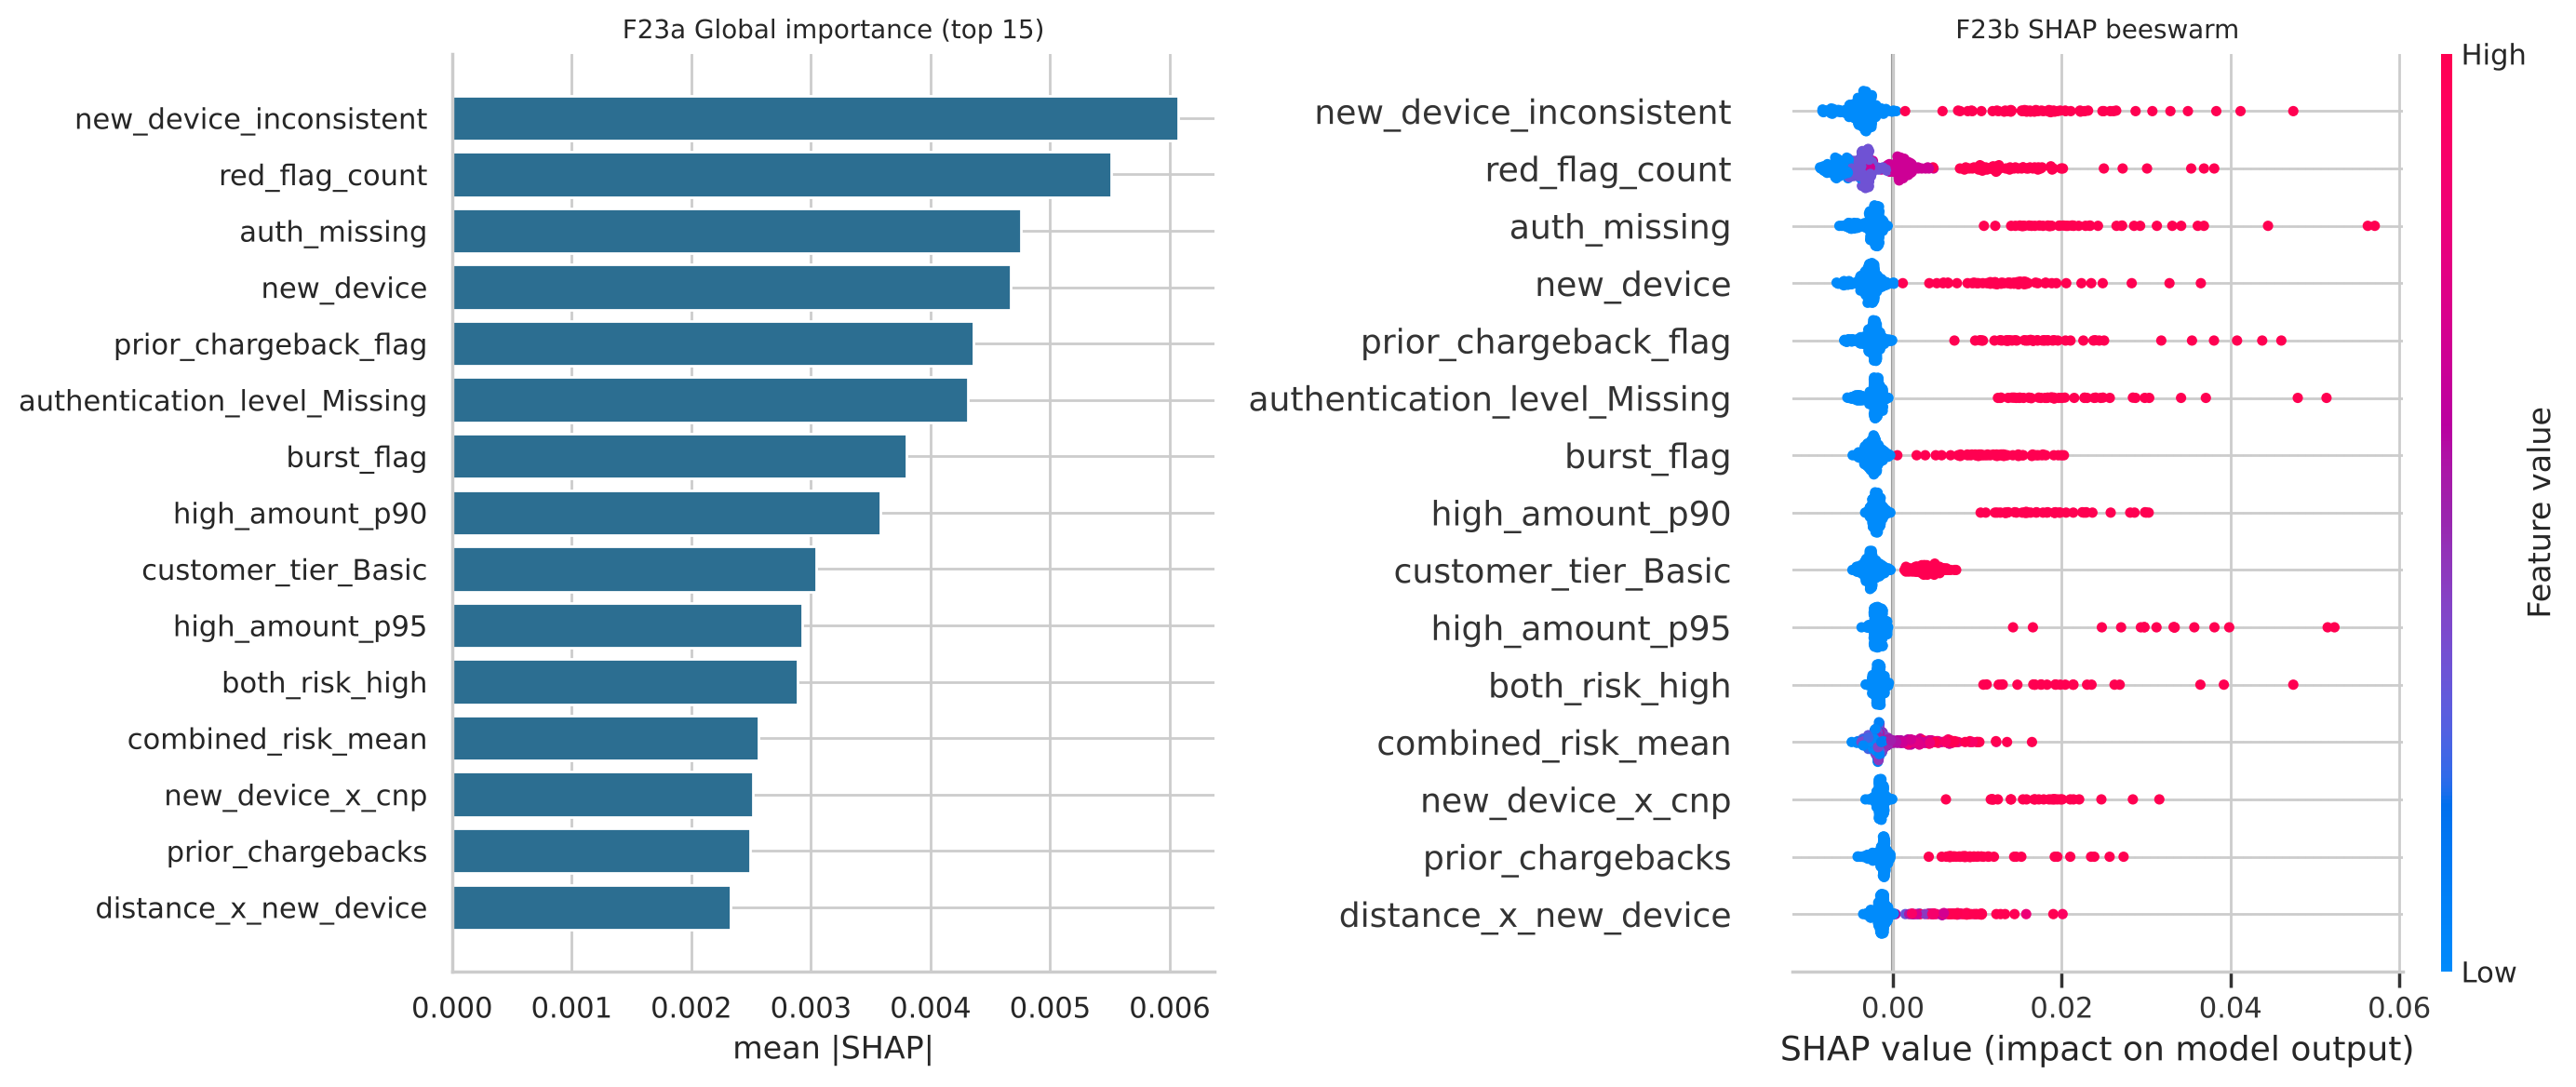

In [35]:
TREE_OK = ["RandomForest", "ExtraTrees", "LightGBM", "XGBoost"]   # models supported by shap.TreeExplainer
EXPL = FINAL if FINAL in TREE_OK else min(TREE_OK, key=lambda m: rank.loc[m, "base_cost_per_txn"])
expl_pipe = base_fit if EXPL == FINAL else clone(best_est[EXPL]).fit(X_dev, y_dev)
prep_f = expl_pipe.named_steps["prep"]; fn = feature_names(expl_pipe)
def tf(X): return pd.DataFrame(prep_f.transform(X), columns=fn, index=X.index)
tree = shap.TreeExplainer(expl_pipe.named_steps["model"])
def shap_pos(X, interactions=False):
    v = tree.shap_interaction_values(X) if interactions else tree.shap_values(X, check_additivity=False)
    if isinstance(v, list): return np.asarray(v[1])
    v = np.asarray(v); return v[..., 1] if v.shape[-1] == 2 and v.ndim == (4 if interactions else 3) else v
samp = X_dev.sample(400, random_state=SEED); Xs = tf(samp); SV = shap_pos(Xs)
imp = pd.Series(np.abs(SV).mean(0), index=fn).sort_values(ascending=False); display(imp.head(15).round(4).to_frame("mean|SHAP|"))
R["shap_top"] = imp.head(15).round(5).to_dict(); R["shap_model"] = EXPL

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
t15 = imp.head(15)[::-1]; ax[0].barh(t15.index, t15.values, color=C_OK); ax[0].set_xlabel("mean |SHAP|"); ax[0].set_title("F23a Global importance (top 15)", fontsize=10)
plt.sca(ax[1]); shap.summary_plot(SV, Xs, max_display=15, show=False, plot_size=None, color_bar=True); ax[1].set_title("F23b SHAP beeswarm", fontsize=10); savefig("F23_shap_global")

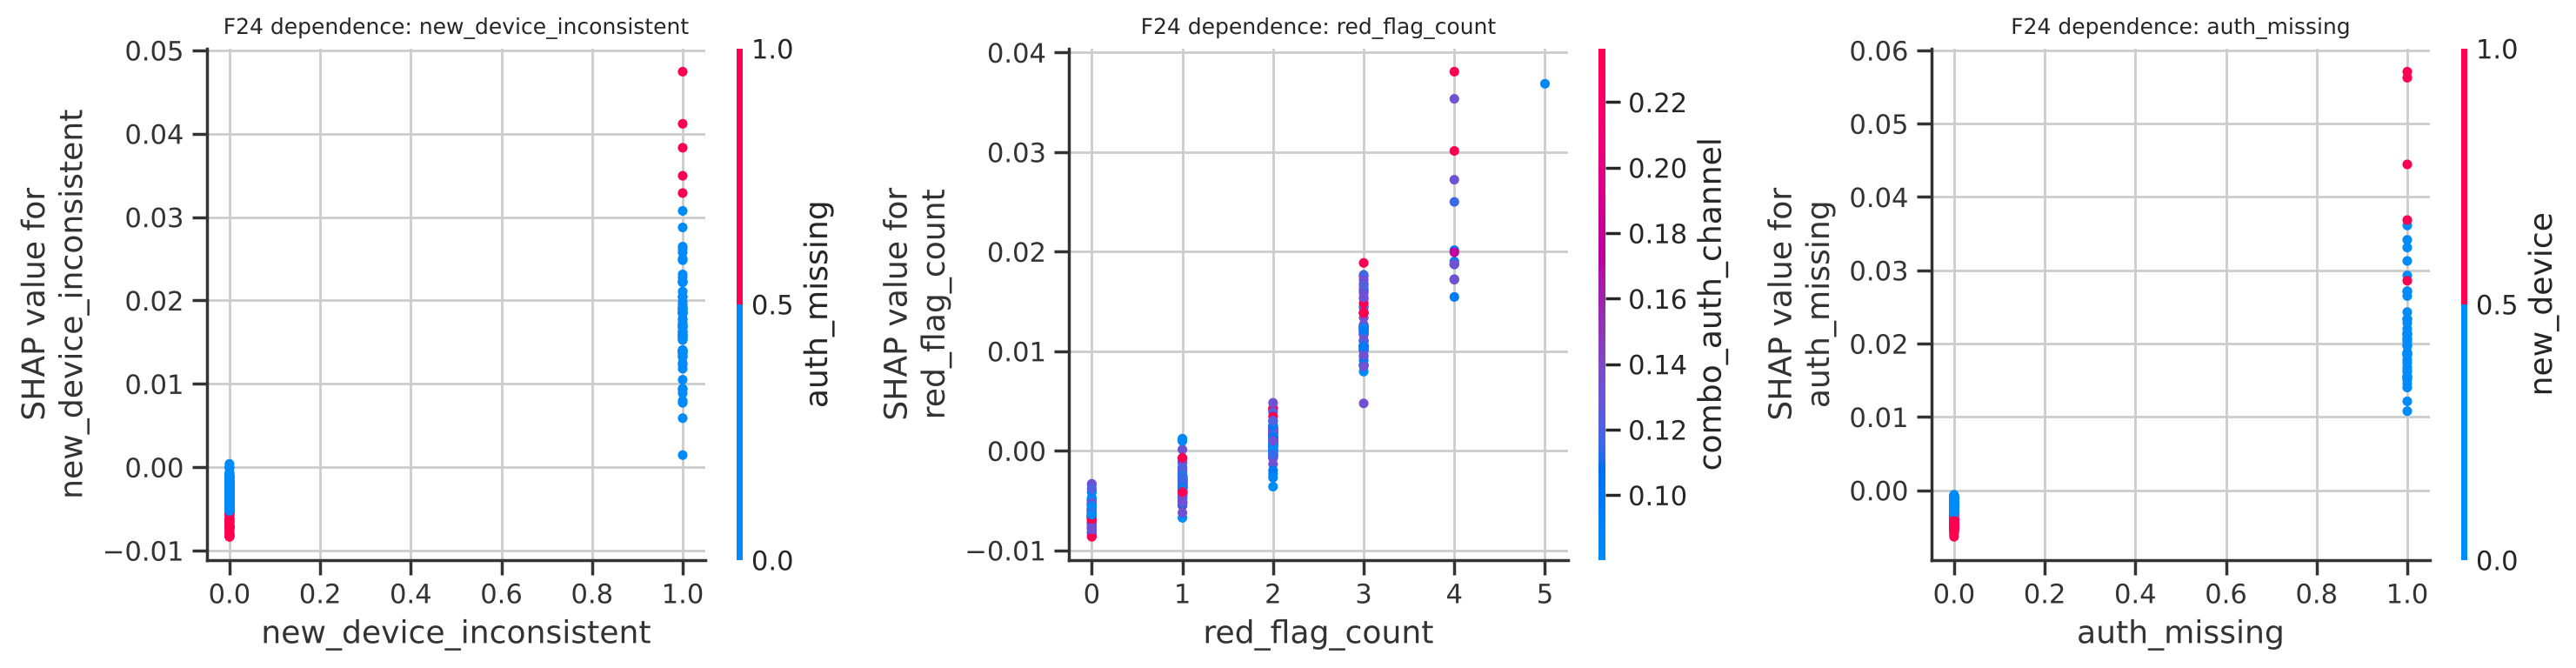

,feature_a,feature_b,mean_abs_interaction
6825,new_device_inconsistent,auth_missing,0.00111
6869,new_device_inconsistent,authentication_level_Missing,0.00105
1925,new_device,auth_missing,0.00088
1969,new_device,authentication_level_Missing,0.00069
7783,prior_chargeback_flag,high_merchant_flag,0.00062
6727,device_older_than_account,new_device_inconsistent,0.00057
6900,distance_x_new_device,auth_missing,0.00052
1138,prior_chargebacks,new_device_inconsistent,0.00049
6817,new_device_inconsistent,prior_chargeback_flag,0.00045
8257,auth_missing,freq_country,0.00041


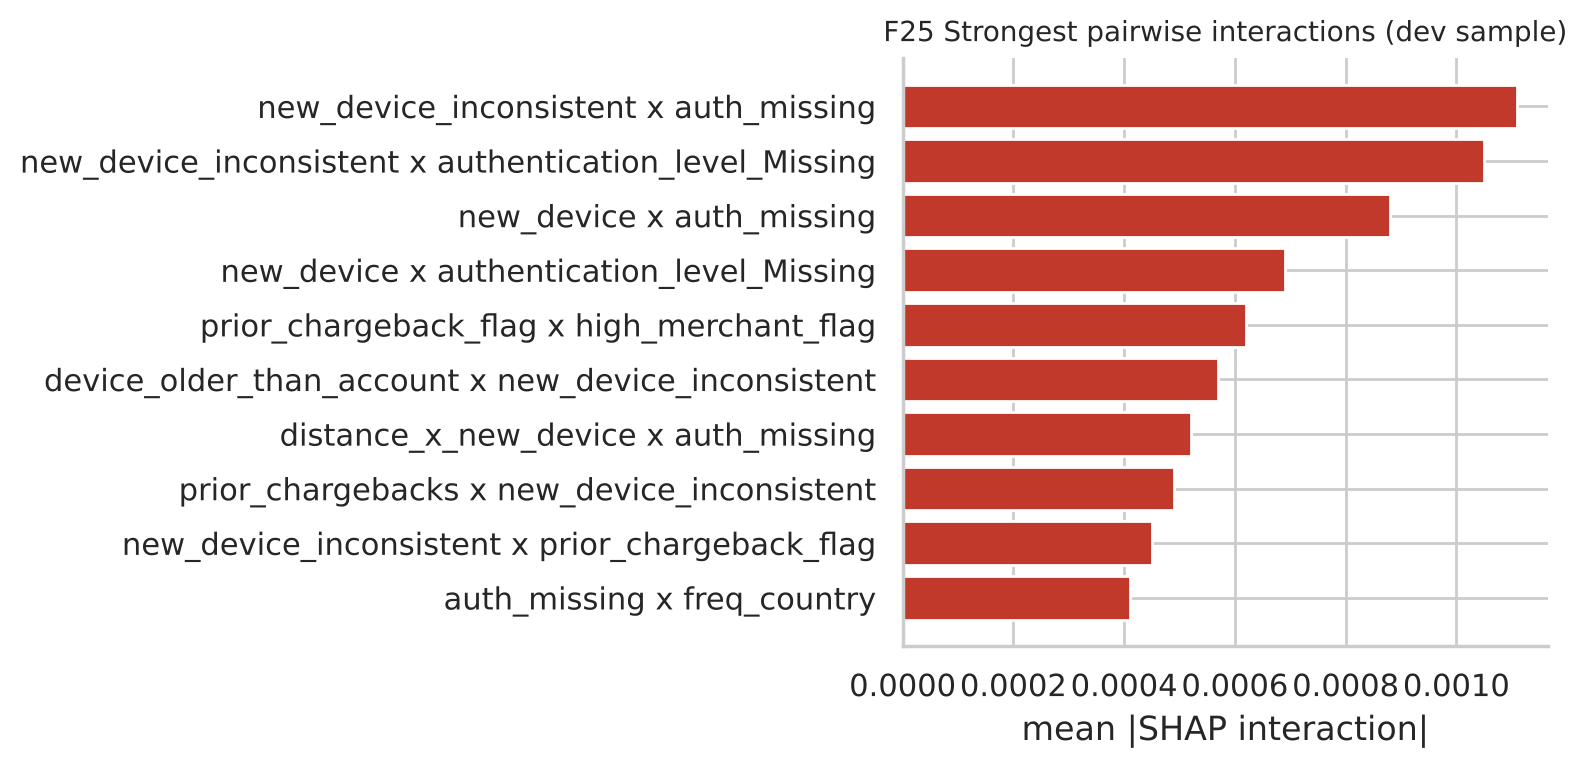

In [36]:
top3 = list(imp.index[:3]); fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(axs, top3):
    plt.sca(a); shap.dependence_plot(f, SV, Xs, interaction_index="auto", show=False, ax=a); a.set_title(f"F24 dependence: {f}", fontsize=9)
savefig("F24_shap_dependence")
# interaction analysis
Xi = Xs.iloc[:200]; SI = shap_pos(Xi, interactions=True)
M = np.abs(SI).mean(0); np.fill_diagonal(M, 0); pairs = [(fn[i], fn[j], M[i, j] * 2) for i in range(len(fn)) for j in range(i + 1, len(fn))]
inter = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "mean_abs_interaction"]).sort_values("mean_abs_interaction", ascending=False).head(10).round(5); display(inter)
R["shap_interactions"] = inter.to_dict("records")
fig, ax = plt.subplots(figsize=(8, 4)); ax.barh([f"{a} x {b}" for a, b in zip(inter.feature_a, inter.feature_b)][::-1], inter.mean_abs_interaction[::-1], color=C_FRAUD); ax.set_xlabel("mean |SHAP interaction|"); ax.set_title("F25 Strongest pairwise interactions (dev sample)", fontsize=10); savefig("F25_shap_interactions")

### H2. Transaction-level explanations (five test transactions + reason codes)

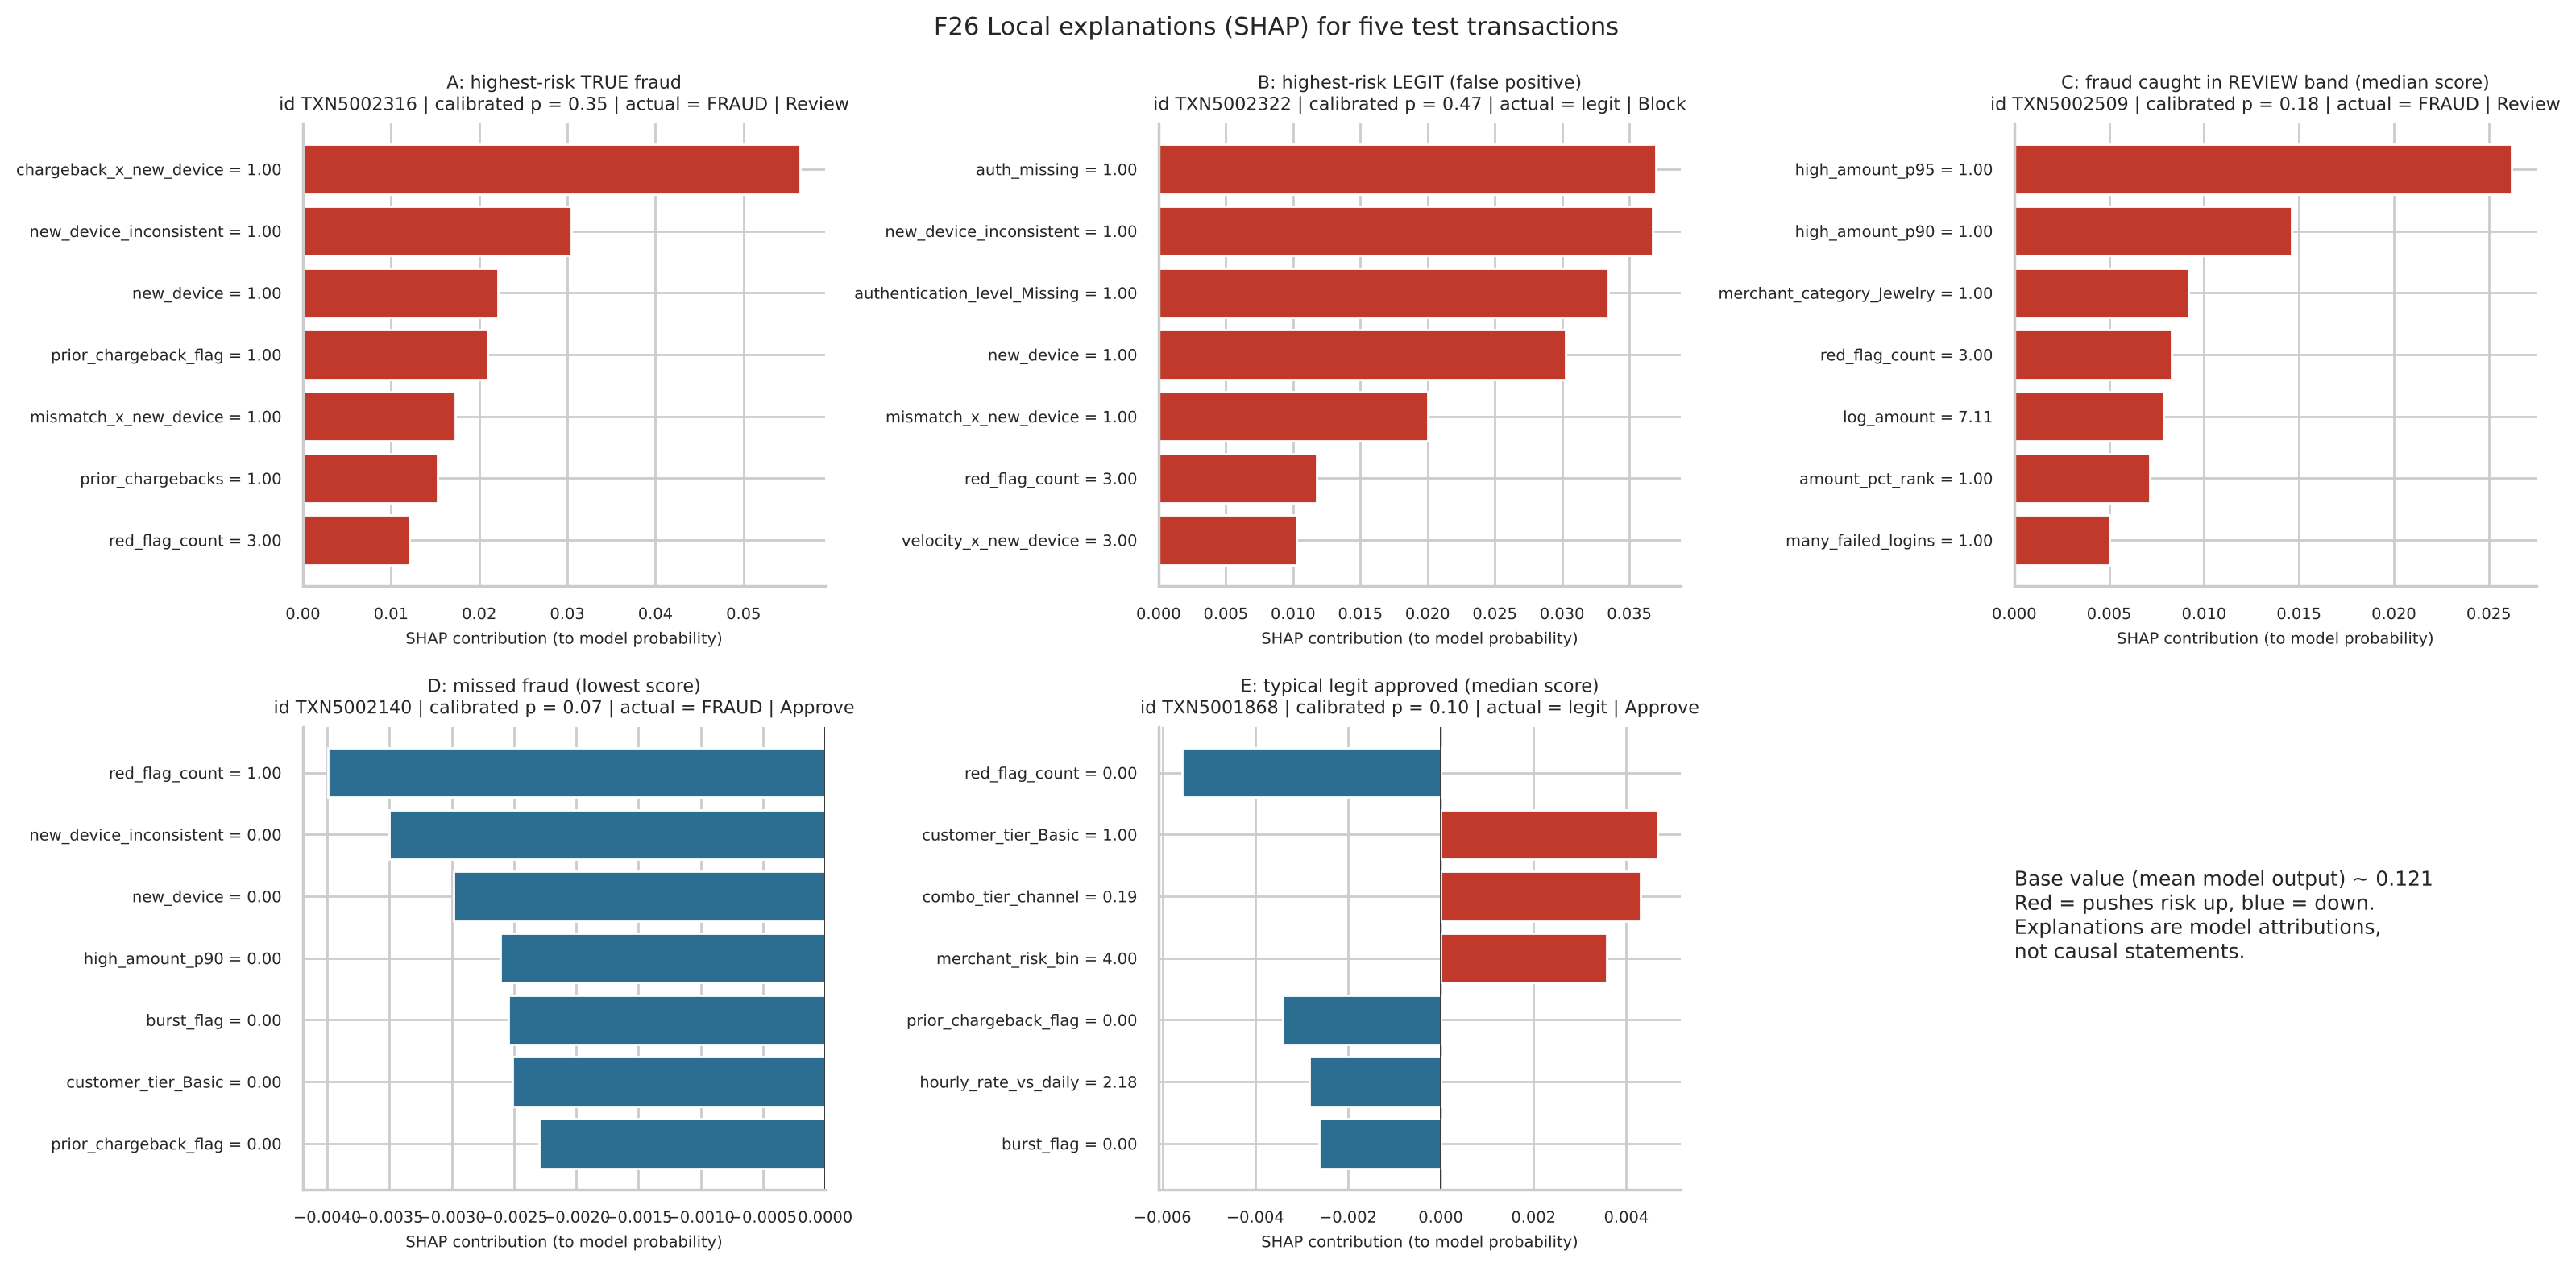

,case,transaction_id,p_cal,reason_code,value,shap
0,A: highest-risk TRUE fraud,TXN5002316,0.348,chargeback_x_new_device,1.000,0.0564
1,A: highest-risk TRUE fraud,TXN5002316,0.348,new_device_inconsistent,1.000,0.0304
2,A: highest-risk TRUE fraud,TXN5002316,0.348,new_device,1.000,0.0221
3,B: highest-risk LEGIT (false positive),TXN5002322,0.470,auth_missing,1.000,0.0370
4,B: highest-risk LEGIT (false positive),TXN5002322,0.470,new_device_inconsistent,1.000,0.0367
5,B: highest-risk LEGIT (false positive),TXN5002322,0.470,authentication_level_Missing,1.000,0.0334
6,C: fraud caught in REVIEW band (median score),TXN5002509,0.180,high_amount_p95,1.000,0.0262
7,C: fraud caught in REVIEW band (median score),TXN5002509,0.180,high_amount_p90,1.000,0.0146
8,C: fraud caught in REVIEW band (median score),TXN5002509,0.180,merchant_category_Jewelry,1.000,0.0092
9,D: missed fraud (lowest score),TXN5002140,0.065,channel_POS,0.000,0.0016


In [37]:
Xt_te = tf(X_test); te_df = pd.DataFrame({"p_cal": p_test, "y": y_test.values, "decision": decide(p_test, t_rev, t_blk)}, index=X_test.index)
picks = {}
picks["A: highest-risk TRUE fraud"] = te_df[te_df.y == 1].p_cal.idxmax()
picks["B: highest-risk LEGIT (false positive)"] = te_df[te_df.y == 0].p_cal.idxmax()
rev = te_df[(te_df.decision == 1) & (te_df.y == 1) & (te_df.index != picks["A: highest-risk TRUE fraud"])].p_cal.sort_values(); picks["C: fraud caught in REVIEW band (median score)"] = rev.index[len(rev) // 2]
picks["D: missed fraud (lowest score)"] = te_df[te_df.y == 1].p_cal.idxmin()
picks["E: typical legit approved (median score)"] = (te_df[te_df.y == 0].p_cal - te_df[te_df.y == 0].p_cal.median()).abs().idxmin()
idxs = list(picks.values()); SVl = shap_pos(Xt_te.loc[idxs]); base_val = float(np.ravel(tree.expected_value)[-1])
fig, axs = plt.subplots(2, 3, figsize=(16, 8)); local_rows = []
for a, (lab, ix), sv in zip(axs.ravel(), picks.items(), SVl):
    s = pd.Series(sv, index=fn); top = s.reindex(s.abs().sort_values(ascending=False).index[:7])[::-1]
    vals = Xt_te.loc[ix, top.index]
    a.barh([f"{k} = {v:.2f}" for k, v in zip(top.index, vals)], top.values, color=[C_FRAUD if v > 0 else C_OK for v in top.values]); a.axvline(0, color="k", lw=.6)
    a.set_title(f"{lab}\nid {raw.loc[ix, ID_COL]} | calibrated p = {te_df.loc[ix, 'p_cal']:.2f} | actual = {'FRAUD' if te_df.loc[ix, 'y'] else 'legit'} | {['Approve', 'Review', 'Block'][te_df.loc[ix, 'decision']]}", fontsize=8)
    a.tick_params(labelsize=7); a.set_xlabel("SHAP contribution (to model probability)", fontsize=7)
    for f_, v_ in s.sort_values(ascending=False).head(3).items(): local_rows.append(dict(case=lab, transaction_id=raw.loc[ix, ID_COL], p_cal=round(te_df.loc[ix, "p_cal"], 3), reason_code=f_, value=round(float(Xt_te.loc[ix, f_]), 3), shap=round(float(v_), 4)))
axs.ravel()[-1].axis("off"); axs.ravel()[-1].text(0, .5, f"Base value (mean model output) ~ {base_val:.3f}\nRed = pushes risk up, blue = down.\nExplanations are model attributions,\nnot causal statements.", fontsize=9)
fig.suptitle("F26 Local explanations (SHAP) for five test transactions", fontsize=11); savefig("F26_shap_local")
local_df = pd.DataFrame(local_rows); local_df.to_csv("local_explanations_reason_codes.csv", index=False); display(local_df)
R["local_cases"] = [dict(case=k, id=raw.loc[v, ID_COL], p=float(te_df.loc[v, "p_cal"]), y=int(te_df.loc[v, "y"]), decision=int(te_df.loc[v, "decision"])) for k, v in picks.items()]

### H3. Are the explanations stable and plausible?
(a) Does the importance ranking survive across the 5 CV folds (models refitted per fold)? (b) Do the directions agree with domain expectations?

In [38]:
fold_imp = {}
for k, ((tr, va), m) in enumerate(zip(CV.split(X_dev, y_dev), FMODELS[EXPL])):
    Xv = pd.DataFrame(m.named_steps["prep"].transform(X_dev.iloc[va]), columns=feature_names(m)).iloc[:250]
    ex = shap.TreeExplainer(m.named_steps["model"]); v = ex.shap_values(Xv, check_additivity=False)
    v = np.asarray(v[1]) if isinstance(v, list) else (np.asarray(v)[..., 1] if np.ndim(v) == 3 else np.asarray(v))
    fold_imp[k] = pd.Series(np.abs(v).mean(0), index=Xv.columns)
FI = pd.DataFrame(fold_imp).fillna(0)
top_feats = FI.mean(axis=1).sort_values(ascending=False).head(10).index
stab = pd.DataFrame({"mean_importance": FI.loc[top_feats].mean(axis=1), "cv_across_folds": FI.loc[top_feats].std(axis=1) / FI.loc[top_feats].mean(axis=1),
                     **{f"rank_fold{k}": FI.rank(ascending=False).loc[top_feats, k].astype(int) for k in FI.columns}}).round(3); display(stab)
sp = [stats.spearmanr(FI[a], FI[b])[0] for a in FI.columns for b in FI.columns if a < b]
top5 = [set(FI[c].nlargest(5).index) for c in FI.columns]; jac = np.mean([len(a & b) / len(a | b) for i, a in enumerate(top5) for b in top5[i + 1:]])
print(f"pairwise Spearman of importance vectors across folds: mean {np.mean(sp):.2f} (min {np.min(sp):.2f}); top-5 Jaccard overlap {jac:.2f}")
R["fold_stability"] = dict(spearman_mean=float(np.mean(sp)), spearman_min=float(np.min(sp)), top5_jaccard=float(jac), top_features=list(top_feats), cv_of_top=stab.cv_across_folds.to_dict())
R["fold_stability_table"] = stab.reset_index().rename(columns={"index": "feature"}).to_dict("records")

exp_dir = {"new_device": "+", "prior_chargebacks": "+", "billing_address_mismatch": "+", "ip_risk_score": "+", "merchant_risk_score": "+", "transactions_last_1h": "+", "failed_logins_24h": "+",
           "transaction_amount": "+", "distance_from_usual_location_km": "+", "account_age_days": "-", "login_to_transaction_minutes": "-", "device_age_days": "-", "email_age_days": "-"}
rows = []
for f_, e_ in exp_dir.items():
    if f_ in Xs:
        rho = stats.spearmanr(Xs[f_], SV[:, list(Xs.columns).index(f_)])[0]
        rows.append(dict(feature=f_, expected_sign=e_, observed_spearman_value_vs_shap=round(rho, 3), consistent="yes" if (rho > 0.1 and e_ == "+") or (rho < -0.1 and e_ == "-") else ("weak" if abs(rho) <= 0.1 else "COUNTER-INTUITIVE"), mean_abs_shap=round(float(np.abs(SV[:, list(Xs.columns).index(f_)]).mean()), 4)))
dirs = pd.DataFrame(rows).sort_values("mean_abs_shap", ascending=False); display(dirs); R["direction_check"] = dirs.to_dict("records")

,mean_importance,cv_across_folds,rank_fold0,rank_fold1,rank_fold2,rank_fold3,rank_fold4
new_device_inconsistent,0.006,0.210,1,7,3,1,1
red_flag_count,0.005,0.213,3,1,4,2,4
new_device,0.005,0.239,2,8,7,4,3
authentication_level_Missing,0.004,0.317,13,3,2,7,7
auth_missing,0.004,0.292,14,4,5,3,5
prior_chargeback_flag,0.004,0.428,5,10,1,19,6
burst_flag,0.004,0.391,10,6,6,9,2
high_amount_p90,0.004,0.418,6,5,23,5,12
high_amount_p95,0.003,0.263,7,9,11,21,10
new_device_x_cnp,0.003,0.700,9,2,52,29,9


pairwise Spearman of importance vectors across folds: mean 0.85 (min 0.79); top-5 Jaccard overlap 0.40


,feature,expected_sign,observed_spearman_value_vs_shap,consistent,mean_abs_shap
0,new_device,+,0.639,yes,0.0047
1,prior_chargebacks,+,0.547,yes,0.0025
5,transactions_last_1h,+,0.911,yes,0.0022
4,merchant_risk_score,+,0.860,yes,0.0016
2,billing_address_mismatch,+,0.542,yes,0.0012
9,account_age_days,-,-0.893,yes,0.0009
3,ip_risk_score,+,0.786,yes,0.0006
11,device_age_days,-,-0.298,yes,0.0004
7,transaction_amount,+,0.564,yes,0.0003
12,email_age_days,-,-0.258,yes,0.0002


**Discussion.** Importance rankings are only moderately stable across folds (see Spearman / Jaccard) because the dataset is small (about 290 fraud cases in the dev set) and the signal is weak; the top few features recur, the tail reshuffles. Features flagged *weak* or *COUNTER-INTUITIVE* above should not be used for customer-facing reason codes without more data. Highly correlated features (e.g. `merchant_risk_score`, `combined_risk_mean`, `amount_x_merchant_risk`) split credit between them, so individual SHAP values understate the importance of the underlying concept. Finally, SHAP explains *what the model uses*: a high contribution of `new_device` means the model associates it with fraud in this dataset, **not** that switching device causes fraud, and observational data cannot separate those.

### H4. Which *raw input fields* matter? Permutation importance through the whole pipeline
For each of the 23 raw fields we shuffle that column in the validation fold (feature engineering is recomputed from the shuffled field, so all derived features are disrupted too) and measure the drop in ROC-AUC / PR-AUC. Repeated over 5 folds x 4 shuffles gives both importance and its stability. This is also the list of fields to monitor for drift.

,roc_drop,roc_sd,pr_drop,pr_sd,folds_positive
feature,,,,,
new_device,0.0432,0.0175,0.0416,0.0192,5
transaction_amount,0.0320,0.0205,0.0234,0.0096,5
merchant_risk_score,0.0292,0.0091,0.0323,0.0094,5
authentication_level,0.0153,0.0118,0.0246,0.0150,4
prior_chargebacks,0.0152,0.0123,0.0237,0.0110,4
transactions_last_1h,0.0135,0.0039,0.0088,0.0057,5
account_age_days,0.0064,0.0057,0.0002,0.0038,5
ip_risk_score,0.0062,0.0085,0.0093,0.0052,4
transactions_last_24h,0.0051,0.0025,0.0031,0.0028,5


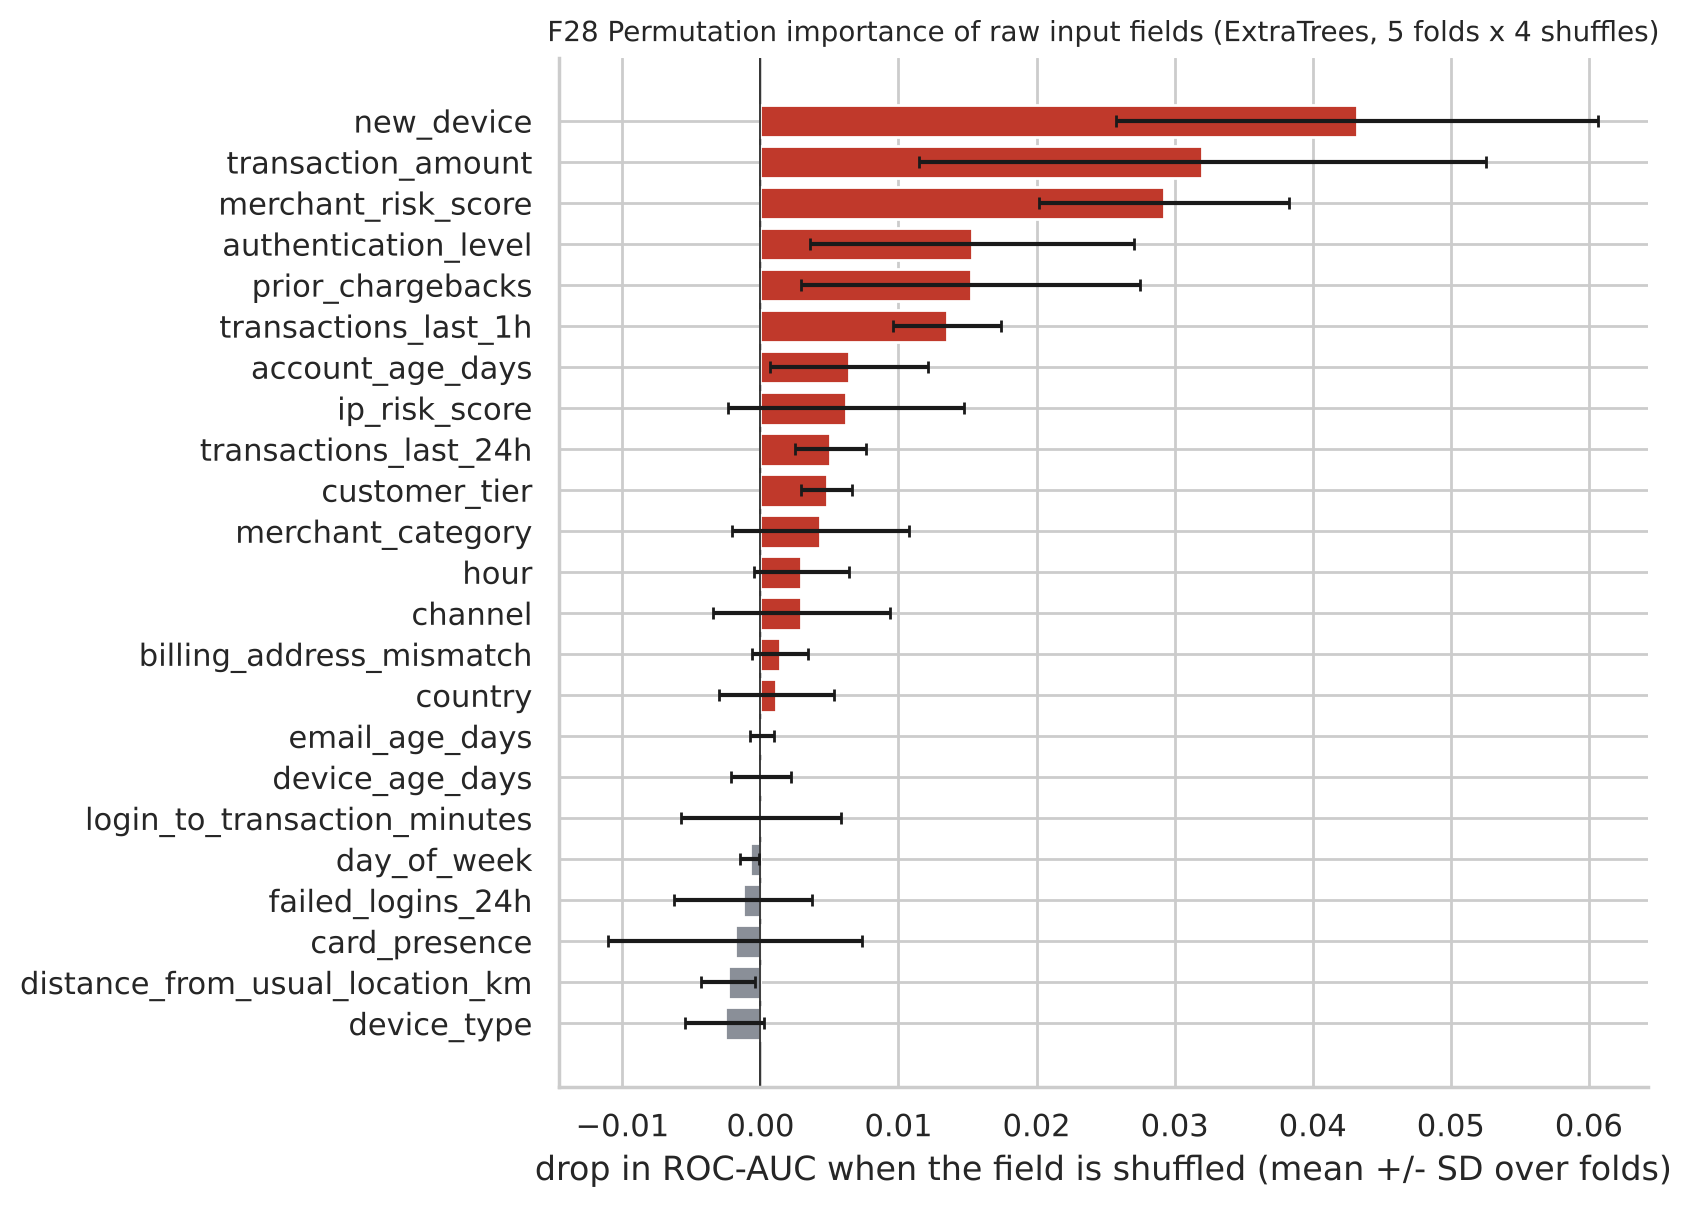

In [39]:
perm_rows = []; rg = np.random.default_rng(SEED)
for k, ((tr, va), m) in enumerate(zip(CV.split(X_dev, y_dev), FMODELS[FINAL])):
    Xv, yv = X_dev.iloc[va], y_dev.iloc[va]; pb = m.predict_proba(Xv)[:, 1]; b_pr, b_roc = average_precision_score(yv, pb), roc_auc_score(yv, pb)
    for col in X_dev.columns:
        dpr, droc = [], []
        for _ in range(4):
            Xp = Xv.copy(); Xp[col] = rg.permutation(Xp[col].values); pp = m.predict_proba(Xp)[:, 1]
            dpr.append(b_pr - average_precision_score(yv, pp)); droc.append(b_roc - roc_auc_score(yv, pp))
        perm_rows.append(dict(fold=k, feature=col, d_pr=np.mean(dpr), d_roc=np.mean(droc)))
perm = pd.DataFrame(perm_rows); pg = perm.groupby("feature").agg(roc_drop=("d_roc", "mean"), roc_sd=("d_roc", "std"), pr_drop=("d_pr", "mean"), pr_sd=("d_pr", "std"), folds_positive=("d_roc", lambda x: int((x > 0).sum()))).sort_values("roc_drop", ascending=False)
display(pg.round(4)); R["perm_importance"] = pg.round(5).reset_index().to_dict("records"); pg.round(5).to_csv("permutation_importance_raw_fields.csv")
fig, ax = plt.subplots(figsize=(8.5, 6.2)); t = pg[::-1]
ax.barh(t.index, t.roc_drop, xerr=t.roc_sd, color=[C_FRAUD if v > 0 else C_GREY for v in t.roc_drop], capsize=2); ax.axvline(0, color="k", lw=.6)
ax.set_xlabel("drop in ROC-AUC when the field is shuffled (mean +/- SD over folds)"); ax.set_title(f"F28 Permutation importance of raw input fields ({FINAL}, 5 folds x 4 shuffles)", fontsize=10); savefig("F28_permutation_importance")

### Lift and cumulative gains on the locked test set
Business view of the ranking: if analysts work the list from the highest score down, how much fraud is found?

,n,frauds,fraud_rate,mean_p,lift,cum_capture
decile,,,,,,
1,60,13,0.217,0.281,1.781,0.178
2,60,13,0.217,0.173,1.781,0.356
3,60,8,0.133,0.139,1.096,0.466
4,60,11,0.183,0.116,1.507,0.616
5,60,7,0.117,0.104,0.959,0.712
6,60,8,0.133,0.095,1.096,0.822
7,60,5,0.083,0.086,0.685,0.890
8,60,5,0.083,0.079,0.685,0.959
9,60,2,0.033,0.071,0.274,0.986


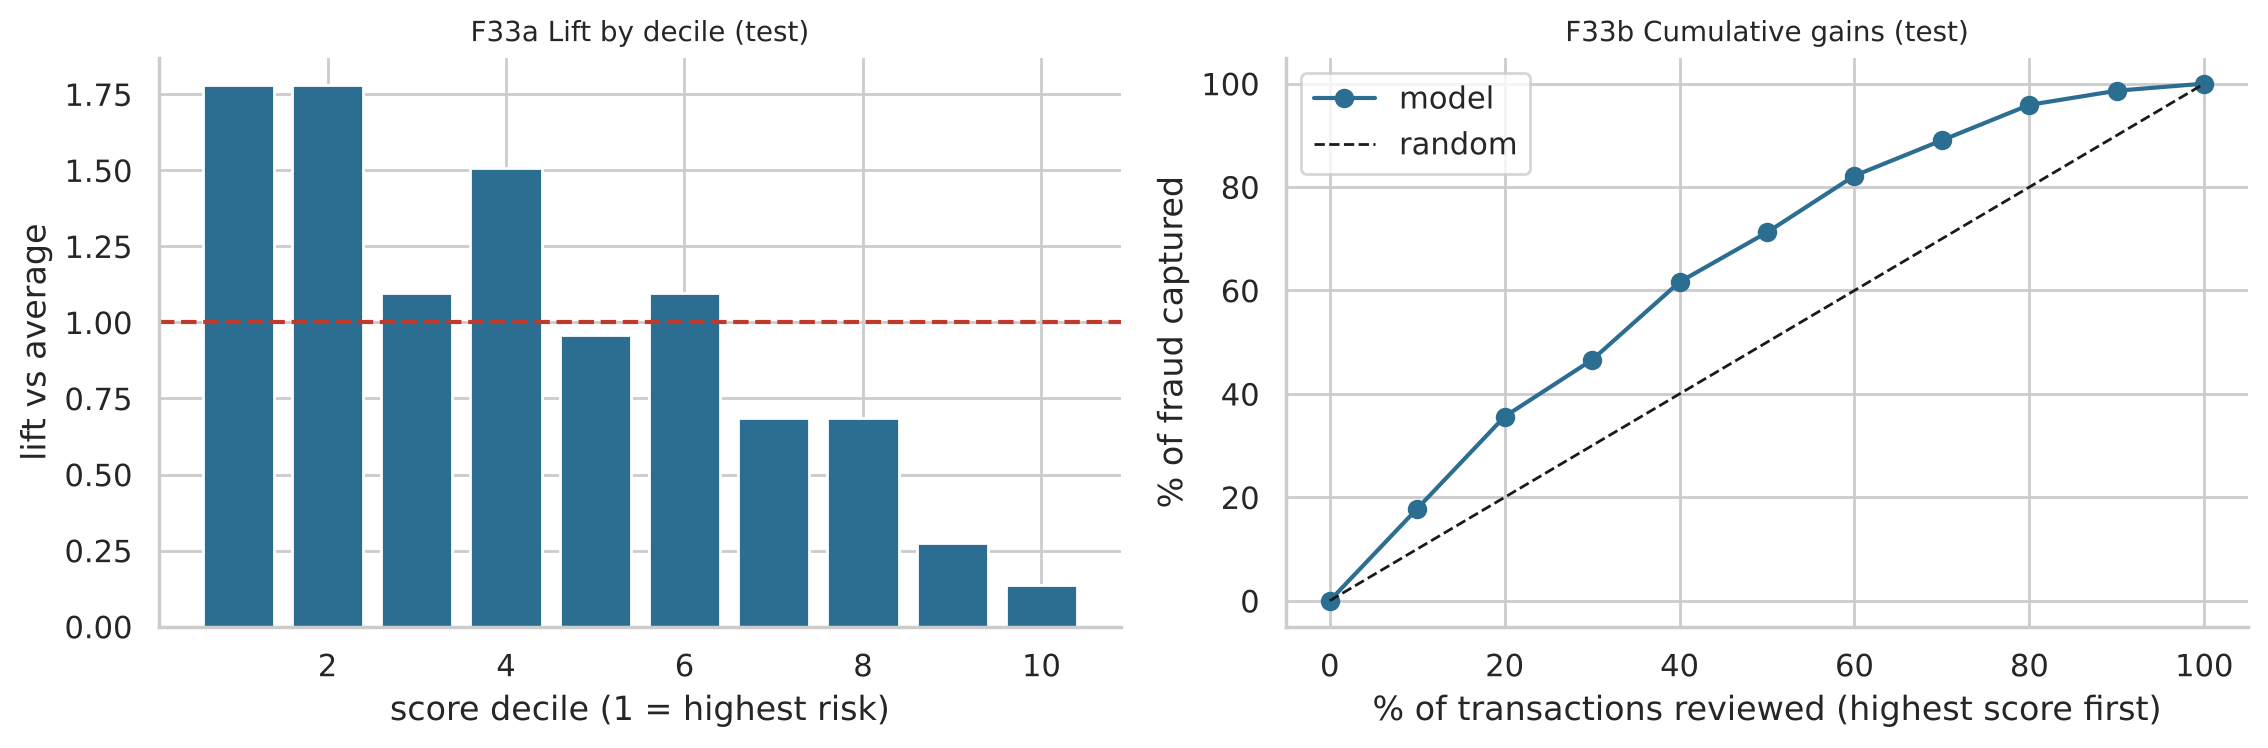

{'tp': 32, 'fp': 117, 'fn': 41, 'tn': 410}


In [40]:
dfl = pd.DataFrame({"p": p_test, "y": y_test.values}).sort_values("p", ascending=False).reset_index(drop=True); dfl["decile"] = np.floor(np.arange(len(dfl)) / len(dfl) * 10).astype(int) + 1
lift = dfl.groupby("decile").agg(n=("y", "size"), frauds=("y", "sum"), fraud_rate=("y", "mean"), mean_p=("p", "mean")); lift["lift"] = lift.fraud_rate / y_test.mean()
lift["cum_capture"] = lift.frauds.cumsum() / lift.frauds.sum(); display(lift.round(3)); R["lift_table"] = lift.round(4).reset_index().to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9)); ax[0].bar(lift.index, lift.lift, color=C_OK); ax[0].axhline(1, color=C_FRAUD, ls="--"); ax[0].set_xlabel("score decile (1 = highest risk)"); ax[0].set_ylabel("lift vs average"); ax[0].set_title("F33a Lift by decile (test)", fontsize=10)
ax[1].plot(np.r_[0, lift.index * 10], np.r_[0, lift.cum_capture * 100], marker="o", color=C_OK, label="model"); ax[1].plot([0, 100], [0, 100], "k--", lw=1, label="random"); ax[1].set_xlabel("% of transactions reviewed (highest score first)"); ax[1].set_ylabel("% of fraud captured"); ax[1].legend(); ax[1].set_title("F33b Cumulative gains (test)", fontsize=10); savefig("F33_lift_gains")
dec_t = decide(p_test, t_rev, t_blk); flg = dec_t > 0
yt_ = y_test.values
R["confusion_test"] = dict(tp=int((flg & yt_.astype(bool)).sum()), fp=int((flg & ~yt_.astype(bool)).sum()), fn=int((~flg & yt_.astype(bool)).sum()), tn=int((~flg & ~yt_.astype(bool)).sum()))
print(R["confusion_test"])

## J. Robustness and stress testing (frozen model and thresholds, test set used for evaluation only)

,n,fraud_rate,roc_auc,pr_auc,brier,mean_pred,flagged_share,review_share,block_share,fraud_stopped,cost_per_txn,approve_all_cost,saving_pct,score_psi
scenario,,,,,,,,,,,,,,
baseline (test),600,0.1217,0.6703,0.1885,0.1057,0.1208,0.2483,0.2283,0.0200,0.3945,15.4453,22.2978,30.7316,0.0000
amounts x1.5,600,0.1217,0.6608,0.1793,0.1063,0.1297,0.3067,0.2817,0.0250,0.4562,17.7728,32.5341,45.3718,0.0331
amounts x3,600,0.1217,0.5949,0.1494,0.1106,0.1552,0.4767,0.4433,0.0333,0.5425,25.5801,63.2433,59.5528,0.3486
"velocity surge (1h +2, 24h x1.5)",600,0.1217,0.6542,0.1823,0.1063,0.1381,0.3183,0.2900,0.0283,0.4219,16.4024,22.2978,26.4392,0.3349
channel mix: E-commerce x3 (resampled),600,0.1333,0.6938,0.2422,0.1111,0.1229,0.2483,0.2267,0.0217,0.4388,15.8844,26.9461,41.0510,0.0212
channel mix: ATM x4 (resampled),600,0.1350,0.6819,0.1948,0.1172,0.1289,0.3133,0.2867,0.0267,0.4556,17.7808,25.6954,30.8015,0.0423
new-device surge (+10% of known devices flip),600,0.1217,0.6563,0.1979,0.1054,0.1277,0.2817,0.2550,0.0267,0.4096,15.9707,22.2978,28.3753,0.0126
"extra missing values 5% (MCAR, 6 fields)",600,0.1217,0.6548,0.1779,0.1064,0.1216,0.2567,0.2383,0.0183,0.3822,16.3969,22.2978,26.4641,0.0024
"extra missing values 10% (MCAR, 6 fields)",600,0.1217,0.6453,0.1742,0.1069,0.1218,0.2433,0.2217,0.0217,0.3712,15.7287,22.2978,29.4607,0.0057


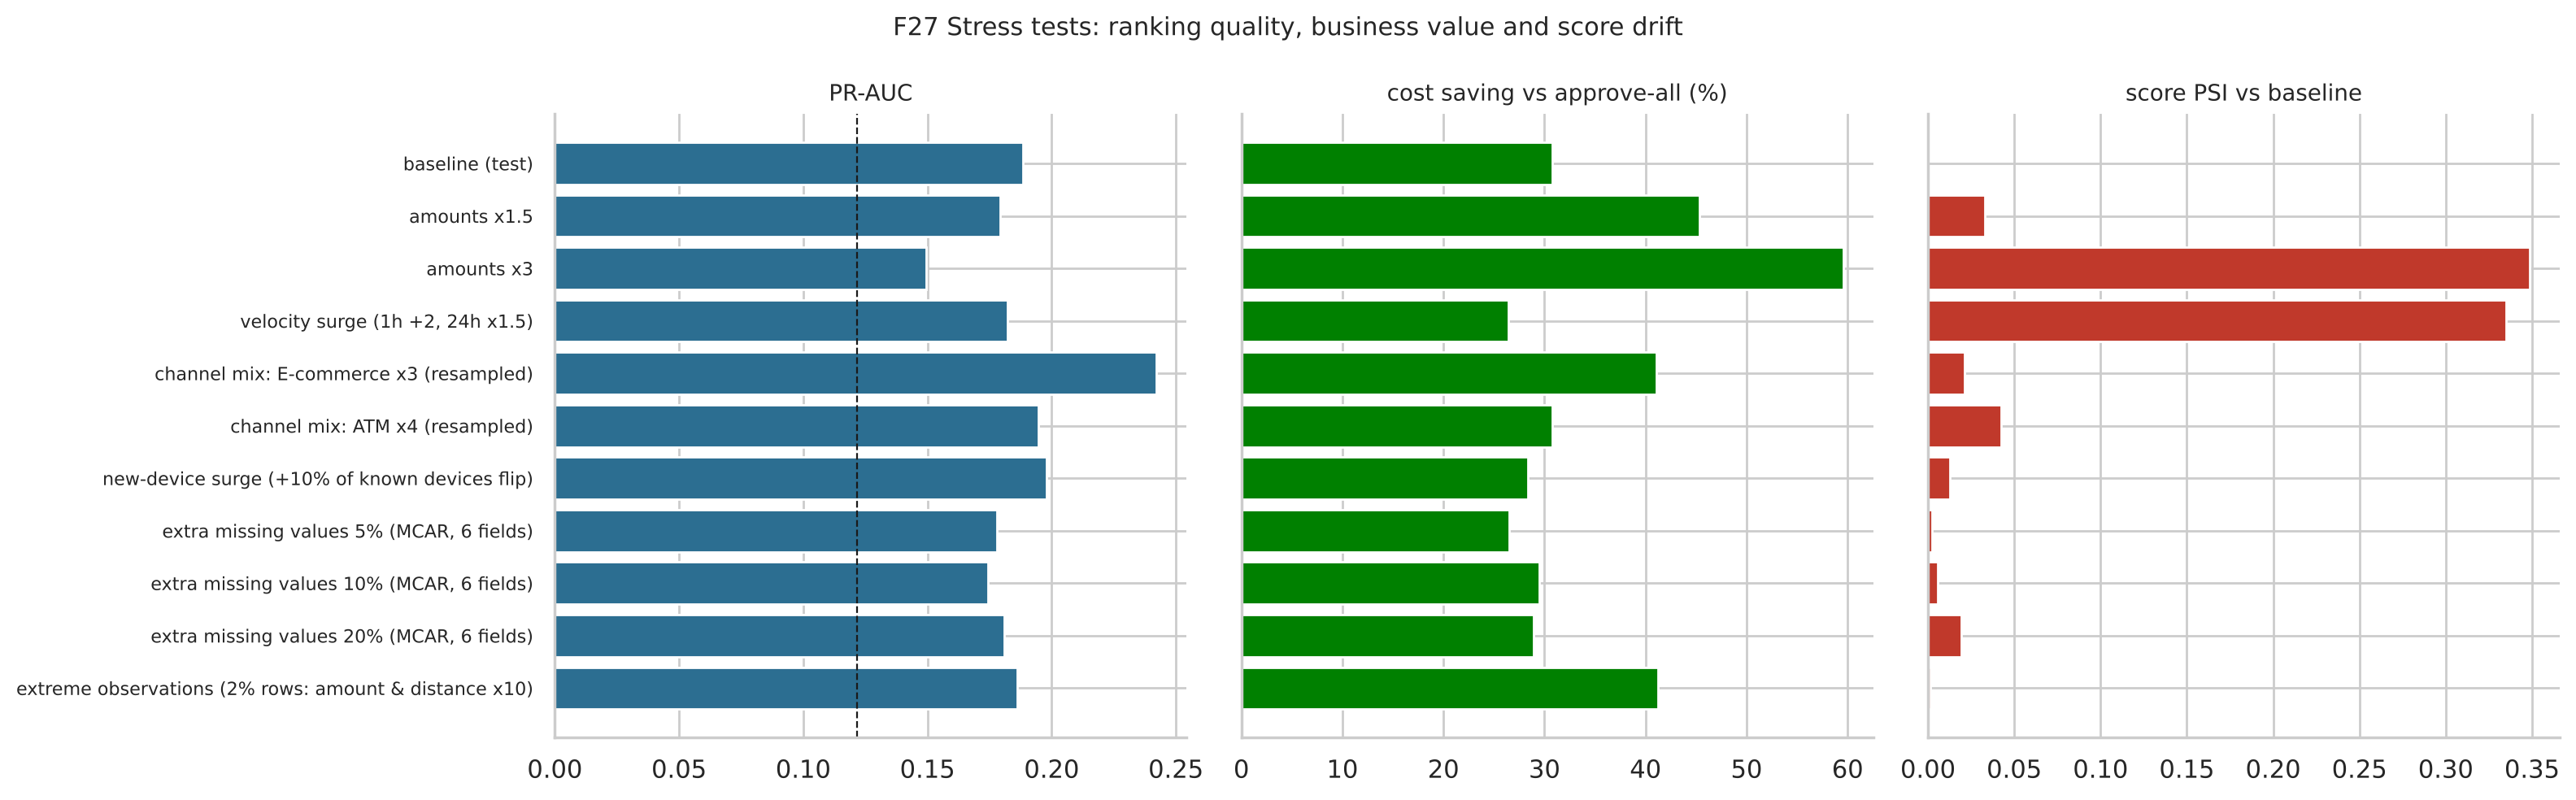

In [41]:
def eval_scn(name, Xs_, ys_, amts_):
    p = cal_model.predict_proba(Xs_)[:, 1]; d = decide(p, t_rev, t_blk); c = policy_costs(ys_, amts_, d, BASE); c0 = policy_costs(ys_, amts_, np.zeros(len(ys_), int), BASE)
    return dict(scenario=name, n=len(ys_), fraud_rate=float(np.mean(ys_)), roc_auc=roc_auc_score(ys_, p), pr_auc=average_precision_score(ys_, p), brier=brier_score_loss(ys_, p),
                mean_pred=p.mean(), flagged_share=(d > 0).mean(), review_share=(d == 1).mean(), block_share=(d == 2).mean(),
                fraud_stopped=((ys_ == 1) * ((d == 2) + BASE.analyst_recall * (d == 1))).sum() / max(1, ys_.sum()), cost_per_txn=c.mean(), approve_all_cost=c0.mean(),
                saving_pct=(1 - c.sum() / c0.sum()) * 100, score_psi=psi(p_test, p)), p
yt = y_test.values; scn_rows = []
scn_rows.append(eval_scn("baseline (test)", X_test, yt, amt_test)[0])
for mlt in [1.5, 3]:
    Xm = X_test.copy(); Xm["transaction_amount"] *= mlt; scn_rows.append(eval_scn(f"amounts x{mlt}", Xm, yt, amt_test * mlt)[0])
Xv_ = X_test.copy(); Xv_["transactions_last_24h"] = np.ceil(Xv_.transactions_last_24h * 1.5); Xv_["transactions_last_1h"] = np.minimum(Xv_.transactions_last_1h + 2, Xv_.transactions_last_24h); scn_rows.append(eval_scn("velocity surge (1h +2, 24h x1.5)", Xv_, yt, amt_test)[0])
for ch, w in [("E-commerce", 3.0), ("ATM", 4.0)]:
    wts = np.where(X_test.channel == ch, w, 1.0); wts = wts / wts.sum(); ii = np.random.default_rng(SEED).choice(len(X_test), len(X_test), p=wts)
    scn_rows.append(eval_scn(f"channel mix: {ch} x{w:g} (resampled)", X_test.iloc[ii], yt[ii], amt_test[ii])[0])
Xn = X_test.copy(); rg = np.random.default_rng(SEED); mask = (Xn.new_device == 0) & (rg.random(len(Xn)) < 0.10); Xn.loc[mask, "new_device"] = 1; scn_rows.append(eval_scn("new-device surge (+10% of known devices flip)", Xn, yt, amt_test)[0])
for rate in [0.05, 0.10, 0.20]:
    Xm = X_test.copy(); rg = np.random.default_rng(SEED)
    for c in ["transaction_amount", "distance_from_usual_location_km", "merchant_risk_score", "ip_risk_score", "login_to_transaction_minutes", "authentication_level"]:
        Xm.loc[rg.random(len(Xm)) < rate, c] = np.nan
    scn_rows.append(eval_scn(f"extra missing values {int(rate*100)}% (MCAR, 6 fields)", Xm, yt, amt_test)[0])
Xe = X_test.copy(); rg = np.random.default_rng(SEED); ex_m = rg.random(len(Xe)) < 0.02; Xe.loc[ex_m, ["transaction_amount", "distance_from_usual_location_km"]] *= 10; a_e = amt_test.copy(); a_e[ex_m] *= 10
scn_rows.append(eval_scn("extreme observations (2% rows: amount & distance x10)", Xe, yt, a_e)[0])
rob = pd.DataFrame(scn_rows).round(4); display(rob.set_index("scenario")); R["robustness"] = rob.to_dict("records")
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
y_ = np.arange(len(rob))[::-1]
for a, col, ttl, clr in zip(ax, ["pr_auc", "saving_pct", "score_psi"], ["PR-AUC", "cost saving vs approve-all (%)", "score PSI vs baseline"], [C_OK, "green", C_FRAUD]):
    a.barh(y_, rob[col], color=clr); a.set_title(ttl, fontsize=10)
ax[0].set_yticks(y_); ax[0].set_yticklabels(rob.scenario, fontsize=8); ax[0].axvline(R["test_prevalence"], color="k", ls="--", lw=.8)
fig.suptitle("F27 Stress tests: ranking quality, business value and score drift", fontsize=11); savefig("F27_stress_tests")

### J2. Pseudo-temporal check (dev only) and bootstrap confidence on the final test metrics
The dataset has no timestamp. `transaction_id` is numeric and sequential, so as a *weak proxy for time* we train on the first 75 % of dev ids and evaluate on the last 25 % (we showed in A4 that fraud rate is flat over id). This is **not** a true out-of-time test.

In [42]:
order = np.argsort(id_dev.str[3:].astype(int).values); cut = int(.75 * len(order)); tr_i, va_i = order[:cut], order[cut:]
pt = clone(cal_unfitted).fit(X_dev.iloc[tr_i], y_dev.iloc[tr_i]); pp = pt.predict_proba(X_dev.iloc[va_i])[:, 1]
R["pseudo_temporal"] = dict(pr_auc=float(average_precision_score(y_dev.iloc[va_i], pp)), roc_auc=float(roc_auc_score(y_dev.iloc[va_i], pp)), cv_pr_auc=float(FOLDS[FINAL].pr_auc.mean()), cv_roc=float(FOLDS[FINAL].roc_auc.mean()), base_rate=float(y_dev.iloc[va_i].mean()))
print(R["pseudo_temporal"])

{'pr_auc': 0.23950824666219658, 'roc_auc': 0.6642083122553848, 'cv_pr_auc': 0.24656128348480438, 'cv_roc': 0.6771230604813909, 'base_rate': 0.11833333333333333}


**What could cause degradation after deployment?** (1) *Concept drift*: fraudsters adapt, so patterns learned today (new device + distance) are exactly what they will avoid; (2) *covariate shift* in amounts, channel mix or velocity (stress tests above), (3) *upstream data changes*: vendor risk-score re-scaling, a change in how `authentication_level` is populated (its missingness is predictive here), a new velocity-window definition, (4) *feedback loop*: blocked transactions never reveal their true label, so retraining only on observed labels is biased, (5) *label delay*: chargebacks arrive 30-120 days late, (6) *base-rate change*: calibration is tied to the 12 % fraud rate of this dataset, real card fraud is often <1 %, so probabilities must be recalibrated on production prevalence before go-live, (7) *small-sample fragility*: only ~360 fraud cases in total.

## K. Model governance
### K1. Production monitoring plan and drift checks
| # | Metric | Frequency | Green | Amber (investigate) | Red (act) |
|---|---|---|---|---|---|
| 1 | Score-distribution PSI vs training | daily | < 0.10 | 0.10-0.25 | > 0.25 |
| 2 | Feature PSI (amount, velocity 1h / 24h, distance, merchant & IP risk, auth-missing rate, channel mix) | daily | < 0.10 | 0.10-0.25 | > 0.25 on any top-5 SHAP feature |
| 3 | Calibration: mean predicted p vs observed fraud rate (matured labels), Brier, ECE | weekly / monthly on matured cohorts | ratio 0.8-1.25 | 0.6-0.8 or 1.25-1.5 | outside |
| 4 | PR-AUC / recall at the review threshold on matured labels | monthly | within 1 SD of CV (see variability table) | 1-2 SD below | > 2 SD below |
| 5 | Review queue: volume, analyst-confirmed precision, hit rate | daily | within capacity, hit rate >= 80 % of baseline | 60-80 % | < 60 % or queue > capacity |
| 6 | Approve / Review / Block mix and false-block complaints | daily | within +/- 20 % of baseline | +/- 20-40 % | > 40 % |
| 7 | Data quality: missing rate per field, out-of-range values, schema | real time | baseline +/- 1 pt | +1-3 pts | > 3 pts or new nulls |
| 8 | Realised cost per 1,000 transactions vs expected | weekly | within 10 % | 10-25 % | > 25 % |

### K2. Retrain / review / disable rules
* **Retrain**: scheduled quarterly, or when any red alert on rows 1-3 persists 3 days, or labelled fraud cases accumulated since last training exceed 30 % of the training positives.
* **Review (model-risk committee)**: any amber alert for >= 2 consecutive weeks, any change in an upstream risk-score vendor, any threshold / cost-assumption change.
* **Temporarily disable (fall back to rules + step-up authentication)**: PSI(score) > 0.40, calibration ratio outside 0.5-2.0, a feature pipeline outage / > 10 % nulls in a top-5 feature, or fraud losses > 2x expected for 48 h.

### K3. Baseline drift sanity check (train vs test, PSI)

In [43]:
drift = []
for c in ["transaction_amount", "transactions_last_1h", "transactions_last_24h", "distance_from_usual_location_km", "merchant_risk_score", "ip_risk_score", "account_age_days", "device_age_days", "login_to_transaction_minutes"]:
    drift.append(dict(feature=c, psi_dev_vs_test=psi(X_dev[c], X_test[c])))
drift.append(dict(feature="calibrated score (OOF dev vs test)", psi_dev_vs_test=psi(P_OOF, p_test)))
drift.append(dict(feature="auth_missing rate", psi_dev_vs_test=float(abs(X_dev.authentication_level.isna().mean() - X_test.authentication_level.isna().mean()))))
drift = pd.DataFrame(drift).round(4); display(drift); R["drift_baseline"] = drift.to_dict("records")

,feature,psi_dev_vs_test
0,transaction_amount,0.0137
1,transactions_last_1h,0.0137
2,transactions_last_24h,0.0169
3,distance_from_usual_location_km,0.0093
4,merchant_risk_score,0.0164
5,ip_risk_score,0.0194
6,account_age_days,0.0239
7,device_age_days,0.0100
8,login_to_transaction_minutes,0.0518
9,calibrated score (OOF dev vs test),0.0339


## Export of deliverables

In [44]:
# 02 processed dataset (engineered with a FeatureEngineer fitted on DEV only; for inspection, the model pipelines do not read this file)
fe_ins = FeatureEngineer().fit(X_dev); proc = fe_ins.transform(X_all)
proc.insert(0, ID_COL, raw[ID_COL].values); proc.insert(1, "split", np.where(raw.index.isin(X_test.index), "test", "dev")); proc["transaction_amount_filled_for_cost"] = X_all.transaction_amount.fillna(AMT_MED).values; proc[TARGET] = y_all.values
proc.to_csv("02_processed_dataset.csv", index=False); print("processed dataset", proc.shape)
joblib.dump(base_fit, "03_fraud_model_pipeline.joblib"); joblib.dump(cal_model, "04_calibrated_model.joblib")
if EXPL != FINAL: joblib.dump(expl_pipe, "03b_shap_explainer_pipeline.joblib")   # tree model used for SHAP reason codes when the final model is not a tree ensemble
policy = dict(model=FINAL, calibration=CAL_METHOD, seed=SEED, thresholds=dict(review=t_rev, block=t_blk), actions={"0": "Approve", "1": "Review", "2": "Block"}, cost_params=BASE.as_dict(), amount_fill_for_cost=AMT_MED,
              fit_data="development set only (80% stratified split); test set untouched by fitting", features_raw=NUM_RAW + CAT_RAW)
json.dump(policy, open("decision_policy.json", "w"), indent=2)

def tag(df, table): df = df.copy(); df.insert(0, "table", table); return df
parts = [tag(wk, "dev_threshold_curve (single threshold, calibrated nested OOF)"),
         tag(sens.rename(columns={"scenario": "scenario"}), "cost_scenario_sensitivity (dev)"),
         tag(fpfn.assign(scenario=lambda d: "fp=" + d.fp_block_fixed.astype(str) + ", review=" + d.review_cost.astype(str)), "false_block_cost_x_review_cost_grid (dev)"),
         tag(cost_tab.reset_index().melt(id_vars="model", var_name="scenario", value_name="cost_per_txn"), "model_x_scenario_expected_cost (dev, Platt, optimal thresholds)"),
         tag(ops_sim.assign(scenario="base"), "test_policy_comparison (base costs, per 100k tx)"),
         tag(sav.assign(scenario="base"), "test_policy_savings_bootstrap (per 100k tx)"),
         tag(pd.DataFrame([dict(scenario=s, **cp.as_dict()) for s, cp in SCEN.items()]), "cost_assumptions")]
pd.concat(parts, ignore_index=True).to_csv("05_threshold_cost_analysis.csv", index=False)
R["env"] = {m.__name__: m.__version__ for m in [np, pd, shap]}; import sklearn, lightgbm, imblearn, xgboost; R["env"].update(sklearn=sklearn.__version__, lightgbm=lightgbm.__version__, imblearn=imblearn.__version__, xgboost=xgboost.__version__)
json.dump(R, open("results.json", "w"), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (o.tolist() if isinstance(o, np.ndarray) else str(o)))
print("exported:", sorted(f for f in os.listdir(".") if f[:2].isdigit() or f.endswith((".json", ".csv"))))

processed dataset (3000, 116)


exported: ['01_fraud_risk_analysis.ipynb', '02_processed_dataset.csv', '03_fraud_model_pipeline.joblib', '04_calibrated_model.joblib', '05_threshold_cost_analysis.csv', '06_model_card.pdf', '07_business_fraud_strategy.pdf', '08_README.md', 'data_quality_report.csv', 'decision_policy.json', 'feature_dictionary.csv', 'feature_group_ablation.csv', 'feature_univariate_evaluation.csv', 'hpo_log.csv', 'local_explanations_reason_codes.csv', 'permutation_importance_raw_fields.csv', 'results.json', 'transaction_fraud_risk_advanced_dataset.csv']
